# 25. Large-angle SO(3) calibration: observability landscape, stochastic gate, full training, and matched rollouts

This notebook extends the existing three-sensor, pooled, ±-paired calibration training pipeline. It retains the original geometry processor, tokenizer, Transformer, shared pooler, correction regression, paired loss, true-calibration augmentation, and full KAIST train/validation/test splits.

**Experiment order:** (1) measure the IMU–LiDAR rotational-consistency residual for extrinsic rotations from **−360° to +360°**, both LiDARs and all three rotation axes; (2) sanity-check a new large-angle sampler; (3) run a **rotation-focused stochastic diagnostic** initialized from the proven `002.10_fine_coarse` model, then restore the source weights; (4) train on the entire KAIST dataset, mixing familiar and targeted 60–170° examples; (5) compare **source versus new** checkpoints on exactly the same test perturbations and sequential rollouts, including the troublesome LiDAR X-axis rotations.

**Geometric warning:** 180° is a branch cut of the principal SO(3) logarithm. The ± paired target vectors are incompatible *at exactly 180°*. The sampler deliberately stops at **170°**. Half of its large-angle draws are axis-aligned, so pure LiDAR X is sampled rather than having measure zero. Values beyond 180° should be interpreted by their SO(3) matrices/geodesic distance, not an unwrapped rotation-vector component.

**Limits:** This notebook tests a *learned basin of attraction* and a physical residual landscape, not formal observability rank. A flat or repeated residual minimum indicates a local or global ambiguity for the chosen sensor motion and residual. Results on 16 familiar stochastic windows alone do not show cross-sequence generalization.

## 1. Imports and repository root


In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger
import gc

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)


Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Experiment parameters


In [2]:
RUN_NAME = "kaist_pooled_calibration_paired_002.11_large_rotation"

# Use the final successful fine/coarse checkpoint, not an intermediate stochastic state.
SOURCE_RUN_NAME = "kaist_pooled_calibration_paired_002.10_fine_coarse"
RESUME_CHECKPOINT = ROOT / "runs" / SOURCE_RUN_NAME / "best.pt"

RANDOM_SEED = 12345
TRAIN_PAIR_SEED = 23456
VALIDATION_PAIR_SEED = 34567
TEST_PAIR_SEED = 45678
VISUALIZATION_PAIR_SEED = 56789

DEVICE_NAME = "cuda"
DEVICE = torch.device("cuda" if DEVICE_NAME == "auto" and torch.cuda.is_available() else DEVICE_NAME)
MODEL_DTYPE = torch.float32

CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
CALIBRATION_CONTEXT_DIM = 7

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700

BATCH_SIZE = 16
NUM_WORKERS = 0
DROP_LAST_TRAIN = True

NUM_EPOCHS = 200
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
CHECKPOINT_EVERY_EPOCHS = 3
PRINT_EVERY_BATCHES = 500
LR_REDUCTION_FACTOR = 0.5
LR_PATIENCE_EPOCHS = 8

MEASUREMENT_DIM = 6
TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2
D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 12
DIM_FEEDFORWARD = 512
TRANSFORMER_DROPOUT = 0.0
NUM_SUMMARY_TOKENS = 1

POOLER_N_HEADS = 8
POOLER_DROPOUT = 0.0
MLP_HIDDEN_DIMS = (256, 128)
SHARED_FEATURE_DIM = 128
MLP_DROPOUT = 0.0
HEAD_HIDDEN_DIMS = (128, 64)
HEAD_DROPOUT = 0.0

CORRECTION_LOSS_TYPE = "mse"
ROTATION_LOSS_SCALE_RAD = np.deg2rad(30.0)  # Wide-angle loss normalization; NOT a new target convention.
TRANSLATION_LOSS_SCALE_M = 0.05
TIME_OFFSET_LOSS_SCALE_S = 0.150  # Avoid tau dominating the large-angle objective.
ROTATION_LOSS_WEIGHT = 2.0
TRANSLATION_LOSS_WEIGHT = 1.0
TIME_OFFSET_LOSS_WEIGHT = 1.0
PAIR_LOSS_WEIGHT = 0.1
TRUTH_ANCHOR_LOSS_WEIGHT = 1.0   # Truth branch is not executed, so contributes zero.
CHANGE_EVENT_LOSS_WEIGHT = 0.0
CHANGE_TIME_LOSS_WEIGHT = 0.0

# 30% familiar fine/coarse errors prevent immediate forgetting; 70% deliberately large rotations.
FAMILIAR_PRIOR_PROBABILITY = 0.30
FINE_PRIOR_PROBABILITY = 0.40  # Internal split *within* familiar examples, copied from 002.10.

FINE_ROTATION_MAX_RAD = np.deg2rad(5.0)
FINE_ROTATION_SCALE_RAD = np.deg2rad(2.0)
FINE_TIME_OFFSET_MAX_S = 0.020
FINE_TIME_OFFSET_SCALE_S = 0.010
COARSE_ROTATION_MAX_RAD = np.deg2rad(60.0)
COARSE_ROTATION_SCALE_RAD = np.deg2rad(30.0)
COARSE_TIME_OFFSET_MAX_S = 0.500
COARSE_TIME_OFFSET_SCALE_S = 0.250
STUDENT_T_DEGREES_OF_FREEDOM = 3

# Stratified angles: select a band with equal probability, then sample uniformly inside it.
# There is intentionally no sample at 180 degrees: Exp(+pi*u) == Exp(-pi*u).
LARGE_ROTATION_BANDS_DEG = ((60.0, 90.0), (90.0, 120.0), (120.0, 150.0), (150.0, 170.0))
LARGE_ROTATION_MAX_RAD = np.deg2rad(170.0)
LARGE_AXIS_ALIGNED_PROBABILITY = 0.50  # Ensures isolated x/y/z perturbations occur, especially weak LiDAR x.
LARGE_TIME_OFFSET_ENABLED = True  # Train both correction types on large-angle examples.

PAIR_ROTATION_MAX_RAD = LARGE_ROTATION_MAX_RAD
PAIR_TRANSLATION_MAX_M = 0.02  # Unused generic prior remains disabled.
PAIR_TIME_OFFSET_MAX_S = COARSE_TIME_OFFSET_MAX_S

if not RESUME_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Source checkpoint not found: {RESUME_CHECKPOINT}. Set SOURCE_RUN_NAME to the saved successful run.")

if not 0.0 <= FINE_PRIOR_PROBABILITY <= 1.0 or not 0.0 <= FAMILIAR_PRIOR_PROBABILITY <= 1.0:
    raise ValueError("Sampling probabilities must be in [0, 1].")

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Run:", RUN_NAME)
print("Initializing from:", RESUME_CHECKPOINT)
print("Calibration order:", CALIBRATION_KEYS)
print(f"Sampling: {100 * FAMILIAR_PRIOR_PROBABILITY:.0f}% familiar, {100 * (1 - FAMILIAR_PRIOR_PROBABILITY):.0f}% targeted 60–170°")
print("Targeted large-angle bands:", LARGE_ROTATION_BANDS_DEG)

Run: kaist_pooled_calibration_paired_002.11_large_rotation
Initializing from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.10_fine_coarse/best.pt
Calibration order: ('imu', 'lidar', 'lidar_right')
Sampling: 30% familiar, 70% targeted 60–170°
Targeted large-angle bands: ((60.0, 90.0), (90.0, 120.0), (120.0, 150.0), (150.0, 170.0))


## 3. KAIST split, calibration, datasets, and loaders


In [3]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)


train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

In [5]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
test_loader = make_kaist_dataloader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

print("train batches:", len(train_loader))
print("validation batches:", len(val_loader))
print("test batches:", len(test_loader))


train batches: 125
validation batches: 27
test batches: 44


## 3a. Physical IMU–LiDAR rotational-consistency landscape (±360°)

Compute the angular mismatch between LiDAR relative rotations and gyro-integrated IMU rotations, using the **same LiDAR intervals at every extrinsic angle**. Sweep **left-multiplied** extrinsic rotations around body X/Y/Z for each LiDAR, matching the training perturbation convention. `−360°` and `+360°` are physically the same orientation as `0°`; a second minimum at 180° only represents ambiguity if the residuals are comparable. The effective −30 ms sweep-time adjustment is an empirical diagnostic choice and must not be treated as verified ground-truth clock calibration.

lidar        axis=x | E(0)=0.15336°, E(180)=0.73013°, best=-360.0° | 180/0=4.76098
lidar        axis=y | E(0)=0.15336°, E(180)=0.71938°, best=+360.0° | 180/0=4.69088
lidar        axis=z | E(0)=0.15336°, E(180)=0.39420°, best=-360.0° | 180/0=2.57045
lidar_right  axis=x | E(0)=0.14991°, E(180)=0.71941°, best=-360.0° | 180/0=4.79900
lidar_right  axis=y | E(0)=0.14991°, E(180)=0.70592°, best=+360.0° | 180/0=4.70902
lidar_right  axis=z | E(0)=0.14991°, E(180)=0.39434°, best=-360.0° | 180/0=2.63053


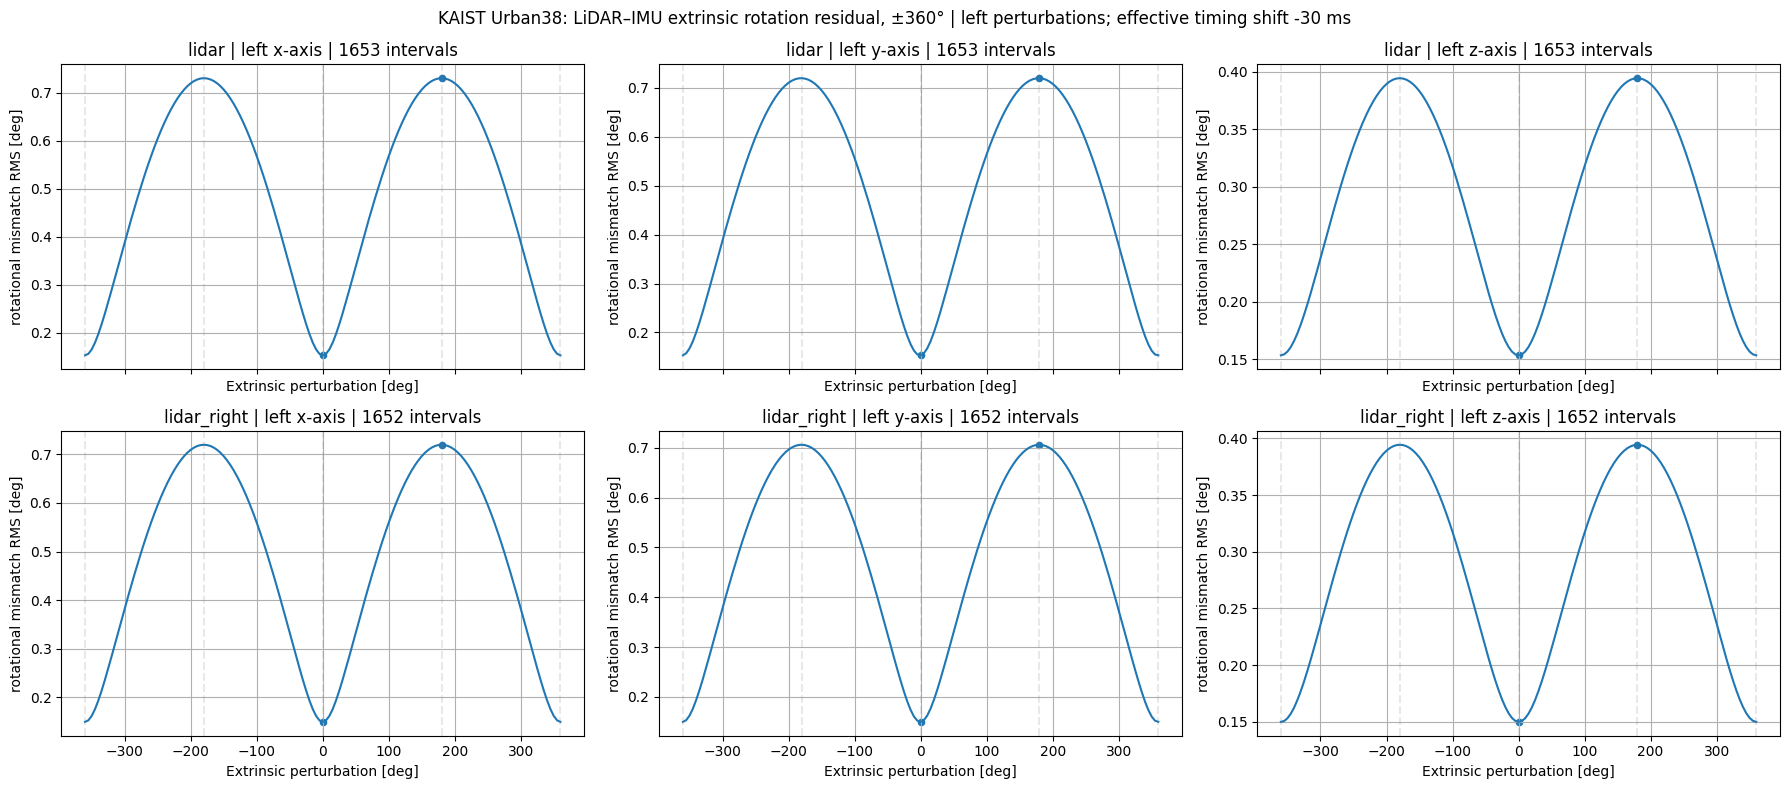

In [6]:
from scipy.spatial.transform import Rotation, Slerp

ROT_SWEEP_SEQUENCE = "Urban38"                   # Held-out sequence, not used for fitting.
ROT_SWEEP_NUM_WINDOWS = 35                       # Increase to 80 for smoother aggregate curves.
ROT_SWEEP_GRID_DEG = np.arange(-360.0, 360.0 + 1e-9, 5.0)
ROT_SWEEP_LIDAR_TIME_CORRECTION_S = -0.030       # Empirical effective timing shift (~-30 ms), NOT a proven clock ground truth.
ROT_SWEEP_AXES = np.eye(3)                      # World/body-frame LEFT extrinsic perturbations; matches training convention.
ROT_SWEEP_DATASETS = {**{name: train_dataset for name in TRAIN_NAMES}, **{name: val_dataset for name in VAL_NAMES}, **{name: test_dataset for name in TEST_NAMES}}


def _gyro_integrated_orientation(gyro_t, gyro_w):
    """Piecewise gyro integration, with SO(3) interpolation at LiDAR endpoint times."""
    dt = np.diff(gyro_t)
    if np.any(dt <= 0): raise ValueError("Gyro timestamps must be strictly increasing.")
    increments = Rotation.from_rotvec(0.5 * (gyro_w[:-1] + gyro_w[1:]) * dt[:, None])
    quats = np.empty((len(gyro_t), 4), dtype=np.float64)
    R = Rotation.identity()
    quats[0] = R.as_quat()
    for j in range(len(dt)):
        R = R * increments[j]
        quats[j + 1] = R.as_quat()
    return Slerp(gyro_t, Rotation.from_quat(quats))


def _prepare_motion_alignment(window, lidar_key):
    '''Align valid, batched IMU and LiDAR motion intervals in the body frame.'''
    gy = window.streams["gyro"]
    li = window.streams[lidar_key]
    cal_i = window.current_calibration["imu"]
    cal_l = window.current_calibration[lidar_key]

    imu_mask = gy.sample_mask[0].detach().cpu().numpy().astype(bool)
    lidar_mask = li.sample_mask[0].detach().cpu().numpy().astype(bool)

    t_i = gy.timestamps[0].detach().cpu().numpy().astype(np.float64)[imu_mask] + float(cal_i.time_offset[0, 0])
    w_i = gy.values[0].detach().cpu().numpy().astype(np.float64)[imu_mask]

    t0 = li.interval_start_timestamps[0].detach().cpu().numpy().astype(np.float64)[lidar_mask] + float(cal_l.time_offset[0, 0]) + ROT_SWEEP_LIDAR_TIME_CORRECTION_S
    t1 = li.timestamps[0].detach().cpu().numpy().astype(np.float64)[lidar_mask] + float(cal_l.time_offset[0, 0]) + ROT_SWEEP_LIDAR_TIME_CORRECTION_S
    dR_l = li.values[0].detach().cpu().numpy().astype(np.float64)[lidar_mask, :3, :3]

    if len(t_i) < 2 or np.any(np.diff(t_i) <= 0):
        return None

    # Use the same valid LiDAR intervals at every candidate rotation.
    valid_intervals = (t0 >= t_i[0]) & (t1 <= t_i[-1]) & (t1 > t0)

    if np.count_nonzero(valid_intervals) < 5:
        return None

    t0, t1, dR_l = t0[valid_intervals], t1[valid_intervals], dR_l[valid_intervals]

    orientation = _gyro_integrated_orientation(t_i, w_i)
    dR_i = (orientation(t0).inv() * orientation(t1)).as_matrix()

    R_B_I = cal_i.transform[0, :3, :3].detach().cpu().numpy().astype(np.float64)
    R_B_L = cal_l.transform[0, :3, :3].detach().cpu().numpy().astype(np.float64)

    return R_B_I @ dR_i @ R_B_I.T, dR_l, R_B_L


def _one_rotation_landscape(window, lidar_key, axis, angles_deg):
    prepared = _prepare_motion_alignment(window, lidar_key)
    if prepared is None: return None
    dR_imu, dR_lidar, R_B_L = prepared
    Q = Rotation.from_rotvec(np.deg2rad(angles_deg)[:, None] * axis[None, :]).as_matrix()
    # TRAINING CONVENTION: left perturbation R'_B_L = Exp(alpha*[axis]x) @ R_B_L.
    R_trial = Q @ R_B_L
    dR_trial = R_trial[:, None] @ dR_lidar[None, :, :, :] @ R_trial[:, None, :, :].transpose(0, 1, 3, 2)
    residual_R = dR_trial.transpose(0, 1, 3, 2) @ dR_imu[None, :, :, :]
    error_angles = Rotation.from_matrix(residual_R.reshape(-1, 3, 3)).magnitude().reshape(len(angles_deg), -1)
    return (error_angles ** 2).sum(axis=1), error_angles.shape[1]


def plot_rotation_landscape(sequence_name=ROT_SWEEP_SEQUENCE, num_windows=ROT_SWEEP_NUM_WINDOWS):
    dataset = ROT_SWEEP_DATASETS[sequence_name]
    indices = list(dataset.window_indices_for_sequence(sequence_name))[:num_windows]
    if not indices: raise ValueError(f"No windows from {sequence_name}")
    fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=True)
    curves = {}
    for row, lidar_key in enumerate(("lidar", "lidar_right")):
        for axis_index, axis_name in enumerate(("x", "y", "z")):
            sums = np.zeros(len(ROT_SWEEP_GRID_DEG), dtype=np.float64)
            total_intervals = 0
            for index in indices:
                window = collate_windows([dataset[index]])
                values = _one_rotation_landscape(window, lidar_key, ROT_SWEEP_AXES[axis_index], ROT_SWEEP_GRID_DEG)
                if values is None: continue
                error_sums, count = values
                sums += error_sums
                total_intervals += count
            if total_intervals == 0: raise RuntimeError(f"No intervals for {lidar_key} axis {axis_name}")
            rms_deg = np.rad2deg(np.sqrt(sums / total_intervals))
            curves[(lidar_key, axis_name)] = rms_deg
            ax = axes[row, axis_index]
            ax.plot(ROT_SWEEP_GRID_DEG, rms_deg)
            for mark in (-360, -180, 0, 180, 360): ax.axvline(mark, color="grey", alpha=0.18, linestyle="--")
            ax.scatter([0, 180], [rms_deg[np.argmin(abs(ROT_SWEEP_GRID_DEG - x))] for x in (0, 180)], s=20)
            ax.set_title(f"{lidar_key} | left {axis_name}-axis | {total_intervals} intervals")
            ax.set_ylabel("rotational mismatch RMS [deg]"); ax.set_xlabel("Extrinsic perturbation [deg]")
            ax.grid(True)
            j0 = np.argmin(abs(ROT_SWEEP_GRID_DEG))
            j180 = np.argmin(abs(ROT_SWEEP_GRID_DEG - 180))
            jbest = int(np.argmin(rms_deg))
            print(f"{lidar_key:12s} axis={axis_name} | E(0)={rms_deg[j0]:.5f}°, E(180)={rms_deg[j180]:.5f}°, best={ROT_SWEEP_GRID_DEG[jbest]:+.1f}° | 180/0={rms_deg[j180] / max(rms_deg[j0],1e-8):.5f}")
            # Physical periodicity. +/-360 are the same SO(3) rotation as 0.
            assert np.allclose(rms_deg[0], rms_deg[-1], atol=1e-4)
    fig.suptitle(f"KAIST {sequence_name}: LiDAR–IMU extrinsic rotation residual, ±360° | left perturbations; effective timing shift {1000*ROT_SWEEP_LIDAR_TIME_CORRECTION_S:+.0f} ms")
    fig.tight_layout(); plt.show()
    return curves

rotation_landscape_curves = plot_rotation_landscape()


Urban38 | imu z | 80 windows
  Baseline aggregate RMS at 0°: 0.14852 deg
    angle    aggregate ΔRMS    median window ΔRMS     windows E(angle)>E(0)
       5°        +0.00107°            +0.00053°                   77.5%
      10°        +0.00421°            +0.00179°                   83.8%
      30°        +0.03369°            +0.01335°                   90.0%
      60°        +0.10367°            +0.04469°                   97.5%
     100°        +0.19721°            +0.09339°                   98.8%
     150°        +0.27218°            +0.13341°                   97.5%
     170°        +0.28373°            +0.13963°                   97.5%
     180°        +0.28518°            +0.14039°                   98.8%

Urban38 | lidar x | 80 windows
  Baseline aggregate RMS at 0°: 0.14386 deg
    angle    aggregate ΔRMS    median window ΔRMS     windows E(angle)>E(0)
       5°        +0.00417°            +0.00024°                   66.2%
      10°        +0.01644°            +0.00178°   

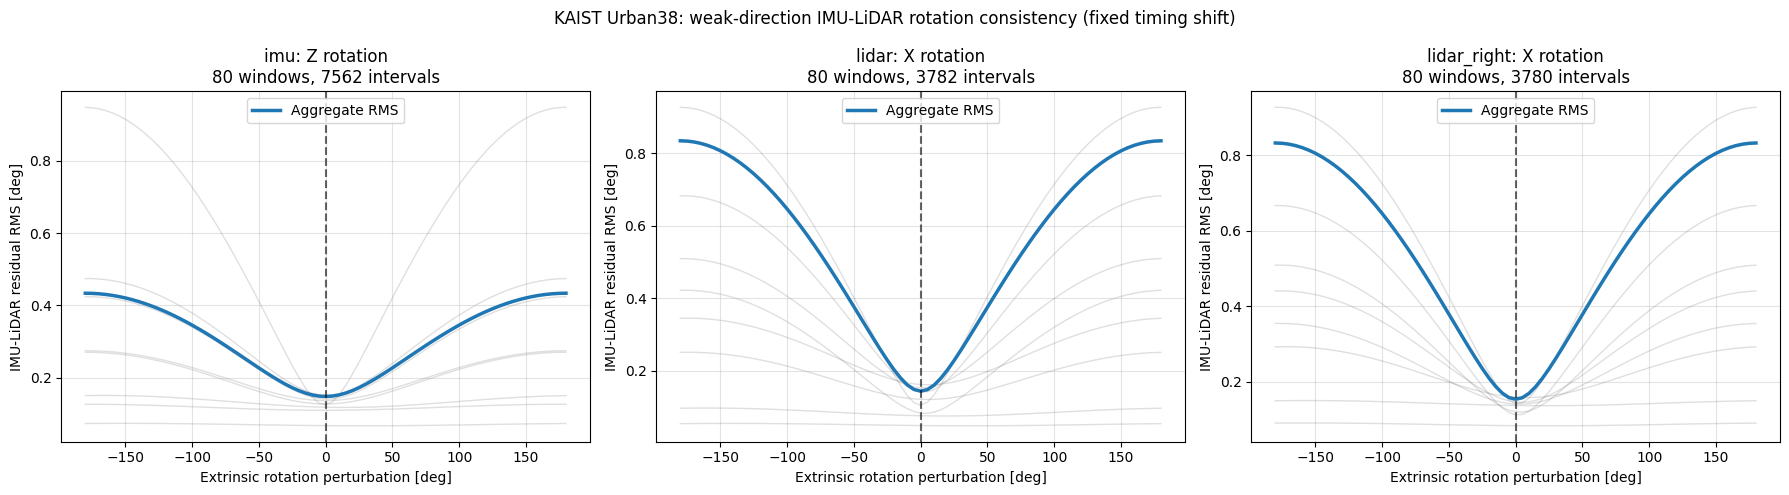

In [44]:
# Run after notebook 25 Section 3a, which defines _prepare_motion_alignment,
# ROT_SWEEP_DATASETS, and _gyro_integrated_orientation.
# No model, checkpoint, augmentation, or optimizer is used here.

WEAK_RESIDUAL_SEQUENCE = "Urban38"
WEAK_RESIDUAL_NUM_WINDOWS = 80
WEAK_RESIDUAL_GRID_DEG = np.arange(-180.0, 180.0 + 1e-9, 5.0)
WEAK_RESIDUAL_DISPLAY_WINDOWS = 8
WEAK_RESIDUAL_CASES = (("imu", "z"), ("lidar", "x"), ("lidar_right", "x"))


def _weak_rotation_residual_for_window(window, calibration_key, angles_deg):
    '''Return mean squared IMU-LiDAR SO(3) mismatch in deg^2 at each candidate angle.'''
    lidar_keys = ("lidar", "lidar_right") if calibration_key == "imu" else (calibration_key,)
    axis = np.array((0.0, 0.0, 1.0) if calibration_key == "imu" else (1.0, 0.0, 0.0))
    Q = Rotation.from_rotvec(np.deg2rad(angles_deg)[:, None] * axis[None, :]).as_matrix()
    sq_error_sum = np.zeros(len(angles_deg), dtype=np.float64)
    num_intervals = 0

    for lidar_key in lidar_keys:
        prepared = _prepare_motion_alignment(window, lidar_key)
        if prepared is None:
            continue

        dR_imu, dR_lidar, R_B_L = prepared
        dR_lidar_body = R_B_L @ dR_lidar @ R_B_L.T

        # Left-multiply the *chosen sensor's* extrinsic, leaving the other sensors fixed.
        if calibration_key == "imu":
            dR_imu_trial = Q[:, None] @ dR_imu[None] @ Q[:, None].transpose(0, 1, 3, 2)
            residual_R = dR_lidar_body[None].transpose(0, 1, 3, 2) @ dR_imu_trial
        else:
            dR_lidar_trial = Q[:, None] @ dR_lidar_body[None] @ Q[:, None].transpose(0, 1, 3, 2)
            residual_R = dR_lidar_trial.transpose(0, 1, 3, 2) @ dR_imu[None]

        residual_angle_deg = np.rad2deg(Rotation.from_matrix(residual_R.reshape(-1, 3, 3)).magnitude())
        residual_angle_deg = residual_angle_deg.reshape(len(angles_deg), -1)
        sq_error_sum += np.sum(residual_angle_deg ** 2, axis=1)
        num_intervals += residual_angle_deg.shape[1]

    return None if num_intervals == 0 else (sq_error_sum / num_intervals, num_intervals)


def plot_weak_rotation_residuals(sequence_name=WEAK_RESIDUAL_SEQUENCE, num_windows=WEAK_RESIDUAL_NUM_WINDOWS):
    '''Compare aggregate and individual-window rotational consistency along weak axes.'''
    dataset = ROT_SWEEP_DATASETS[sequence_name]
    indices = list(dataset.window_indices_for_sequence(sequence_name))[:num_windows]
    if not indices:
        raise ValueError(f"No windows found for {sequence_name}")

    angles_deg = WEAK_RESIDUAL_GRID_DEG
    zero_index = int(np.argmin(np.abs(angles_deg)))
    fig, axes = plt.subplots(1, len(WEAK_RESIDUAL_CASES), figsize=(18, 5), sharex=True)
    results = {}

    for ax, (calibration_key, axis_name) in zip(axes, WEAK_RESIDUAL_CASES):
        window_squared_errors, interval_weights, window_ids = [], [], []

        for index in indices:
            window = collate_windows([dataset[int(index)]])
            result = _weak_rotation_residual_for_window(window, calibration_key, angles_deg)
            if result is None:
                continue
            sq_errors, n_intervals = result
            window_squared_errors.append(sq_errors)
            interval_weights.append(n_intervals)
            window_ids.append(int(index))

        if not window_squared_errors:
            raise RuntimeError(f"No usable intervals for {sequence_name}, {calibration_key}")

        sq_errors = np.stack(window_squared_errors)  # [W, candidate angles]
        weights = np.asarray(interval_weights, dtype=np.float64)
        aggregate_rms = np.sqrt(np.average(sq_errors, axis=0, weights=weights))
        per_window_rms = np.sqrt(sq_errors)

        for row_index in np.linspace(0, len(per_window_rms) - 1, min(WEAK_RESIDUAL_DISPLAY_WINDOWS, len(per_window_rms)), dtype=int):
            ax.plot(angles_deg, per_window_rms[row_index], color="gray", alpha=0.25, linewidth=1)

        ax.plot(angles_deg, aggregate_rms, linewidth=2.5, label="Aggregate RMS")
        ax.axvline(0.0, color="black", linestyle="--", alpha=0.6)
        ax.set_title(f"{calibration_key}: {axis_name.upper()} rotation\n{len(per_window_rms)} windows, {int(weights.sum())} intervals")
        ax.set_xlabel("Extrinsic rotation perturbation [deg]")
        ax.set_ylabel("IMU-LiDAR residual RMS [deg]")
        ax.grid(True, alpha=0.35)
        ax.legend()

        print(f"\n{sequence_name} | {calibration_key} {axis_name} | {len(per_window_rms)} windows")
        print(f"  Baseline aggregate RMS at 0°: {aggregate_rms[zero_index]:.5f} deg")
        print(f"  {'angle':>7}  {'aggregate ΔRMS':>16}  {'median window ΔRMS':>20}  {'windows E(angle)>E(0)':>24}")
        for angle in (5, 10, 30, 60, 100, 150, 170, 180):
            angle_index = int(np.argmin(np.abs(angles_deg - angle)))
            rms_delta = aggregate_rms[angle_index] - aggregate_rms[zero_index]
            # Compare squared residuals to avoid mistaking a higher noise floor for observability.
            sq_delta = sq_errors[:, angle_index] - sq_errors[:, zero_index]
            median_rms_delta = np.median(per_window_rms[:, angle_index] - per_window_rms[:, zero_index])
            positive_fraction = np.mean(sq_delta > 0.0)
            print(f"  {angle:6.0f}° {rms_delta:+15.5f}° {median_rms_delta:+19.5f}° {positive_fraction:23.1%}")

        results[(calibration_key, axis_name)] = {
            "angles_deg": angles_deg.copy(),
            "aggregate_rms_deg": aggregate_rms,
            "window_rms_deg": per_window_rms,
            "window_ids": window_ids,
            "num_intervals": weights,
        }

    fig.suptitle(f"KAIST {sequence_name}: weak-direction IMU-LiDAR rotation consistency (fixed timing shift)")
    fig.tight_layout()
    plt.show()
    return results


weak_rotation_residual_results = plot_weak_rotation_residuals()

## 4. Shared context augmentation and paired prior sampler


In [7]:
# First augment the physical context once, BEFORE splitting the +/- prior pair.
# The generic prior sampler stays disabled to avoid perturbing the shared truth.
context_augmentation_config = AugmentationConfig(
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True,
        probability=1.0,
        rotation_probability=1.0,
        translation_probability=0.0,
        time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(30.0)),
        time_offset=PerturbationMagnitudeConfig(maximum=0.03),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False, probability=1.0, rotation=PerturbationMagnitudeConfig(maximum=PAIR_ROTATION_MAX_RAD), translation=PerturbationMagnitudeConfig(maximum=PAIR_TRANSLATION_MAX_M), time_offset=PerturbationMagnitudeConfig(maximum=PAIR_TIME_OFFSET_MAX_S), one_calibration_per_sample=True, one_rotation_axis_per_sample=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

# Familiar examples use exactly the same fine/coarse settings as 002.10.
# The targeted 60–170 degree sampler is defined below, without changing the augmentation modules.
coarse_pair_prior_config = PriorPerturbationConfig(
    enabled=True,
    probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=COARSE_ROTATION_MAX_RAD, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=COARSE_ROTATION_SCALE_RAD, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=COARSE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=COARSE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True,
    one_rotation_axis_per_sample=False,
    one_perturbation_type_per_sample=False,
)

fine_pair_prior_config = PriorPerturbationConfig(
    enabled=True,
    probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=FINE_ROTATION_MAX_RAD, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_ROTATION_SCALE_RAD, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=FINE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True,
    one_rotation_axis_per_sample=False,
    one_perturbation_type_per_sample=False,
)

# Alias for older read-only helpers. The active sampler below chooses the regime per sample.
pair_prior_config = coarse_pair_prior_config
context_augmentation_pipeline = AugmentationPipeline(context_augmentation_config)
coarse_pair_prior_perturber = CalibrationPriorPerturber(coarse_pair_prior_config)
fine_pair_prior_perturber = CalibrationPriorPerturber(fine_pair_prior_config)

print("Shared physical/context augmentation:", context_augmentation_config)
print("Fine paired priors:", fine_pair_prior_config)
print("Coarse paired priors:", coarse_pair_prior_config)


Shared physical/context augmentation: AugmentationConfig(sampling_rate=SamplingRateAugmentationConfig(enabled=False, minimum_imu_frequency_hz=None, minimum_lidar_frequency_hz=None, imu_probability=1.0, lidar_probability=1.0), frame_randomization=FrameRandomizationConfig(enabled=False), prior_perturbation=PriorPerturbationConfig(enabled=False, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=2.9670597283903604, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), translation=PerturbationMagnitudeConfig(maximum=0.02, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), time_offset=PerturbationMagnitudeConfig(maximum=0.5, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False), calibration_event=CalibrationEventConfig(enabled

## 5. Pooled model and complete window pipeline


In [8]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(
        n_heads=POOLER_N_HEADS,
        dropout=POOLER_DROPOUT,
        calibration_context_dim=0,           # CALIBRATION_CONTEXT_DIM
    ),

    head=PooledCalibrationHeadConfig(
        calibration_context_dim=0,
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
calibration_updater = CalibrationUpdater()
window_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=model, calibration_updater=calibration_updater)

# if not getattr(model, "uses_calibration_context", False):
#     raise RuntimeError("This experiment requires the pooled model to use numeric calibration context.")

print(model)
print()
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print("Head calibration context dim:", model.head.config.calibration_context_dim)


PooledCalibrationModel(
  (transformer_encoder): SummaryTokenTransformerEncoder(
    (input_projection): Linear(in_features=8, out_features=128, bias=True)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=512, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (linear2): Linear(in_features=512, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): Dropout(p=0.0, inplace=False)
        )
      )
    )
  )
  (pooler): CalibrationPooler(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQ

## 6. Paired-window construction helpers


In [9]:
def make_augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(seed)


def clone_window_with_calibration(window: WindowBatch, calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)


def sample_large_rotation_deltas(true_calibration, *, generator, sample_tau=True):
    """Exactly one perturbed sensor per example, random 3D axis, 60–170° in balanced bands."""
    first_state = next(iter(true_calibration.values()))
    batch_size, device, dtype = first_state.transform.shape[0], first_state.transform.device, first_state.transform.dtype
    sensor_choice = torch.randint(len(CALIBRATION_KEYS), (batch_size,), generator=generator, device=device)
    band_index = torch.randint(len(LARGE_ROTATION_BANDS_DEG), (batch_size,), generator=generator, device=device)
    bands = torch.tensor(LARGE_ROTATION_BANDS_DEG, dtype=dtype, device=device)
    angle_deg = bands[band_index, 0] + torch.rand(batch_size, generator=generator, device=device, dtype=dtype) * (bands[band_index, 1] - bands[band_index, 0])
    axes = torch.randn(batch_size, 3, generator=generator, device=device, dtype=dtype)
    axes = axes / torch.linalg.vector_norm(axes, dim=-1, keepdim=True).clamp_min(1e-9)
    # Half the large samples are EXACTLY along one coordinate axis, balanced in x/y/z.
    # Pure LiDAR-x error has zero probability under random isotropic axes alone.
    aligned = torch.rand(batch_size, generator=generator, device=device) < LARGE_AXIS_ALIGNED_PROBABILITY
    axis_number = torch.randint(3, (batch_size,), generator=generator, device=device)
    axis_sign = 2 * torch.randint(2, (batch_size,), generator=generator, device=device) - 1
    canonical_axis = F.one_hot(axis_number, num_classes=3).to(dtype=dtype) * axis_sign[:, None].to(dtype=dtype)
    axes = torch.where(aligned[:, None], canonical_axis, axes)
    rotation = axes * torch.deg2rad(angle_deg)[:, None]

    delta_xi = {key: torch.zeros(batch_size, 6, dtype=dtype, device=device) for key in true_calibration}
    delta_tau = {key: torch.zeros(batch_size, 1, dtype=dtype, device=device) for key in true_calibration}

    if sample_tau:
        from obscalib.augmentations.sampling import sample_signed_scalar_perturbation
        tau_error = sample_signed_scalar_perturbation(config=coarse_pair_prior_config.time_offset, batch_size=batch_size, device=device, dtype=dtype, generator=generator)
    else:
        tau_error = torch.zeros(batch_size, 1, dtype=dtype, device=device)

    for key_index, key in enumerate(CALIBRATION_KEYS):
        active = sensor_choice == key_index
        delta_xi[key][active, :3] = rotation[active]
        delta_tau[key][active] = tau_error[active]

    return delta_xi, delta_tau, band_index


def sample_pair_prior_deltas(true_calibration, *, generator: torch.Generator, distribution: str = "mixed"):
    """Per-example mixture; familiar is copied from 002.10, large is stratified in SO(3)."""
    if distribution not in ("mixed", "familiar", "fine", "coarse", "large", "large_rotation_only"):
        raise ValueError(f"Unknown prior distribution: {distribution!r}")
    first_state = next(iter(true_calibration.values()))
    B, device = first_state.transform.shape[0], first_state.transform.device

    if distribution in ("fine", "coarse", "familiar", "mixed"):
        _, fine_xi, fine_tau = fine_pair_prior_perturber(true_calibration, generator=generator)
        _, coarse_xi, coarse_tau = coarse_pair_prior_perturber(true_calibration, generator=generator)
        is_fine = torch.rand(B, device=device, generator=generator) < FINE_PRIOR_PROBABILITY
        familiar_xi = {key: torch.where(is_fine[:, None], fine_xi[key], coarse_xi[key]) for key in CALIBRATION_KEYS}
        familiar_tau = {key: torch.where(is_fine[:, None], fine_tau[key], coarse_tau[key]) for key in CALIBRATION_KEYS}
        if distribution == "fine": return fine_xi, fine_tau, torch.ones(B, dtype=torch.bool, device=device)
        if distribution == "coarse": return coarse_xi, coarse_tau, torch.ones(B, dtype=torch.bool, device=device)
        if distribution == "familiar": return familiar_xi, familiar_tau, torch.ones(B, dtype=torch.bool, device=device)
    if distribution in ("large", "large_rotation_only"):
        large_xi, large_tau, _ = sample_large_rotation_deltas(true_calibration, generator=generator, sample_tau=(distribution == "large" and LARGE_TIME_OFFSET_ENABLED))
        return large_xi, large_tau, torch.zeros(B, dtype=torch.bool, device=device)

    large_xi, large_tau, _ = sample_large_rotation_deltas(true_calibration, generator=generator, sample_tau=LARGE_TIME_OFFSET_ENABLED)
    is_familiar = torch.rand(B, device=device, generator=generator) < FAMILIAR_PRIOR_PROBABILITY
    xi = {key: torch.where(is_familiar[:, None], familiar_xi[key], large_xi[key]) for key in CALIBRATION_KEYS}
    tau = {key: torch.where(is_familiar[:, None], familiar_tau[key], large_tau[key]) for key in CALIBRATION_KEYS}
    return xi, tau, is_familiar


def make_paired_windows(base_window: WindowBatch, *, generator: torch.Generator, return_truth_window: bool = False, distribution: str = "mixed"):
    # Shared physical context for the two branches. The center must be actual augmented truth.
    context_window = context_augmentation_pipeline(base_window, generator=generator).augmented_window
    truth = context_window.current_calibration
    delta_xi, delta_tau, _ = sample_pair_prior_deltas(truth, generator=generator, distribution=distribution)
    plus = apply_prior_perturbation(truth, delta_xi, delta_tau)
    minus = apply_prior_perturbation(truth, {key: -value for key, value in delta_xi.items()}, {key: -value for key, value in delta_tau.items()})
    w_plus = clone_window_with_calibration(context_window, plus)
    w_minus = clone_window_with_calibration(context_window, minus)
    if return_truth_window: return w_plus, w_minus, context_window, delta_xi, delta_tau
    return w_plus, w_minus, delta_xi, delta_tau


def correction_target(window: WindowBatch, calibration_key: str):
    if window.targets is None: raise ValueError("Missing ground-truth calibration target")
    target = window.targets[calibration_key]
    current_state = window.current_calibration[calibration_key]
    return se3_log(target.next_transform @ torch.linalg.inv(current_state.transform)), target.next_time_offset - current_state.time_offset

## 7. Pair-construction semantic test


In [10]:
semantic_base_window = next(iter(train_loader))
semantic_base_window = window_batch_to(semantic_base_window, DEVICE, dtype=MODEL_DTYPE)
semantic_generator = make_augmentation_generator(TRAIN_PAIR_SEED + 1)
semantic_positive_window, semantic_negative_window, semantic_delta_xi, semantic_delta_tau = make_paired_windows(semantic_base_window, generator=semantic_generator)

for stream_key in semantic_positive_window.streams:
    torch.testing.assert_close(semantic_positive_window.streams[stream_key].values, semantic_negative_window.streams[stream_key].values)
    torch.testing.assert_close(semantic_positive_window.streams[stream_key].timestamps, semantic_negative_window.streams[stream_key].timestamps)

for calibration_key in CALIBRATION_KEYS:
    positive_target_xi, positive_target_tau = correction_target(semantic_positive_window, calibration_key)
    negative_target_xi, negative_target_tau = correction_target(semantic_negative_window, calibration_key)

    # For T_prior = Exp(+delta) @ T_true, the desired correction is -delta.
    torch.testing.assert_close(positive_target_xi, -semantic_delta_xi[calibration_key], atol=1e-5, rtol=1e-4)
    torch.testing.assert_close(negative_target_xi, semantic_delta_xi[calibration_key], atol=1e-5, rtol=1e-4)
    torch.testing.assert_close(positive_target_tau, -semantic_delta_tau[calibration_key], atol=1e-7, rtol=1e-6)
    torch.testing.assert_close(negative_target_tau, semantic_delta_tau[calibration_key], atol=1e-7, rtol=1e-6)

    torch.testing.assert_close(positive_target_xi + negative_target_xi, torch.zeros_like(positive_target_xi), atol=1e-5, rtol=1e-4)
    torch.testing.assert_close(positive_target_tau + negative_target_tau, torch.zeros_like(positive_target_tau), atol=1e-7, rtol=1e-6)

torch.cuda.empty_cache()

print("PAIR CONSTRUCTION CHECK: PASS")
print("The +delta and -delta branches share identical measurements and have opposite correction targets.")


PAIR CONSTRUCTION CHECK: PASS
The +delta and -delta branches share identical measurements and have opposite correction targets.


### Paired-sampler semantic and coverage test
The numerical targets must equal ± the sampled Lie algebra perturbations. For the targeted large-angle regime we also verify **one active sensor**, **zero translation**, **maximum 170°**, and occupancy of all four 60–170° bands.

In [11]:
SAMPLE_CHECK_B = 2048
sampler_states = {key: CalibrationState(transform=state.transform[:1].repeat(SAMPLE_CHECK_B, 1, 1), time_offset=state.time_offset[:1].repeat(SAMPLE_CHECK_B, 1)) for key, state in semantic_positive_window.current_calibration.items()}
sampler_xi, sampler_tau, _ = sample_pair_prior_deltas(sampler_states, generator=make_augmentation_generator(TRAIN_PAIR_SEED + 3001), distribution="large")
active = sum((torch.linalg.vector_norm(sampler_xi[key][:, :3], dim=-1) > 1e-7).int() for key in CALIBRATION_KEYS)
assert torch.all(active == 1), "Exactly one sensor must have a rotation error."
active_angles = torch.cat([torch.rad2deg(torch.linalg.vector_norm(sampler_xi[key][:, :3], dim=-1))[torch.linalg.vector_norm(sampler_xi[key][:, :3], dim=-1) > 1e-7] for key in CALIBRATION_KEYS])
assert active_angles.numel() == SAMPLE_CHECK_B
assert float(active_angles.min()) >= 60.0 - 1e-4 and float(active_angles.max()) <= 170.0 + 1e-4
for key in CALIBRATION_KEYS:
    assert torch.all(sampler_xi[key][:, 3:] == 0.0)
    assert torch.all(sampler_tau[key].abs() <= COARSE_TIME_OFFSET_MAX_S + 1e-6)
for low, high in LARGE_ROTATION_BANDS_DEG:
    count = int(((active_angles >= low) & (active_angles <= high)).sum())
    assert count > SAMPLE_CHECK_B * 0.15, f"Large-angle band {low}-{high} severely undersampled: {count}"
    print(f"  [{low:3.0f}, {high:3.0f}]°: {count:4d} / {SAMPLE_CHECK_B}")
print("LARGE-ANGLE SAMPLER CHECK: PASS | max", float(active_angles.max()), "degrees")
del sampler_xi, sampler_tau, sampler_states, active, active_angles

  [ 60,  90]°:  525 / 2048
  [ 90, 120]°:  510 / 2048
  [120, 150]°:  520 / 2048
  [150, 170]°:  493 / 2048
LARGE-ANGLE SAMPLER CHECK: PASS | max 169.98635864257812 degrees


## 8. Routing and pooled-output sanity check


In [12]:
def run_pooled_sanity(window):
    with torch.inference_mode():
        result = window_step(window)
        tokens = result.tokens
        tokens.validate()

        if tokens.calibration_ids is None:
            raise RuntimeError("Pooled calibration requires calibration_ids.")

        if tuple(tokens.calibration_keys) != CALIBRATION_KEYS:
            raise RuntimeError(
                f"Tokenizer calibration order {tuple(tokens.calibration_keys)} "
                f"does not match requested {CALIBRATION_KEYS}."
            )

        if tuple(result.model_output.predictions) != CALIBRATION_KEYS:
            raise RuntimeError(
                f"Prediction key order {tuple(result.model_output.predictions)} "
                f"does not match {CALIBRATION_KEYS}."
            )

        summary = {
            "token_shape": tuple(tokens.x.shape),
            "shared_feature_shape": (
                None
                if result.model_output.shared_features is None
                else tuple(result.model_output.shared_features.shape)
            ),
        }

        # Move only the tiny outputs needed for comparison to CPU.
        predictions = {
            calibration_key: {
                "delta_xi": prediction.delta_xi.detach().cpu(),
                "delta_tau": prediction.delta_tau.detach().cpu(),
            }
            for calibration_key, prediction in result.model_output.predictions.items()
        }

    return summary, predictions


previous_training_mode = model.training
model.eval()

positive_summary, positive_predictions = run_pooled_sanity(
    semantic_positive_window
)

negative_summary, negative_predictions = run_pooled_sanity(
    semantic_negative_window
)

model.train(previous_training_mode)


for result_name, summary in (
    ("positive", positive_summary),
    ("negative", negative_summary),
):
    print(result_name)
    print("  token shape:", summary["token_shape"])
    print(
        "  pooled/shared feature shape:",
        summary["shared_feature_shape"],
    )


print()

for calibration_key in CALIBRATION_KEYS:
    positive_prediction = positive_predictions[calibration_key]
    negative_prediction = negative_predictions[calibration_key]

    print(calibration_key)
    print(
        "  delta_xi:",
        tuple(positive_prediction["delta_xi"].shape),
    )
    print(
        "  delta_tau:",
        tuple(positive_prediction["delta_tau"].shape),
    )
    print(
        "  initial prediction separation xi:",
        float(
            torch.linalg.vector_norm(
                positive_prediction["delta_xi"]
                - negative_prediction["delta_xi"],
                dim=-1,
            ).mean()
        ),
    )


# These are CPU-only now.
del positive_predictions
del negative_predictions
del positive_summary
del negative_summary
del positive_prediction
del negative_prediction

torch.cuda.empty_cache()

positive
  token shape: (16, 1098, 8)
  pooled/shared feature shape: (16, 3, 128)
negative
  token shape: (16, 1098, 8)
  pooled/shared feature shape: (16, 3, 128)

imu
  delta_xi: (16, 6)
  delta_tau: (16, 1)
  initial prediction separation xi: 0.00043468878720887005
lidar
  delta_xi: (16, 6)
  delta_tau: (16, 1)
  initial prediction separation xi: 0.00047484473907388747
lidar_right
  delta_xi: (16, 6)
  delta_tau: (16, 1)
  initial prediction separation xi: 0.00047248805640265346


## 9. Regression and pair-difference losses


In [13]:
def correction_regression_loss(prediction, target):
    if CORRECTION_LOSS_TYPE == "mse":
        return F.mse_loss(prediction, target)
    if CORRECTION_LOSS_TYPE == "smooth_l1":
        return F.smooth_l1_loss(prediction, target, beta=1.0)
    if CORRECTION_LOSS_TYPE == "l1":
        return F.l1_loss(prediction, target)
    raise ValueError(f"Unknown CORRECTION_LOSS_TYPE={CORRECTION_LOSS_TYPE!r}.")


def compute_training_loss(window, model_output):
    total_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    num_calibrations = 0

    for calibration_key, prediction in model_output.predictions.items():
        target_delta_xi, target_delta_tau = correction_target(window, calibration_key)

        rotation_loss = correction_regression_loss(prediction.delta_xi[:, :3] / ROTATION_LOSS_SCALE_RAD, target_delta_xi[:, :3] / ROTATION_LOSS_SCALE_RAD)
        translation_loss = correction_regression_loss(prediction.delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        time_offset_loss = correction_regression_loss(prediction.delta_tau / TIME_OFFSET_LOSS_SCALE_S, target_delta_tau / TIME_OFFSET_LOSS_SCALE_S)

        calibration_loss = ROTATION_LOSS_WEIGHT * rotation_loss + TRANSLATION_LOSS_WEIGHT * translation_loss + TIME_OFFSET_LOSS_WEIGHT * time_offset_loss
        total_loss = total_loss + calibration_loss
        num_calibrations += 1

        rotation_error_rad = torch.linalg.vector_norm(prediction.delta_xi[:, :3] - target_delta_xi[:, :3], dim=-1)
        translation_error_m = torch.linalg.vector_norm(prediction.delta_xi[:, 3:] - target_delta_xi[:, 3:], dim=-1)
        time_offset_error_s = torch.abs(prediction.delta_tau[:, 0] - target_delta_tau[:, 0])

        metrics[f"{calibration_key}/rotation_error_deg"] = torch.rad2deg(rotation_error_rad).mean().item()
        metrics[f"{calibration_key}/translation_error_cm"] = (100.0 * translation_error_m).mean().item()
        metrics[f"{calibration_key}/time_offset_error_ms"] = (1000.0 * time_offset_error_s).mean().item()
        metrics[f"{calibration_key}/loss_rotation"] = rotation_loss.detach().item()
        metrics[f"{calibration_key}/loss_translation"] = translation_loss.detach().item()
        metrics[f"{calibration_key}/loss_time_offset"] = time_offset_loss.detach().item()

    if num_calibrations == 0:
        raise ValueError("Model produced no calibration predictions.")

    total_loss = total_loss / num_calibrations
    metrics["loss_total"] = total_loss.detach().item()
    return total_loss, metrics


def compute_pair_difference_loss(positive_window, positive_output, negative_window, negative_output):
    total_pair_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    num_calibrations = 0

    for calibration_key in CALIBRATION_KEYS:
        positive_prediction = positive_output.predictions[calibration_key]
        negative_prediction = negative_output.predictions[calibration_key]

        positive_target_xi, positive_target_tau = correction_target(positive_window, calibration_key)
        negative_target_xi, negative_target_tau = correction_target(negative_window, calibration_key)

        predicted_difference_xi = positive_prediction.delta_xi - negative_prediction.delta_xi
        target_difference_xi = positive_target_xi - negative_target_xi
        predicted_difference_tau = positive_prediction.delta_tau - negative_prediction.delta_tau
        target_difference_tau = positive_target_tau - negative_target_tau

        active_rotation_mask = torch.abs(target_difference_xi[:, :3]) > 1e-10

        if torch.any(active_rotation_mask):
            pair_rotation_loss = correction_regression_loss(predicted_difference_xi[:, :3][active_rotation_mask] / ROTATION_LOSS_SCALE_RAD, target_difference_xi[:, :3][active_rotation_mask] / ROTATION_LOSS_SCALE_RAD)
        else:
            pair_rotation_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)

        pair_translation_loss = correction_regression_loss(predicted_difference_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_difference_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        pair_time_offset_loss = correction_regression_loss(predicted_difference_tau / TIME_OFFSET_LOSS_SCALE_S, target_difference_tau / TIME_OFFSET_LOSS_SCALE_S)

        calibration_pair_loss = ROTATION_LOSS_WEIGHT * pair_rotation_loss + TRANSLATION_LOSS_WEIGHT * pair_translation_loss + TIME_OFFSET_LOSS_WEIGHT * pair_time_offset_loss
        total_pair_loss = total_pair_loss + calibration_pair_loss
        num_calibrations += 1

        metrics[f"{calibration_key}/pair_loss_rotation"] = pair_rotation_loss.detach().item()
        metrics[f"{calibration_key}/pair_loss_translation"] = pair_translation_loss.detach().item()
        metrics[f"{calibration_key}/pair_loss_time_offset"] = pair_time_offset_loss.detach().item()

    if num_calibrations == 0:
        raise ValueError("Model produced no calibration predictions.")

    total_pair_loss = total_pair_loss / num_calibrations
    metrics["loss_pair"] = total_pair_loss.detach().item()

    return total_pair_loss, metrics


def compute_paired_objective(positive_window, positive_output, negative_window, negative_output, truth_window=None, truth_output=None):
    positive_loss, positive_metrics = compute_training_loss(positive_window, positive_output)
    negative_loss, negative_metrics = compute_training_loss(negative_window, negative_output)
    pair_loss, pair_metrics = compute_pair_difference_loss(positive_window, positive_output, negative_window, negative_output)

    regular_loss = 0.5 * (positive_loss + negative_loss)

    if truth_window is not None or truth_output is not None:
        if truth_window is None or truth_output is None:
            raise ValueError("truth_window and truth_output must either both be provided or both be None.")

        truth_loss, truth_metrics = compute_training_loss(truth_window, truth_output)
    else:
        truth_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
        truth_metrics = {}

    total_loss = regular_loss + PAIR_LOSS_WEIGHT * pair_loss + TRUTH_ANCHOR_LOSS_WEIGHT * truth_loss

    metrics = {
        "loss_total": total_loss.detach().item(),
        "loss_regular": regular_loss.detach().item(),
        "loss_pair": pair_loss.detach().item(),
        "loss_truth": truth_loss.detach().item(),
    }

    for key in positive_metrics:
        if key == "loss_total":
            continue

        metrics[f"positive/{key}"] = positive_metrics[key]
        metrics[f"negative/{key}"] = negative_metrics[key]
        metrics[f"mean/{key}"] = 0.5 * (positive_metrics[key] + negative_metrics[key])

    for key, value in truth_metrics.items():
        if key != "loss_total":
            metrics[f"truth/{key}"] = value

    metrics.update({f"pair/{key}": value for key, value in pair_metrics.items()})

    return total_loss, metrics


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_REDUCTION_FACTOR, patience=LR_PATIENCE_EPOCHS)


In [14]:
from obscalib.augmentations.config import PerturbationMagnitudeConfig
from obscalib.augmentations.prior_perturbation import apply_prior_perturbation
from obscalib.augmentations.sampling import sample_signed_scalar_perturbation
from obscalib.geometry.lie import se3_log


DIRECTIONAL_CALIBRATION_KEY = "imu"
DIRECTIONAL_ROTATION_INDEX = 1  # phi_y
DIRECTIONAL_ROTATION_MAX_RAD = np.deg2rad(5.0)
DIRECTIONAL_PAIR_LOSS_WEIGHT = 10.0

directional_rotation_config = PerturbationMagnitudeConfig(
    maximum=DIRECTIONAL_ROTATION_MAX_RAD,
)


def make_directional_paired_windows(base_window: WindowBatch, *, generator: torch.Generator):
    """Development-only +/- pair with a single rotational prior-error coordinate."""

    # Keep the full shared physical augmentation, especially varying true calibration.
    context_result = context_augmentation_pipeline(base_window, generator=generator)
    context_window = context_result.augmented_window
    true_calibration = context_window.current_calibration

    delta_xi_by_key = {}
    delta_tau_by_key = {}

    for calibration_key, state in true_calibration.items():
        batch_size = state.transform.shape[0]
        device = state.transform.device
        dtype = state.transform.dtype

        delta_xi_by_key[calibration_key] = torch.zeros(batch_size, 6, device=device, dtype=dtype)
        delta_tau_by_key[calibration_key] = torch.zeros(batch_size, 1, device=device, dtype=dtype)

    selected_state = true_calibration[DIRECTIONAL_CALIBRATION_KEY]

    delta_rotation = sample_signed_scalar_perturbation(
        config=directional_rotation_config,
        batch_size=selected_state.transform.shape[0],
        device=selected_state.transform.device,
        dtype=selected_state.transform.dtype,
        generator=generator,
    )

    delta_xi_by_key[DIRECTIONAL_CALIBRATION_KEY][:, DIRECTIONAL_ROTATION_INDEX] = delta_rotation[:, 0]

    positive_prior = apply_prior_perturbation(
        true_calibration,
        delta_xi_by_key,
        delta_tau_by_key,
    )

    negative_prior = apply_prior_perturbation(
        true_calibration,
        {key: -value for key, value in delta_xi_by_key.items()},
        {key: -value for key, value in delta_tau_by_key.items()},
    )

    positive_window = clone_window_with_calibration(context_window, positive_prior)
    negative_window = clone_window_with_calibration(context_window, negative_prior)

    return positive_window, negative_window, delta_xi_by_key, delta_tau_by_key

In [15]:
def _directional_rotation_target(window: WindowBatch) -> torch.Tensor:
    current_state = window.current_calibration[DIRECTIONAL_CALIBRATION_KEY]
    target = window.targets[DIRECTIONAL_CALIBRATION_KEY]

    if target.next_transform is None:
        raise ValueError("Directional diagnostic requires next_transform supervision.")

    target_delta_transform = target.next_transform @ torch.linalg.inv(current_state.transform)
    target_delta_xi = se3_log(target_delta_transform)

    return target_delta_xi[:, DIRECTIONAL_ROTATION_INDEX]


def compute_directional_paired_objective(
    positive_window: WindowBatch,
    positive_output,
    negative_window: WindowBatch,
    negative_output,
):
    """Regular + strongly weighted pair loss for one selected rotation coordinate only."""

    positive_prediction = positive_output.predictions[DIRECTIONAL_CALIBRATION_KEY].delta_xi[:, DIRECTIONAL_ROTATION_INDEX]
    negative_prediction = negative_output.predictions[DIRECTIONAL_CALIBRATION_KEY].delta_xi[:, DIRECTIONAL_ROTATION_INDEX]

    positive_target = _directional_rotation_target(positive_window)
    negative_target = _directional_rotation_target(negative_window)

    positive_prediction_normalized = positive_prediction / ROTATION_LOSS_SCALE_RAD
    negative_prediction_normalized = negative_prediction / ROTATION_LOSS_SCALE_RAD
    positive_target_normalized = positive_target / ROTATION_LOSS_SCALE_RAD
    negative_target_normalized = negative_target / ROTATION_LOSS_SCALE_RAD

    loss_regular = 0.5 * (
        F.mse_loss(positive_prediction_normalized, positive_target_normalized)
        + F.mse_loss(negative_prediction_normalized, negative_target_normalized)
    )

    loss_pair = F.mse_loss(
        positive_prediction_normalized - negative_prediction_normalized,
        positive_target_normalized - negative_target_normalized,
    )

    loss_total = loss_regular + DIRECTIONAL_PAIR_LOSS_WEIGHT * loss_pair

    metrics = {
        "loss_total": loss_total.detach(),
        "loss_regular": loss_regular.detach(),
        "loss_pair": loss_pair.detach(),
    }

    return loss_total, metrics

In [16]:
from obscalib.augmentations.sampling import sample_isotropic_perturbation


SINGLE_SENSOR_3D_CALIBRATION_KEY = "lidar"

single_sensor_rotation_config = PerturbationMagnitudeConfig(
    maximum=np.deg2rad(5.0),
)


def make_single_sensor_3d_paired_windows(base_window: WindowBatch, *, generator: torch.Generator):
    """Development diagnostic: vary true calibration normally but perturb one sensor prior in full 3D rotation only."""

    context_result = context_augmentation_pipeline(base_window, generator=generator)
    context_window = context_result.augmented_window
    true_calibration = context_window.current_calibration

    delta_xi_by_key = {}
    delta_tau_by_key = {}

    for calibration_key, state in true_calibration.items():
        batch_size = state.transform.shape[0]

        delta_xi_by_key[calibration_key] = torch.zeros(
            batch_size,
            6,
            device=state.transform.device,
            dtype=state.transform.dtype,
        )

        delta_tau_by_key[calibration_key] = torch.zeros(
            batch_size,
            1,
            device=state.transform.device,
            dtype=state.transform.dtype,
        )

    selected_state = true_calibration[SINGLE_SENSOR_3D_CALIBRATION_KEY]

    delta_phi = sample_isotropic_perturbation(
        config=single_sensor_rotation_config,
        batch_size=selected_state.transform.shape[0],
        dimension=3,
        device=selected_state.transform.device,
        dtype=selected_state.transform.dtype,
        generator=generator,
    )

    delta_xi_by_key[SINGLE_SENSOR_3D_CALIBRATION_KEY][:, :3] = delta_phi

    positive_prior = apply_prior_perturbation(
        true_calibration,
        delta_xi_by_key,
        delta_tau_by_key,
    )

    negative_prior = apply_prior_perturbation(
        true_calibration,
        {key: -value for key, value in delta_xi_by_key.items()},
        {key: -value for key, value in delta_tau_by_key.items()},
    )

    positive_window = clone_window_with_calibration(
        context_window,
        positive_prior,
    )

    negative_window = clone_window_with_calibration(
        context_window,
        negative_prior,
    )

    return (
        positive_window,
        negative_window,
        delta_xi_by_key,
        delta_tau_by_key,
    )

## 10. Metric helpers


In [17]:
def accumulate_metrics(metric_sums, metrics, batch_size):
    for key, value in metrics.items():
        metric_sums[key] = metric_sums.get(key, 0.0) + float(value) * batch_size


def normalize_metrics(metric_sums, num_samples):
    if num_samples <= 0:
        raise ValueError("num_samples must be positive.")
    return {key: value / num_samples for key, value in metric_sums.items()}


## 11. One-batch paired gradient smoke test


In [18]:
from obscalib.calibration.context import calibration_state_to_context

context_test_base_window = next(iter(train_loader))
context_test_base_window = window_batch_to(
    context_test_base_window,
    DEVICE,
    dtype=MODEL_DTYPE,
)

context_test_generator = make_augmentation_generator(
    TRAIN_PAIR_SEED + 123
)

(
    context_test_positive_window,
    context_test_negative_window,
    _,
    _,
) = make_paired_windows(
    context_test_base_window,
    generator=context_test_generator,
)

positive_context = {
    calibration_key: calibration_state_to_context(state)
    for calibration_key, state
    in context_test_positive_window.current_calibration.items()
}

negative_context = {
    calibration_key: calibration_state_to_context(state)
    for calibration_key, state
    in context_test_negative_window.current_calibration.items()
}

model.eval()

with torch.inference_mode():
    # Generate tokens once.
    positive_step = window_step(
        context_test_positive_window
    )

    fixed_tokens = positive_step.tokens

    # Same exact measurement tokens, different numeric priors.
    output_positive_context = model(
        fixed_tokens,
        positive_context,
    )

    output_negative_context = model(
        fixed_tokens,
        negative_context,
    )

print("=" * 90)
print("CALIBRATION CONTEXT PATH CHECK")
print("=" * 90)

for calibration_key in CALIBRATION_KEYS:
    positive_prediction = (
        output_positive_context
        .predictions[calibration_key]
    )

    negative_prediction = (
        output_negative_context
        .predictions[calibration_key]
    )

    xi_separation = torch.linalg.vector_norm(
        positive_prediction.delta_xi
        - negative_prediction.delta_xi,
        dim=-1,
    ).mean()

    tau_separation = torch.abs(
        positive_prediction.delta_tau
        - negative_prediction.delta_tau
    ).mean()

    print(calibration_key)
    print(
        "  xi separation:",
        float(xi_separation.cpu()),
    )
    print(
        "  tau separation:",
        float(tau_separation.cpu()),
    )

del positive_step
del output_positive_context
del output_negative_context
del fixed_tokens
del context_test_base_window
del context_test_positive_window
del context_test_negative_window

torch.cuda.empty_cache()

CALIBRATION CONTEXT PATH CHECK
imu
  xi separation: 0.0
  tau separation: 0.0
lidar
  xi separation: 0.0
  tau separation: 0.0
lidar_right
  xi separation: 0.0
  tau separation: 0.0


In [19]:
# Paired gradient smoke test.
#
# Use a deliberately tiny batch. This test only verifies that the paired
# objective produces finite, nonzero gradients through the model. It does
# not need to reproduce the memory footprint of full training.

SMOKE_BATCH_SIZE = 2

previous_training_mode = model.training

try:
    torch.cuda.empty_cache()

    ##################################################
    # Tiny smoke batch
    ##################################################

    smoke_indices = np.linspace(
        0,
        len(train_dataset) - 1,
        SMOKE_BATCH_SIZE,
        dtype=int,
    )

    smoke_base_window = collate_windows(
        [
            train_dataset[int(index)]
            for index in smoke_indices
        ]
    )

    smoke_base_window = window_batch_to(
        smoke_base_window,
        DEVICE,
        dtype=MODEL_DTYPE,
    )

    smoke_generator = make_augmentation_generator(
        TRAIN_PAIR_SEED + 2
    )

    (
        smoke_positive_window,
        smoke_negative_window,
        _,
        _,
    ) = make_paired_windows(
        smoke_base_window,
        generator=smoke_generator,
    )

    ##################################################
    # Forward + backward
    ##################################################

    model.train()
    optimizer.zero_grad(set_to_none=True)

    smoke_positive_result = window_step(
        smoke_positive_window
    )

    smoke_negative_result = window_step(
        smoke_negative_window
    )

    smoke_loss, smoke_metrics = compute_paired_objective(
        smoke_positive_window,
        smoke_positive_result.model_output,
        smoke_negative_window,
        smoke_negative_result.model_output,
    )

    smoke_loss.backward()

    ##################################################
    # Gradient diagnostic
    ##################################################

    gradient_norm_squared = 0.0
    num_parameters_with_gradient = 0

    for parameter in model.parameters():
        if parameter.grad is None:
            continue

        parameter_gradient_norm = float(
            torch.linalg.vector_norm(
                parameter.grad.detach()
            ).cpu()
        )

        gradient_norm_squared += (
            parameter_gradient_norm ** 2
        )

        num_parameters_with_gradient += 1

    gradient_norm = (
        gradient_norm_squared ** 0.5
    )

    smoke_loss_value = float(
        smoke_loss.detach().cpu()
    )

    print(
        "Paired smoke loss:",
        smoke_loss_value,
    )

    print(
        "  regular:",
        smoke_metrics["loss_regular"],
    )

    print(
        "  pair:",
        smoke_metrics["loss_pair"],
    )

    print(
        "Gradient norm:",
        gradient_norm,
    )

    print(
        "Parameters with gradients:",
        num_parameters_with_gradient,
    )

    if not np.isfinite(smoke_loss_value):
        raise RuntimeError(
            "Paired smoke loss is not finite."
        )

    if (
        not np.isfinite(gradient_norm)
        or gradient_norm <= 0.0
    ):
        raise RuntimeError(
            "Pooled model did not receive a finite "
            "nonzero paired-training gradient."
        )

    print(
        "PAIRED GRADIENT SMOKE CHECK: PASS"
    )

finally:
    ##################################################
    # Remove gradients and all large graph references
    ##################################################

    optimizer.zero_grad(
        set_to_none=True
    )

    model.train(
        previous_training_mode
    )

    for variable_name in (
        "smoke_positive_result",
        "smoke_negative_result",
        "smoke_loss",
        "smoke_metrics",
        "smoke_positive_window",
        "smoke_negative_window",
        "smoke_base_window",
        "smoke_generator",
    ):
        if variable_name in globals():
            del globals()[variable_name]

    torch.cuda.empty_cache()

Paired smoke loss: 14.519685745239258
  regular: 9.579687118530273
  pair: 49.39999008178711
Gradient norm: 36.458711835092494
Parameters with gradients: 166
PAIRED GRADIENT SMOKE CHECK: PASS


## 12. Fixed paired small-batch overfit test

This is the direct counterpart of the successful fixed overfit test from notebook 16. It verifies that the new pair objective itself is trainable. Both branches and their perturbations are frozen here.


In [21]:
# FIXED_PAIR_OVERFIT_NUM_WINDOWS = min(BATCH_SIZE, 16)
# FIXED_PAIR_OVERFIT_NUM_STEPS = 400
# FIXED_PAIR_OVERFIT_PRINT_EVERY = 25
# FIXED_PAIR_OVERFIT_SEED = TRAIN_PAIR_SEED + 100000

# fixed_pair_indices = np.linspace(0, len(train_dataset) - 1, FIXED_PAIR_OVERFIT_NUM_WINDOWS, dtype=int)
# fixed_pair_base_window = collate_windows([train_dataset[int(index)] for index in fixed_pair_indices])
# fixed_pair_base_window = window_batch_to(fixed_pair_base_window, DEVICE, dtype=MODEL_DTYPE)

# fixed_pair_generator = make_augmentation_generator(FIXED_PAIR_OVERFIT_SEED)
# fixed_pair_positive_window, fixed_pair_negative_window, _, _ = make_paired_windows(fixed_pair_base_window, generator=fixed_pair_generator)

# fixed_pair_model_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
# fixed_pair_previous_training_mode = model.training
# fixed_pair_optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
# fixed_pair_history = []

# print("=" * 110)
# print("FIXED PAIRED SMALL-BATCH OVERFIT DIAGNOSTIC")
# print("=" * 110)
# torch.cuda.empty_cache()
# model.train()

# for step in range(FIXED_PAIR_OVERFIT_NUM_STEPS + 1):
#     fixed_pair_optimizer.zero_grad(set_to_none=True)

#     positive_result = window_step(fixed_pair_positive_window)
#     negative_result = window_step(fixed_pair_negative_window)
#     loss, metrics = compute_paired_objective(fixed_pair_positive_window, positive_result.model_output, fixed_pair_negative_window, negative_result.model_output)
#     fixed_pair_history.append(float(loss.detach()))

#     if step == 0 or step % FIXED_PAIR_OVERFIT_PRINT_EVERY == 0 or step == FIXED_PAIR_OVERFIT_NUM_STEPS:
#         print(f"step {step:4d}/{FIXED_PAIR_OVERFIT_NUM_STEPS} total={loss.item():9.6f} regular={metrics['loss_regular']:9.6f} pair={metrics['loss_pair']:9.6f}")

#     if step == FIXED_PAIR_OVERFIT_NUM_STEPS:
#         break

#     loss.backward()
#     if GRADIENT_CLIP_NORM is not None:
#         torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
#     fixed_pair_optimizer.step()

# fixed_pair_fraction_remaining = fixed_pair_history[-1] / fixed_pair_history[0]

# print()
# print(f"Initial loss: {fixed_pair_history[0]:.6f}")
# print(f"Final loss:   {fixed_pair_history[-1]:.6f}")
# print(f"Remaining:    {100.0 * fixed_pair_fraction_remaining:.2f}% of initial loss")
# print("FIXED PAIRED OVERFIT CHECK:", "PASS" if fixed_pair_fraction_remaining < 0.10 else "FAIL/WARNING")

# plt.figure(figsize=(10, 4))
# plt.plot(fixed_pair_history)
# plt.yscale("log")
# plt.xlabel("optimization step")
# plt.ylabel("paired objective")
# plt.title("Fixed paired small-batch overfit diagnostic")
# plt.grid(True)
# plt.show()

# model.load_state_dict(fixed_pair_model_state)
# model.train(fixed_pair_previous_training_mode)
# model.zero_grad(set_to_none=True)

# del fixed_pair_optimizer
# del fixed_pair_model_state
# torch.cuda.empty_cache()

## 13. Rotation-only large-angle stochastic learnability gate

Train on **16 fixed physical windows** with *fresh* large-angle (60–170°) paired priors each step, and no tau errors during this diagnostic. The evaluation pairs are fixed. This is deliberately a trainability check, **not** evidence of held-out generalization. The full training starts afresh from `002.10`, never from these temporary stochastic weights. A weak LiDAR X-axis can still remain ambiguous even if the aggregate gate passes.

step    1/500 | regular 3.9562, pair 36.5022 | imu rot 54.21° | lidar rot 16.78° | lidar_right rot 46.09°
step   25/500 | regular 3.5316, pair 34.6605 | imu rot 52.92° | lidar rot 15.35° | lidar_right rot 44.95°
step   50/500 | regular 3.3814, pair 32.5040 | imu rot 51.63° | lidar rot 14.12° | lidar_right rot 44.05°
step   75/500 | regular 3.2276, pair 30.1374 | imu rot 50.43° | lidar rot 12.89° | lidar_right rot 42.46°
step  100/500 | regular 3.0770, pair 28.4711 | imu rot 48.93° | lidar rot 12.69° | lidar_right rot 41.70°
step  125/500 | regular 2.8925, pair 26.5418 | imu rot 47.60° | lidar rot 12.68° | lidar_right rot 40.07°
step  150/500 | regular 2.7316, pair 24.8708 | imu rot 47.17° | lidar rot 12.72° | lidar_right rot 37.76°
step  175/500 | regular 2.5997, pair 23.4516 | imu rot 46.72° | lidar rot 12.43° | lidar_right rot 35.72°
step  200/500 | regular 2.5198, pair 22.2328 | imu rot 46.38° | lidar rot 12.54° | lidar_right rot 34.47°
step  225/500 | regular 2.4998, pair 21.4317 |

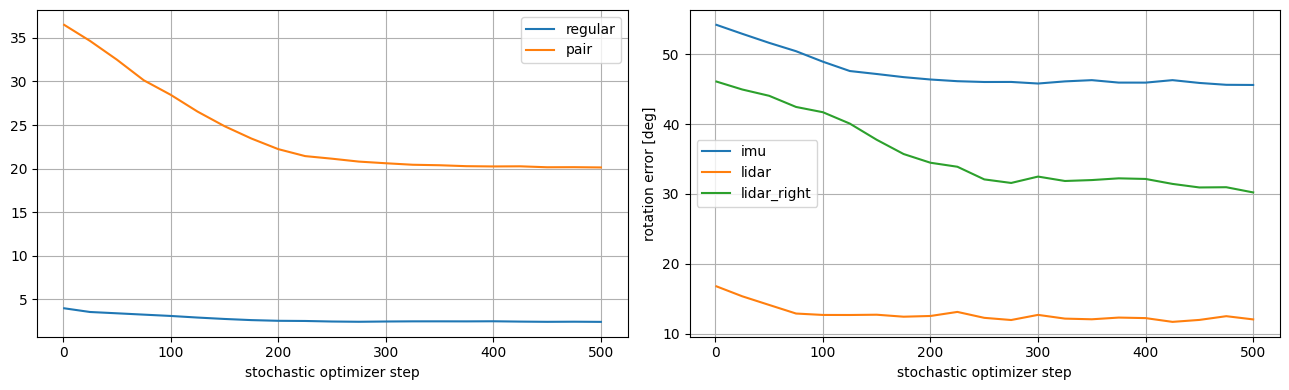

Full training enabled: True


In [24]:
STOCHASTIC_NUM_WINDOWS = min(16, BATCH_SIZE)
STOCHASTIC_NUM_STEPS = 500
STOCHASTIC_PRINT_EVERY = 25
STOCHASTIC_SEED = TRAIN_PAIR_SEED + 220000
STOCHASTIC_EVAL_SEED = TRAIN_PAIR_SEED + 221000
FORCE_FULL_TRAINING = False  # Explicit manual override if aggregate gate fails.

indices = np.linspace(0, len(train_dataset) - 1, STOCHASTIC_NUM_WINDOWS, dtype=int)
base = window_batch_to(collate_windows([train_dataset[int(i)] for i in indices]), DEVICE, dtype=MODEL_DTYPE)
fixed_positive, fixed_negative, _, _ = make_paired_windows(base, generator=make_augmentation_generator(STOCHASTIC_EVAL_SEED), distribution="large_rotation_only")

# The source checkpoint is the only allowed initialization for BOTH stochastic and full training.
load_training_checkpoint(RESUME_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
source_before_stochastic = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
stochastic_optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
stochastic_generator = make_augmentation_generator(STOCHASTIC_SEED)
trace = []


def stochastic_eval():
    model.eval()
    with torch.no_grad():
        p = window_step(fixed_positive)
        n = window_step(fixed_negative)
        _, metric = compute_paired_objective(fixed_positive, p.model_output, fixed_negative, n.model_output)
    return metric

initial_metric = stochastic_eval()
for step in range(1, STOCHASTIC_NUM_STEPS + 1):
    model.train()
    wp, wn, _, _ = make_paired_windows(base, generator=stochastic_generator, distribution="large_rotation_only")
    stochastic_optimizer.zero_grad(set_to_none=True)
    op, on = window_step(wp), window_step(wn)
    loss, _ = compute_paired_objective(wp, op.model_output, wn, on.model_output)
    loss.backward()
    if GRADIENT_CLIP_NORM is not None: torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
    stochastic_optimizer.step()
    if step == 1 or step % STOCHASTIC_PRINT_EVERY == 0 or step == STOCHASTIC_NUM_STEPS:
        metric = stochastic_eval()
        trace.append((step, metric["loss_regular"], metric["loss_pair"], *[metric[f"mean/{k}/rotation_error_deg"] for k in CALIBRATION_KEYS]))
        print(f"step {step:4d}/{STOCHASTIC_NUM_STEPS} | regular {metric['loss_regular']:.4f}, pair {metric['loss_pair']:.4f} | " + " | ".join(f"{k} rot {metric[f'mean/{k}/rotation_error_deg']:.2f}°" for k in CALIBRATION_KEYS))
final_metric = stochastic_eval()
remaining = final_metric["loss_regular"] / max(initial_metric["loss_regular"], 1e-9)
STOCHASTIC_GATE_PASSED = remaining < 0.80
print(f"Fixed large-angle regular loss: {initial_metric['loss_regular']:.6f} -> {final_metric['loss_regular']:.6f}; remaining {100*remaining:.1f}%")
print("STOCHASTIC ROTATION GATE:", "PASS" if STOCHASTIC_GATE_PASSED else "WARNING/FAIL")
trace = np.asarray(trace)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(trace[:,0], trace[:,1], label="regular"); axes[0].plot(trace[:,0], trace[:,2], label="pair"); axes[0].legend()
for idx, key in enumerate(CALIBRATION_KEYS): axes[1].plot(trace[:,0], trace[:,idx+3], label=key)
axes[1].legend(); axes[1].set_ylabel("rotation error [deg]")
for ax in axes: ax.grid(True); ax.set_xlabel("stochastic optimizer step")
fig.tight_layout(); plt.show()

# IMPORTANT: do not leak 16-window specialization into full-dataset training.
model.load_state_dict(source_before_stochastic)
model.zero_grad(set_to_none=True)
del stochastic_optimizer, source_before_stochastic, base, wp, wn, op, on, loss, fixed_positive, fixed_negative
if DEVICE.type == "cuda": torch.cuda.empty_cache()
RUN_FULL_TRAINING = bool(STOCHASTIC_GATE_PASSED or FORCE_FULL_TRAINING)
print("Full training enabled:", RUN_FULL_TRAINING)

In [20]:
from obscalib.augmentations.prior_perturbation import apply_prior_perturbation

TOKEN_SENSITIVITY_NUM_WINDOWS = min(BATCH_SIZE, 8)
TOKEN_SENSITIVITY_ROTATION_RAD = np.deg2rad(5.0)
TOKEN_SENSITIVITY_TRANSLATION_M = 0.02
TOKEN_SENSITIVITY_SEED = TRAIN_PAIR_SEED + 910000

token_sensitivity_indices = np.linspace(0, len(train_dataset) - 1, TOKEN_SENSITIVITY_NUM_WINDOWS, dtype=int)
token_sensitivity_base_window = collate_windows([train_dataset[int(index)] for index in token_sensitivity_indices])
token_sensitivity_base_window = window_batch_to(token_sensitivity_base_window, DEVICE, dtype=MODEL_DTYPE)

token_sensitivity_generator = make_augmentation_generator(TOKEN_SENSITIVITY_SEED)
token_sensitivity_window = context_augmentation_pipeline(token_sensitivity_base_window, generator=token_sensitivity_generator).augmented_window
token_sensitivity_truth = token_sensitivity_window.current_calibration

component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z")

print("=" * 100)
print("SPATIAL CALIBRATION -> TOKEN SENSITIVITY")
print("=" * 100)
print(f"{'calibration':12s} {'component':10s} {'mean |Δx|':>14s} {'RMS Δx':>14s} {'max |Δx|':>14s} {'RMS/signal':>14s}")

for calibration_id, calibration_key in enumerate(CALIBRATION_KEYS):
    batch_size = token_sensitivity_truth[calibration_key].transform.shape[0]

    for component_index, component_name in enumerate(component_names):
        delta_xi_by_key = {key: torch.zeros(batch_size, 6, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
        delta_tau_by_key = {key: torch.zeros(batch_size, 1, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
        delta_xi_by_key[calibration_key][:, component_index] = TOKEN_SENSITIVITY_ROTATION_RAD if component_index < 3 else TOKEN_SENSITIVITY_TRANSLATION_M

        positive_calibration = apply_prior_perturbation(token_sensitivity_truth, delta_xi_by_key, delta_tau_by_key)
        negative_calibration = apply_prior_perturbation(token_sensitivity_truth, {key: -value for key, value in delta_xi_by_key.items()}, delta_tau_by_key)

        positive_tokens = tokenizer(geometry_processor(token_sensitivity_window.streams, token_sensitivity_window.metadata, positive_calibration), None)
        negative_tokens = tokenizer(geometry_processor(token_sensitivity_window.streams, token_sensitivity_window.metadata, negative_calibration), None)

        torch.testing.assert_close(positive_tokens.token_mask, negative_tokens.token_mask)
        torch.testing.assert_close(positive_tokens.calibration_ids, negative_tokens.calibration_ids)

        calibration_mask = positive_tokens.token_mask & (positive_tokens.calibration_ids == calibration_id)
        positive_measurements = positive_tokens.x[..., :MEASUREMENT_DIM][calibration_mask]
        negative_measurements = negative_tokens.x[..., :MEASUREMENT_DIM][calibration_mask]
        difference = positive_measurements - negative_measurements

        mean_abs = difference.abs().mean().item()
        rms = difference.square().mean().sqrt().item()
        maximum = difference.abs().max().item()
        signal_rms = (0.5 * (positive_measurements.square() + negative_measurements.square())).mean().sqrt().item()
        relative_rms = rms / max(signal_rms, 1e-12)

        print(f"{calibration_key:12s} {component_name:10s} {mean_abs:14.6e} {rms:14.6e} {maximum:14.6e} {relative_rms:14.6e}")

del token_sensitivity_base_window
del token_sensitivity_window
torch.cuda.empty_cache()

SPATIAL CALIBRATION -> TOKEN SENSITIVITY
calibration  component       mean |Δx|         RMS Δx       max |Δx|     RMS/signal
imu          phi_x        1.500774e-01   4.961924e-01   2.386276e+00   1.736864e-01
imu          phi_y        1.511438e-01   4.958833e-01   2.386277e+00   1.735782e-01
imu          phi_z        1.524937e-02   6.210871e-02   1.855108e+00   2.174043e-02
imu          rho_x        0.000000e+00   0.000000e+00   0.000000e+00   0.000000e+00
imu          rho_y        0.000000e+00   0.000000e+00   0.000000e+00   0.000000e+00
imu          rho_z        0.000000e+00   0.000000e+00   0.000000e+00   0.000000e+00
lidar        phi_x        5.239296e-04   1.362176e-03   2.975058e-02   8.602677e-03
lidar        phi_y        7.334061e-03   2.757874e-02   2.715927e-01   1.741706e-01
lidar        phi_z        7.404897e-03   2.758970e-02   2.715926e-01   1.742398e-01
lidar        rho_x        3.321200e-05   1.469743e-04   1.918331e-03   9.282009e-04
lidar        rho_y        3.291494e

In [21]:
from obscalib.calibration.context import calibration_state_to_context

model.eval()

print("=" * 90)
print("CALIBRATION CONTEXT / QUERY DIAGNOSTIC")
print("=" * 90)
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print()

with torch.inference_mode():
    for calibration_key in CALIBRATION_KEYS:
        positive_context = calibration_state_to_context(semantic_positive_window.current_calibration[calibration_key])
        negative_context = calibration_state_to_context(semantic_negative_window.current_calibration[calibration_key])
        context_difference_rms = (positive_context - negative_context).square().mean().sqrt().item()

        print(calibration_key)
        print("  context Δ RMS:", context_difference_rms)

        if model.pooler.context_encoder is None:
            print("  encoded-query diagnostic: disabled because calibration_context_dim=0")
        else:
            positive_query = model.pooler.context_encoder(positive_context)
            negative_query = model.pooler.context_encoder(negative_context)
            difference = positive_query - negative_query
            query_difference_rms = difference.square().mean().sqrt().item()
            query_rms = 0.5 * (positive_query.square().mean().sqrt().item() + negative_query.square().mean().sqrt().item())

            print("  encoded-query Δ RMS:", query_difference_rms)
            print("  encoded-query Δ / query RMS:", query_difference_rms / max(query_rms, 1e-12))

        print()

CALIBRATION CONTEXT / QUERY DIAGNOSTIC
Pooler calibration context dim: 0

imu
  context Δ RMS: 0.9777867197990417
  encoded-query diagnostic: disabled because calibration_context_dim=0

lidar
  context Δ RMS: 0.7101896405220032
  encoded-query diagnostic: disabled because calibration_context_dim=0

lidar_right
  context Δ RMS: 0.8158470988273621
  encoded-query diagnostic: disabled because calibration_context_dim=0



## 14. Paired epoch runner


In [22]:
def run_paired_epoch(loader, *, training: bool, pair_generator: torch.Generator, global_step: int, distribution: str = "mixed"):
    model.train(training)

    metric_sums = {}
    num_samples = 0
    start_time = time.perf_counter()

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    grad_context = torch.enable_grad() if training else torch.no_grad()

    with grad_context:
        for batch_index, base_window in enumerate(loader):
            base_window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)
            positive_window, negative_window, _, _ = make_paired_windows(base_window, generator=pair_generator, distribution=distribution)
            # positive_window, negative_window, truth_window, _, _ = make_paired_windows(base_window, generator=pair_generator, return_truth_window=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            positive_result = window_step(positive_window)
            negative_result = window_step(negative_window)
            # truth_result = window_step(truth_window)

            loss, metrics = compute_paired_objective(
                positive_window,
                positive_result.model_output,
                negative_window,
                negative_result.model_output,
                # truth_window,
                # truth_result.model_output,
            )

            if training:
                loss.backward()
                if GRADIENT_CLIP_NORM is not None:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                optimizer.step()
                global_step += 1

            batch_size = next(iter(positive_window.streams.values())).values.shape[0]
            accumulate_metrics(metric_sums, metrics, batch_size)
            num_samples += batch_size

            if training and PRINT_EVERY_BATCHES > 0 and (batch_index + 1) % PRINT_EVERY_BATCHES == 0:
                print(f"batch {batch_index + 1:5d}/{len(loader):5d} loss={loss.item():.6f}")

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed_s = time.perf_counter() - start_time
    epoch_metrics = normalize_metrics(metric_sums, num_samples)
    epoch_metrics["epoch_time_s"] = elapsed_s
    epoch_metrics["samples_per_s"] = num_samples / elapsed_s

    return epoch_metrics, global_step


## 15. Checkpoint paths and embedded experiment snapshot
Both `best.pt` and `last.pt` contain the complete `extra_state["experiment"]`, including model configuration, KAIST rig and splits, source checkpoint, all augmentation settings, rotation bands, and loss scales. This allows the old rollout loader to read the new checkpoint directly.

In [23]:
RUN_DIR = ROOT / "runs" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = RUN_DIR / "best.pt"
LAST_CHECKPOINT_PATH = RUN_DIR / "last.pt"
METRICS_PATH = RUN_DIR / "metrics.jsonl"

# Full embedded snapshot, following the original legacy checkpoint contract.
# Do not replace objects by repr strings: rollout loads model, windowing, and rig configs directly.
EXPERIMENT_SNAPSHOT = {
    "run_name": RUN_NAME,
    "architecture": "PooledCalibrationModel",
    "model_config": model_config,
    "windowing_config": windowing_config,
    "rig_calibration": rig_calibration,
    "measurement_dim": MEASUREMENT_DIM,
    "calibration_keys": CALIBRATION_KEYS,
    "sequence_split": {"train": tuple(TRAIN_NAMES), "validation": tuple(VAL_NAMES), "test": tuple(TEST_NAMES)},
    "paired_prior_training": True,
    "pair_sampling_strategy": "per_sample_familiar_vs_large_stratified",
    "familiar_prior_probability": FAMILIAR_PRIOR_PROBABILITY,
    "large_rotation_bands_deg": tuple(LARGE_ROTATION_BANDS_DEG),
    "large_time_offset_enabled": LARGE_TIME_OFFSET_ENABLED,
    "large_axis_aligned_probability": LARGE_AXIS_ALIGNED_PROBABILITY,
    "fine_prior_probability": FINE_PRIOR_PROBABILITY,
    "fine_pair_prior_config": fine_pair_prior_config,
    "coarse_pair_prior_config": coarse_pair_prior_config,
    "context_augmentation_config": context_augmentation_config,
    "pair_loss_weight": PAIR_LOSS_WEIGHT,
    "pair_rotation_max_rad": LARGE_ROTATION_MAX_RAD,
    "pair_translation_max_m": None,
    "pair_time_offset_max_s": coarse_pair_prior_config.time_offset.maximum,
    "initialization_checkpoint": str(RESUME_CHECKPOINT),
    "exact_180_degree_samples_disallowed": True,
    "correction_loss_type": CORRECTION_LOSS_TYPE,
    "rotation_loss_scale_rad": ROTATION_LOSS_SCALE_RAD,
    "translation_loss_scale_m": TRANSLATION_LOSS_SCALE_M,
    "time_offset_loss_scale_s": TIME_OFFSET_LOSS_SCALE_S,
    "rotation_loss_weight": ROTATION_LOSS_WEIGHT,
    "translation_loss_weight": TRANSLATION_LOSS_WEIGHT,
    "time_offset_loss_weight": TIME_OFFSET_LOSS_WEIGHT,
    "checkpoint_selection_metric": "loss_regular",
    "frame_randomization": False,
    "true_calibration_augmentation": True,
    "measurement_noise": False,
    "numeric_calibration_context_in_pooler": False,
    "numeric_calibration_context_in_head": False,
    "observability_input": False,
    "seeds": {"random": RANDOM_SEED, "train_pair": TRAIN_PAIR_SEED, "validation_pair": VALIDATION_PAIR_SEED, "test_pair": TEST_PAIR_SEED},
}

# Keep the metrics logger entry plain JSON-compatible; checkpoint gets the full objects.
LOGGER_EXPERIMENT_SNAPSHOT = {
    "run_name": RUN_NAME,
    "calibration_keys": list(CALIBRATION_KEYS),
    "architecture": "PooledCalibrationModel",
    "pair_sampling_strategy": EXPERIMENT_SNAPSHOT["pair_sampling_strategy"],
    "fine_prior_probability": FINE_PRIOR_PROBABILITY,
    "familiar_prior_probability": FAMILIAR_PRIOR_PROBABILITY,
    "large_rotation_bands_deg": [list(b) for b in LARGE_ROTATION_BANDS_DEG],
    "large_axis_aligned_probability": LARGE_AXIS_ALIGNED_PROBABILITY,
    "fine_rotation_max_deg": float(np.rad2deg(FINE_ROTATION_MAX_RAD)),
    "fine_rotation_scale_deg": float(np.rad2deg(FINE_ROTATION_SCALE_RAD)),
    "fine_tau_max_ms": FINE_TIME_OFFSET_MAX_S * 1000.0,
    "fine_tau_scale_ms": FINE_TIME_OFFSET_SCALE_S * 1000.0,
    "coarse_rotation_max_deg": float(np.rad2deg(COARSE_ROTATION_MAX_RAD)),
    "coarse_rotation_scale_deg": float(np.rad2deg(COARSE_ROTATION_SCALE_RAD)),
    "coarse_tau_max_ms": COARSE_TIME_OFFSET_MAX_S * 1000.0,
    "coarse_tau_scale_ms": COARSE_TIME_OFFSET_SCALE_S * 1000.0,
    "initialization_checkpoint": str(RESUME_CHECKPOINT),
    "checkpoint_selection_metric": "loss_regular",
}

train_pair_generator = make_augmentation_generator(TRAIN_PAIR_SEED)

## 16. Optional resume


In [24]:
start_epoch = 0
global_step = 0
best_validation_loss = float("inf")

if RESUME_CHECKPOINT is not None:
    checkpoint = load_training_checkpoint(
        RESUME_CHECKPOINT,
        model=model,
        # Initialize model weights only. The optimizer, scheduler and RNG state are fresh.
        map_location=DEVICE,
        restore_rng_state=False,
    )
    # start_epoch = int(checkpoint.get("epoch", 0))
    # global_step = int(checkpoint.get("global_step", 0))
    # best_validation_loss = float(checkpoint.get("extra_state", {}).get("best_validation_loss", float("inf")))

    print("Initialized model weights from:", RESUME_CHECKPOINT)
    print("start epoch:", start_epoch)
    print("global step:", global_step)


Initialized model weights from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.10_fine_coarse/best.pt
start epoch: 0
global step: 0


## 17. Main paired training loop


In [25]:
torch.cuda.empty_cache()

In [55]:
history = []
# This is determined by the stochastic test above; optionally override FORCE_FULL_TRAINING.
if RUN_FULL_TRAINING:
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    # This is a new three-sensor experiment, even when initialized from old model weights.
    with MetricsLogger(METRICS_PATH, append=False) as logger:
        logger.log_config(model_config, name="model_config")
        logger.log_config(context_augmentation_config, name="context_augmentation_config")
        logger.log_config(fine_pair_prior_config, name="fine_pair_prior_config")
        logger.log_config(coarse_pair_prior_config, name="coarse_pair_prior_config")
        logger.log_config(
            {
                "device": str(DEVICE),
                "batch_size": BATCH_SIZE,
                "window_duration_s": WINDOW_DURATION_S,
                "window_stride_s": WINDOW_STRIDE_S,
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "train_sequences": TRAIN_NAMES,
                "validation_sequences": VAL_NAMES,
                "test_sequences": TEST_NAMES,
                "initialization_checkpoint": str(RESUME_CHECKPOINT) if RESUME_CHECKPOINT is not None else None,
                **LOGGER_EXPERIMENT_SNAPSHOT,
            },
            name="experiment",
        )

        for epoch in range(start_epoch, NUM_EPOCHS):
            print()
            print("=" * 80)
            print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")

            train_metrics, global_step = run_paired_epoch(train_loader, training=True, pair_generator=train_pair_generator, global_step=global_step)

            # Recreate validation generator from the same seed every epoch so validation pairs stay fixed.
            val_pair_generator = make_augmentation_generator(VALIDATION_PAIR_SEED)
            val_metrics, _ = run_paired_epoch(val_loader, training=False, pair_generator=val_pair_generator, global_step=global_step)

            scheduler.step(val_metrics["loss_regular"])
            learning_rate = optimizer.param_groups[0]["lr"]

            row = {
                "epoch": epoch + 1,
                "global_step": global_step,
                "learning_rate": learning_rate,
                **{f"train/{key}": value for key, value in train_metrics.items()},
                **{f"val/{key}": value for key, value in val_metrics.items()},
            }
            history.append(row)

            logger.log_metrics({**train_metrics, "learning_rate": learning_rate}, split="train", epoch=epoch + 1, step=global_step)
            logger.log_metrics(val_metrics, split="validation", epoch=epoch + 1, step=global_step)

            print(
                f"train total={train_metrics['loss_total']:.6f} regular={train_metrics['loss_regular']:.6f} pair={train_metrics['loss_pair']:.6f} | "
                f"val total={val_metrics['loss_total']:.6f} regular={val_metrics['loss_regular']:.6f} pair={val_metrics['loss_pair']:.6f} | "
                # f"train_time={train_metrics['epoch_time_s']:.1f}s val_time={val_metrics['epoch_time_s']:.1f}s | "
                # f"train_speed={train_metrics['samples_per_s']:.2f}/s val_speed={val_metrics['samples_per_s']:.2f}/s | "
                f"lr={learning_rate:.3e}"
            )

            if val_metrics["loss_regular"] < best_validation_loss:
                best_validation_loss = val_metrics["loss_regular"]
                save_training_checkpoint(
                    BEST_CHECKPOINT_PATH,
                    model=model,
                    optimizer=optimizer,
                    scheduler=scheduler,
                    epoch=epoch + 1,
                    global_step=global_step,
                    metrics=val_metrics,
                    generators={"train_shuffle": train_shuffle_generator, "train_pair": train_pair_generator},
                    extra_state={"best_validation_loss": best_validation_loss, "experiment": EXPERIMENT_SNAPSHOT},
                )
                print("Saved new best checkpoint.")

            if (epoch + 1) % CHECKPOINT_EVERY_EPOCHS == 0 or epoch + 1 == NUM_EPOCHS:
                save_training_checkpoint(
                    LAST_CHECKPOINT_PATH,
                    model=model,
                    optimizer=optimizer,
                    scheduler=scheduler,
                    epoch=epoch + 1,
                    global_step=global_step,
                    metrics=val_metrics,
                    generators={"train_shuffle": train_shuffle_generator, "train_pair": train_pair_generator},
                    extra_state={"best_validation_loss": best_validation_loss, "experiment": EXPERIMENT_SNAPSHOT},
                )
                print("Saved last checkpoint.")
            # if DEVICE.type == "cuda":
            #     print(
            #         f"CUDA allocated={torch.cuda.memory_allocated() / 1024**3:.2f} GiB | "
            #         f"reserved={torch.cuda.memory_reserved() / 1024**3:.2f} GiB | "
            #         f"max allocated={torch.cuda.max_memory_allocated() / 1024**3:.2f} GiB"
            #     )
            gc.collect()

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
else:
    print("Full training skipped. Fix the paired stochastic learnability gate before running full training.")



Epoch 1/200
train total=5.033334 regular=2.486508 pair=25.468259 | val total=4.009033 regular=2.040432 pair=19.686014 | lr=1.000e-05
Saved new best checkpoint.

Epoch 2/200
train total=3.999973 regular=2.027543 pair=19.724301 | val total=3.400311 regular=1.763548 pair=16.367633 | lr=1.000e-05
Saved new best checkpoint.

Epoch 3/200
train total=3.634771 regular=1.826191 pair=18.085806 | val total=3.209601 regular=1.667960 pair=15.416407 | lr=1.000e-05
Saved new best checkpoint.
Saved last checkpoint.

Epoch 4/200
train total=3.539971 regular=1.814927 pair=17.250438 | val total=3.049783 regular=1.602658 pair=14.471243 | lr=1.000e-05
Saved new best checkpoint.

Epoch 5/200
train total=3.422011 regular=1.756401 pair=16.656098 | val total=2.963039 regular=1.555060 pair=14.079787 | lr=1.000e-05
Saved new best checkpoint.

Epoch 6/200
train total=3.325215 regular=1.742723 pair=15.824920 | val total=2.909345 regular=1.530096 pair=13.792491 | lr=1.000e-05
Saved new best checkpoint.
Saved last 

KeyboardInterrupt: 

### 17a. Validate the experiment snapshots inside the saved checkpoint files

In [56]:
# Validate the actual checkpoint payload expected by the legacy and pooled rollout loaders.
from obscalib.training.checkpoint import read_training_checkpoint

for checkpoint_path in (BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH):
    if not checkpoint_path.is_file():
        print("Checkpoint not yet written:", checkpoint_path)
        continue

    saved_checkpoint = read_training_checkpoint(checkpoint_path, map_location="cpu")
    saved_experiment = (saved_checkpoint.get("extra_state") or {}).get("experiment")
    assert isinstance(saved_experiment, dict), f"Missing experiment snapshot in {checkpoint_path}"
    assert saved_experiment["run_name"] == RUN_NAME
    assert tuple(saved_experiment["calibration_keys"]) == CALIBRATION_KEYS
    assert isinstance(saved_experiment["model_config"], PooledCalibrationModelConfig)
    assert isinstance(saved_experiment["windowing_config"], WindowingConfig)
    assert saved_experiment["rig_calibration"] is not None
    assert saved_experiment["pair_sampling_strategy"] == "per_sample_familiar_vs_large_stratified"
    assert saved_experiment["fine_prior_probability"] == FINE_PRIOR_PROBABILITY
    print(f"Checkpoint snapshot verified: {checkpoint_path.name} | epoch {saved_checkpoint.get('epoch')} | fields {len(saved_experiment)}")
    del saved_checkpoint, saved_experiment


Checkpoint snapshot verified: best.pt | epoch 34 | fields 39
Checkpoint snapshot verified: last.pt | epoch 141 | fields 39


## 18. Training curves


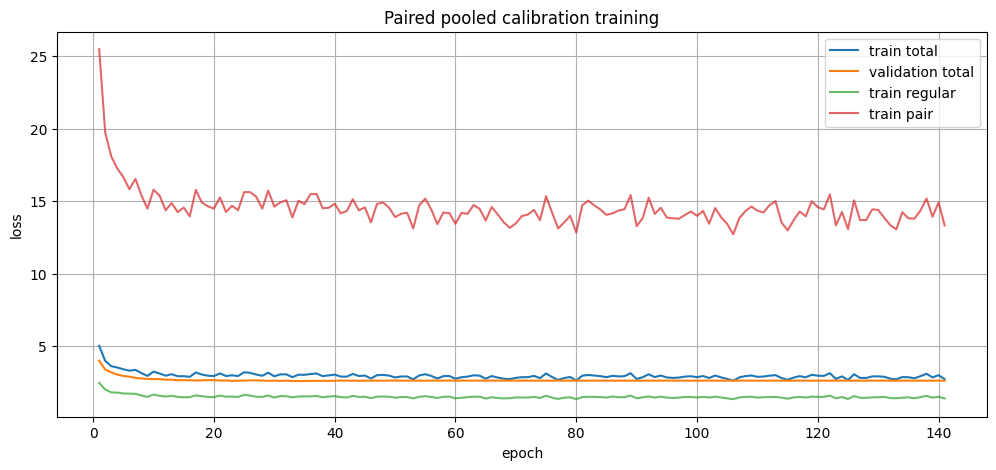

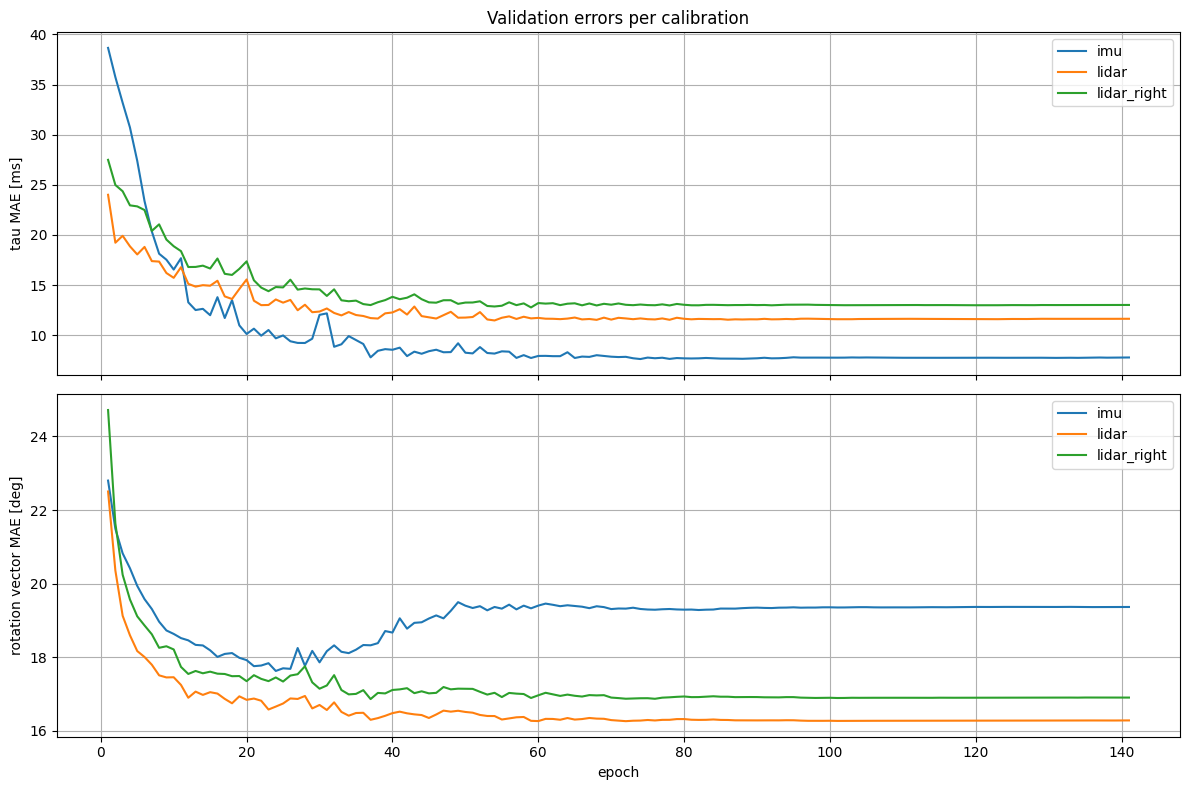

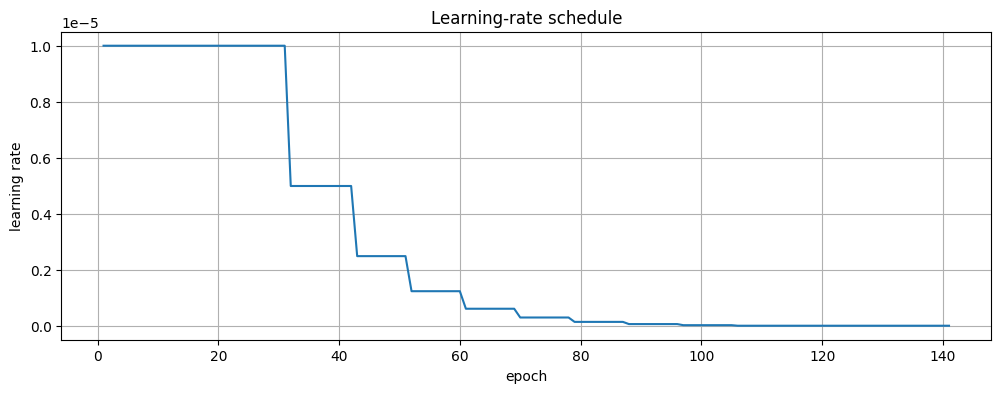

In [57]:
if history:
    epochs = [row["epoch"] for row in history]

    plt.figure(figsize=(12, 5))
    plt.plot(epochs, [row["train/loss_total"] for row in history], label="train total")
    plt.plot(epochs, [row["val/loss_total"] for row in history], label="validation total")
    plt.plot(epochs, [row["train/loss_regular"] for row in history], label="train regular", alpha=0.7)
    plt.plot(epochs, [row["train/loss_pair"] for row in history], label="train pair", alpha=0.7)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title("Paired pooled calibration training")
    plt.grid(True)
    plt.legend()
    plt.show()

    # New: track the error of every calibration separately on the full validation set.
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    for calibration_key in CALIBRATION_KEYS:
        axes[0].plot(epochs, [row[f"val/mean/{calibration_key}/time_offset_error_ms"] for row in history], label=calibration_key)
        axes[1].plot(epochs, [row[f"val/mean/{calibration_key}/rotation_error_deg"] for row in history], label=calibration_key)
    axes[0].set_ylabel("tau MAE [ms]")
    axes[1].set_ylabel("rotation vector MAE [deg]")
    axes[1].set_xlabel("epoch")
    axes[0].set_title("Validation errors per calibration")
    for ax in axes:
        ax.grid(True)
        ax.legend()
    fig.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 4))
    plt.plot(epochs, [row["learning_rate"] for row in history])
    plt.xlabel("epoch")
    plt.ylabel("learning rate")
    plt.title("Learning-rate schedule")
    plt.grid(True)
    plt.show()
torch.cuda.empty_cache()

## 19. Evaluate the best checkpoint


In [26]:
if BEST_CHECKPOINT_PATH.exists():
    best_checkpoint = load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
    test_pair_generator = make_augmentation_generator(TEST_PAIR_SEED)
    test_metrics, _ = run_paired_epoch(test_loader, training=False, pair_generator=test_pair_generator, global_step=global_step)

    print("Best checkpoint epoch:", best_checkpoint.get("epoch"))
    print("Test metrics:")
    for key in sorted(test_metrics):
        print(f"  {key}: {test_metrics[key]:.6f}")
else:
    print("No best checkpoint exists yet.")


Best checkpoint epoch: 34
Test metrics:
  epoch_time_s: 66.261558
  loss_pair: 13.653326
  loss_regular: 1.434084
  loss_total: 2.799416
  loss_truth: 0.000000
  mean/imu/loss_rotation: 0.654862
  mean/imu/loss_time_offset: 0.015582
  mean/imu/loss_translation: 0.002793
  mean/imu/rotation_error_deg: 16.831049
  mean/imu/time_offset_error_ms: 8.343886
  mean/imu/translation_error_cm: 0.202666
  mean/lidar/loss_rotation: 0.846089
  mean/lidar/loss_time_offset: 0.024489
  mean/lidar/loss_translation: 0.002507
  mean/lidar/rotation_error_deg: 20.216279
  mean/lidar/time_offset_error_ms: 12.569663
  mean/lidar/translation_error_cm: 0.200057
  mean/lidar_right/loss_rotation: 0.615848
  mean/lidar_right/loss_time_offset: 0.021466
  mean/lidar_right/loss_translation: 0.001816
  mean/lidar_right/rotation_error_deg: 16.184085
  mean/lidar_right/time_offset_error_ms: 12.302943
  mean/lidar_right/translation_error_cm: 0.178286
  negative/imu/loss_rotation: 0.662097
  negative/imu/loss_time_offset

### 19a. Matched held-out checkpoint comparison
The old and new models receive **identical data, synthetic priors, random seeds, and loss scales**. Evaluate familiar and targeted large rotations separately. A low average loss does not prove that LiDAR X is identifiable.

In [27]:
# Use fixed seeds for a fair before/after checkpoint comparison in BOTH calibration regimes.
# This does not affect the mixed training objective, checkpoint selection, or existing plots.
COMPARE_TO_SOURCE_CHECKPOINT = True


def summarize_regime_metrics(label, metrics):
    print(f"{label:26s} total={metrics['loss_total']:.5f} regular={metrics['loss_regular']:.5f} pair={metrics['loss_pair']:.5f}")
    for key in CALIBRATION_KEYS:
        print(f"  {key:12s} rotation={metrics[f'mean/{key}/rotation_error_deg']:.3f} deg | tau={metrics[f'mean/{key}/time_offset_error_ms']:.3f} ms")


def evaluate_regime(distribution):
    generator = make_augmentation_generator(TEST_PAIR_SEED + 901)
    metrics, _ = run_paired_epoch(test_loader, training=False, pair_generator=generator, global_step=0, distribution=distribution)
    return metrics


if BEST_CHECKPOINT_PATH.is_file():
    print("=" * 100)
    print("FIXED HELD-OUT EVALUATION: familiar vs large-angle priors")
    comparison_new = {}
    for regime in ("familiar", "large"):
        comparison_new[regime] = evaluate_regime(regime)
        summarize_regime_metrics("new 002.11 / " + regime, comparison_new[regime])

    if COMPARE_TO_SOURCE_CHECKPOINT:
        load_training_checkpoint(RESUME_CHECKPOINT, model=model, map_location=DEVICE, restore_rng_state=False)
        try:
            for regime in ("familiar", "large"):
                source_metrics = evaluate_regime(regime)
                summarize_regime_metrics("source / " + regime, source_metrics)
                print(f"  regular-loss change: {100.0 * (comparison_new[regime]['loss_regular'] / source_metrics['loss_regular'] - 1.0):+.2f}%")
        finally:
            # Restore best fine-tuned weights before subsequent visualization cells.
            load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
            model.eval()
else:
    print("Best checkpoint is not present. Train or load before regime comparison.")


FIXED HELD-OUT EVALUATION: familiar vs large-angle priors
new 002.11 / familiar      total=0.13167 regular=0.06960 pair=0.62071
  imu          rotation=3.648 deg | tau=4.385 ms
  lidar        rotation=4.301 deg | tau=10.234 ms
  lidar_right  rotation=4.430 deg | tau=9.119 ms
new 002.11 / large         total=4.26676 regular=2.20571 pair=20.61055
  imu          rotation=21.996 deg | tau=9.558 ms
  lidar        rotation=29.553 deg | tau=13.970 ms
  lidar_right  rotation=24.985 deg | tau=13.780 ms
source / familiar          total=0.06799 regular=0.03877 pair=0.29217
  imu          rotation=1.339 deg | tau=2.619 ms
  lidar        rotation=3.428 deg | tau=9.108 ms
  lidar_right  rotation=3.644 deg | tau=8.460 ms
  regular-loss change: +79.51%
source / large             total=8.12247 regular=4.27832 pair=38.44150
  imu          rotation=30.994 deg | tau=41.808 ms
  lidar        rotation=40.393 deg | tau=69.726 ms
  lidar_right  rotation=38.718 deg | tau=65.216 ms
  regular-loss change: -48.44

## 20. Select held-out windows for detailed visualization


In [28]:
VIS_SEQUENCE_NAME = "Urban38"
VIS_START_WINDOW = 0
VIS_NUM_WINDOWS = 100
VIS_BATCH_SIZE = 16

sequence_indices = [index for index in range(len(test_dataset)) if test_dataset.sequence_name_for_window(index) == VIS_SEQUENCE_NAME]

if not sequence_indices:
    raise ValueError(f"Sequence {VIS_SEQUENCE_NAME!r} is not present in test_dataset.")

selected_indices = sequence_indices[VIS_START_WINDOW : VIS_START_WINDOW + VIS_NUM_WINDOWS]

print("Sequence:", VIS_SEQUENCE_NAME)
print("Selected windows:", len(selected_indices))
print("Dataset indices:", selected_indices[0], "...", selected_indices[-1])


Sequence: Urban38
Selected windows: 100
Dataset indices: 0 ... 99


## 21. Collect deterministic paired predictions


In [29]:
def collect_paired_predictions(dataset, indices, *, batch_size, pair_seed):
    model.eval()
    pair_generator = make_augmentation_generator(pair_seed)

    collected = {
        calibration_key: {
            "positive_true_xi": [],
            "positive_predicted_xi": [],
            "positive_true_tau": [],
            "positive_predicted_tau": [],
            "negative_true_xi": [],
            "negative_predicted_xi": [],
            "negative_true_tau": [],
            "negative_predicted_tau": [],
        }
        for calibration_key in CALIBRATION_KEYS
    }

    with torch.no_grad():
        for start in range(0, len(indices), batch_size):
            batch_indices = indices[start : start + batch_size]
            base_window = collate_windows([dataset[index] for index in batch_indices])
            base_window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)

            positive_window, negative_window, _, _ = make_paired_windows(base_window, generator=pair_generator)
            positive_result = window_step(positive_window)
            negative_result = window_step(negative_window)

            for calibration_key in CALIBRATION_KEYS:
                positive_true_xi, positive_true_tau = correction_target(positive_window, calibration_key)
                negative_true_xi, negative_true_tau = correction_target(negative_window, calibration_key)

                positive_prediction = positive_result.model_output.predictions[calibration_key]
                negative_prediction = negative_result.model_output.predictions[calibration_key]

                collected[calibration_key]["positive_true_xi"].append(positive_true_xi.detach().cpu())
                collected[calibration_key]["positive_predicted_xi"].append(positive_prediction.delta_xi.detach().cpu())
                collected[calibration_key]["positive_true_tau"].append(positive_true_tau.detach().cpu())
                collected[calibration_key]["positive_predicted_tau"].append(positive_prediction.delta_tau.detach().cpu())

                collected[calibration_key]["negative_true_xi"].append(negative_true_xi.detach().cpu())
                collected[calibration_key]["negative_predicted_xi"].append(negative_prediction.delta_xi.detach().cpu())
                collected[calibration_key]["negative_true_tau"].append(negative_true_tau.detach().cpu())
                collected[calibration_key]["negative_predicted_tau"].append(negative_prediction.delta_tau.detach().cpu())

    for calibration_key in CALIBRATION_KEYS:
        for field_name in collected[calibration_key]:
            collected[calibration_key][field_name] = torch.cat(collected[calibration_key][field_name], dim=0).numpy()

    return collected


if BEST_CHECKPOINT_PATH.exists():
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)

visualization_results = collect_paired_predictions(test_dataset, selected_indices, batch_size=VIS_BATCH_SIZE, pair_seed=VISUALIZATION_PAIR_SEED)


## 22. True vs predicted correction over windows


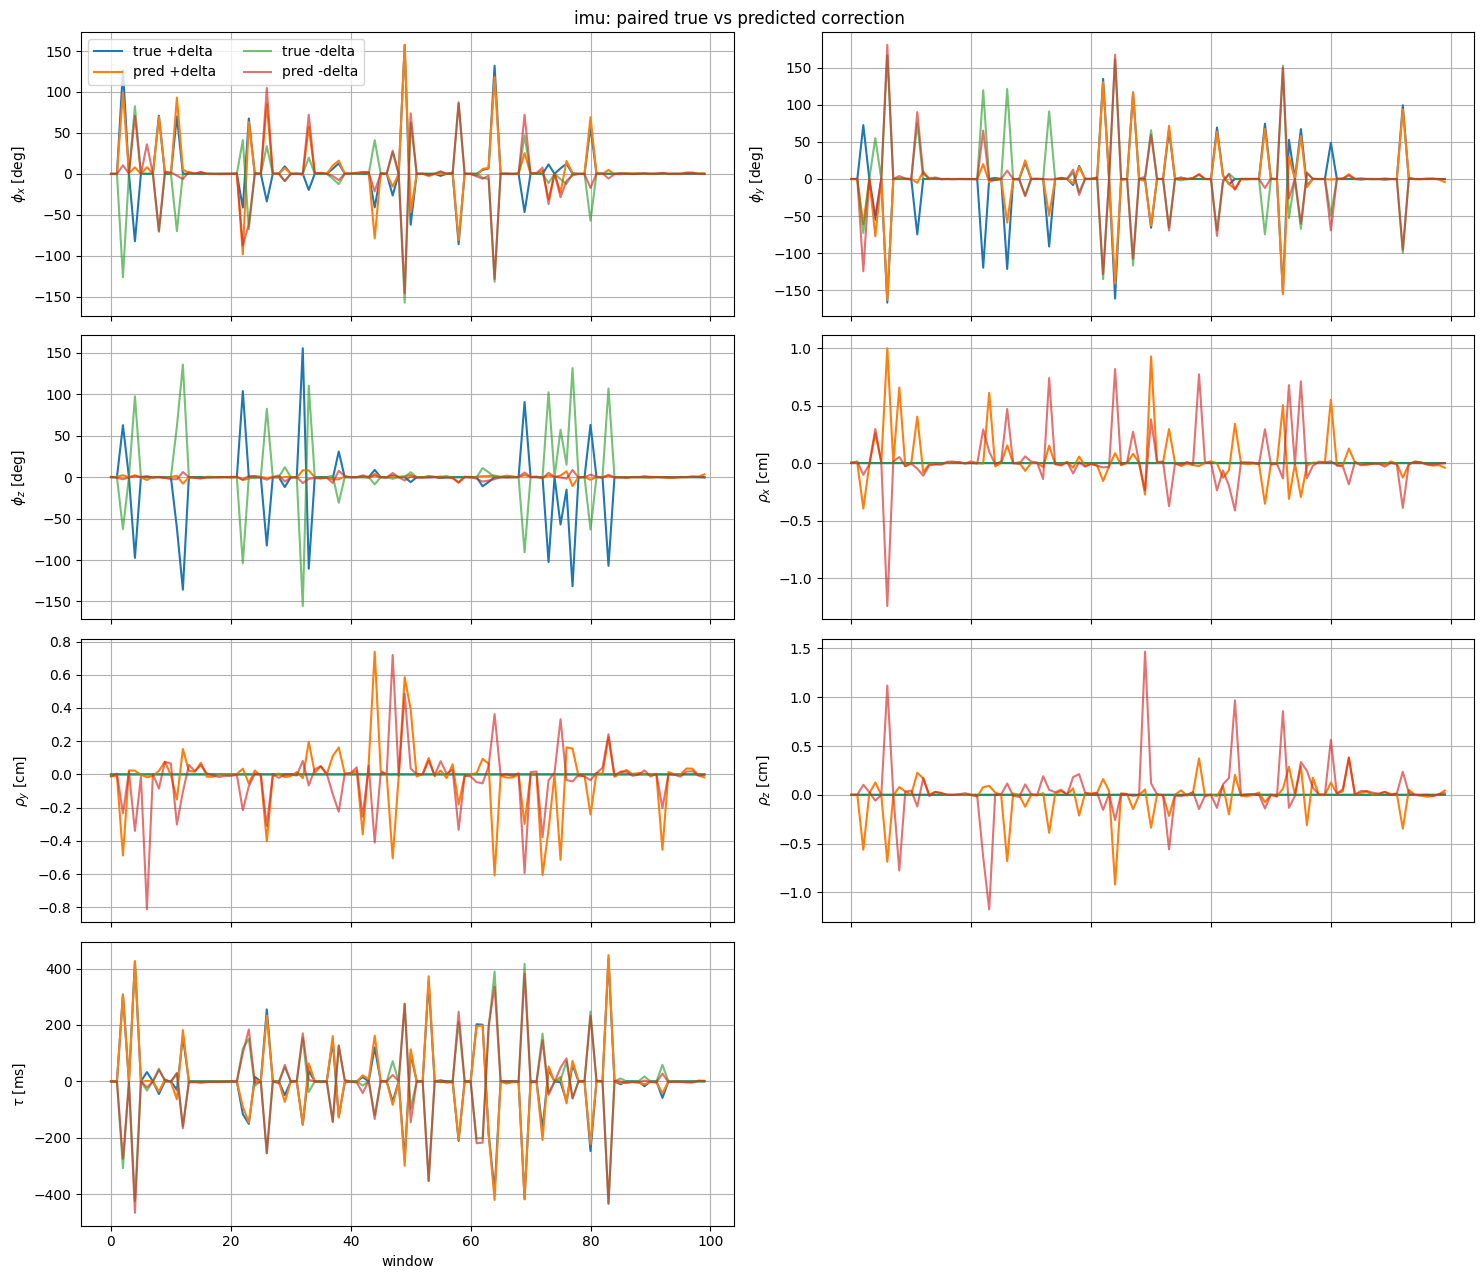

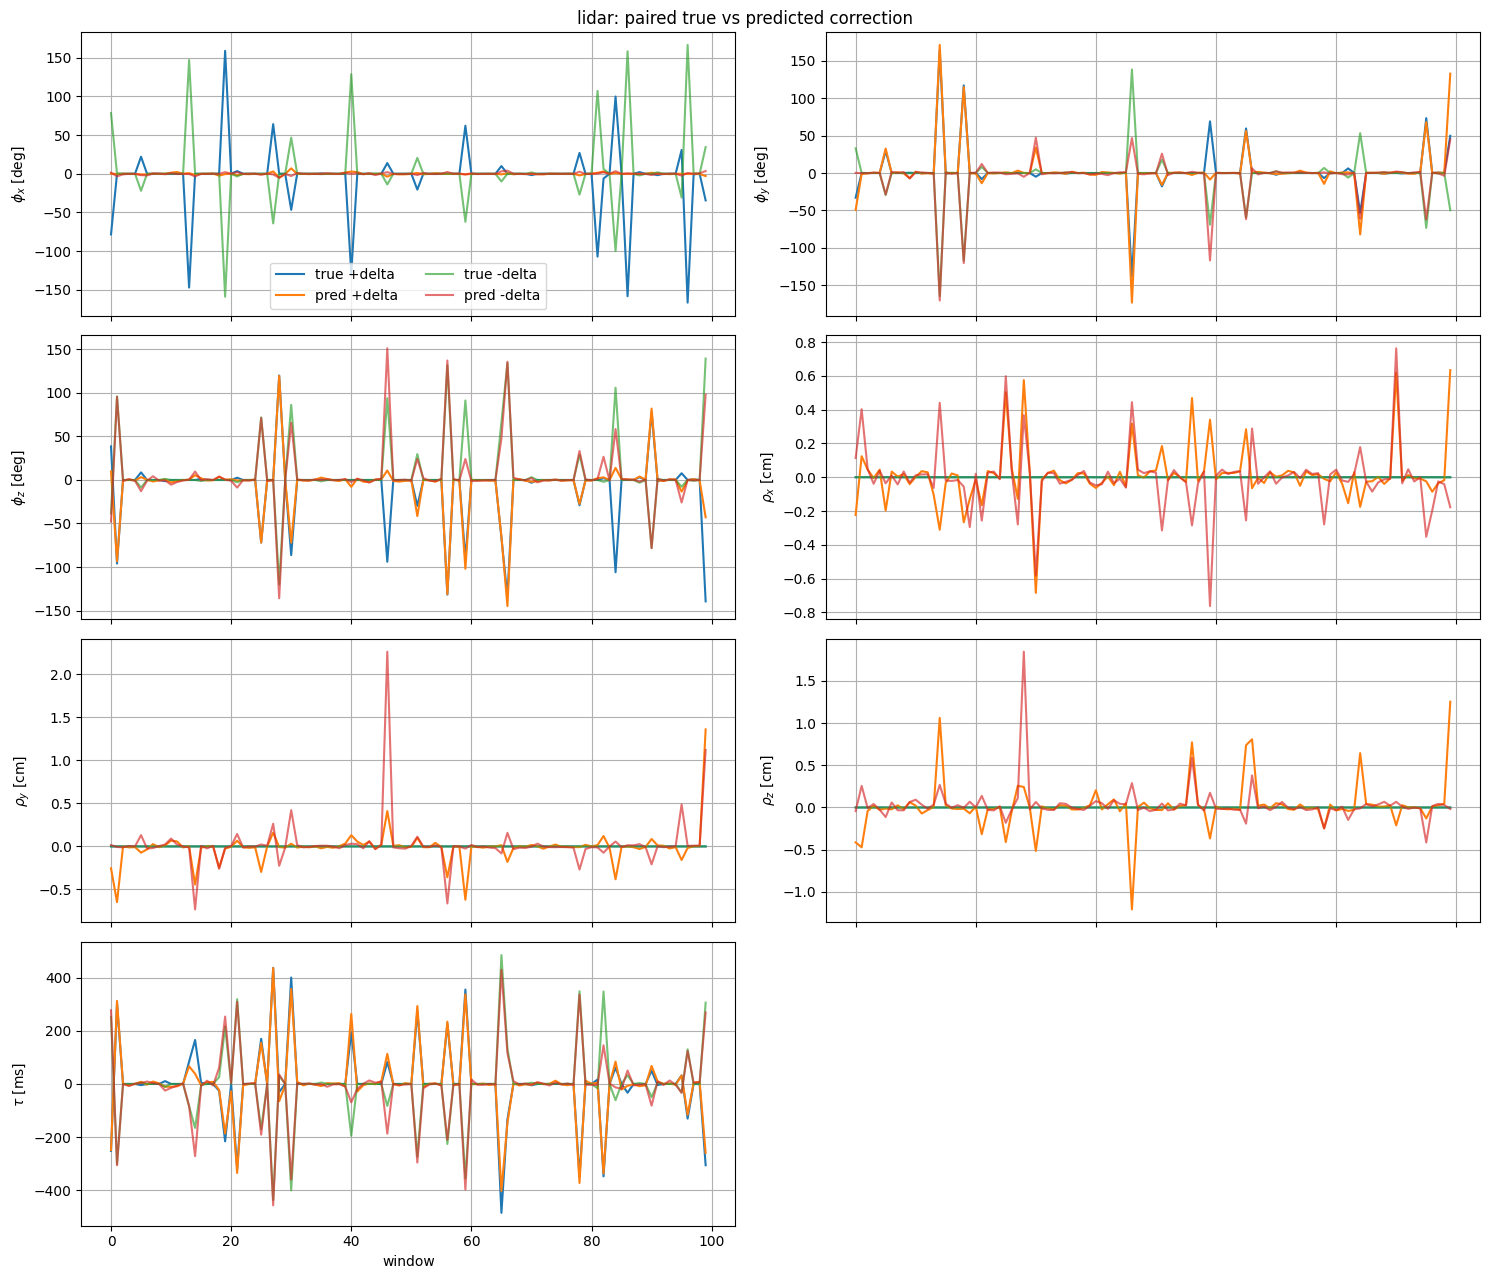

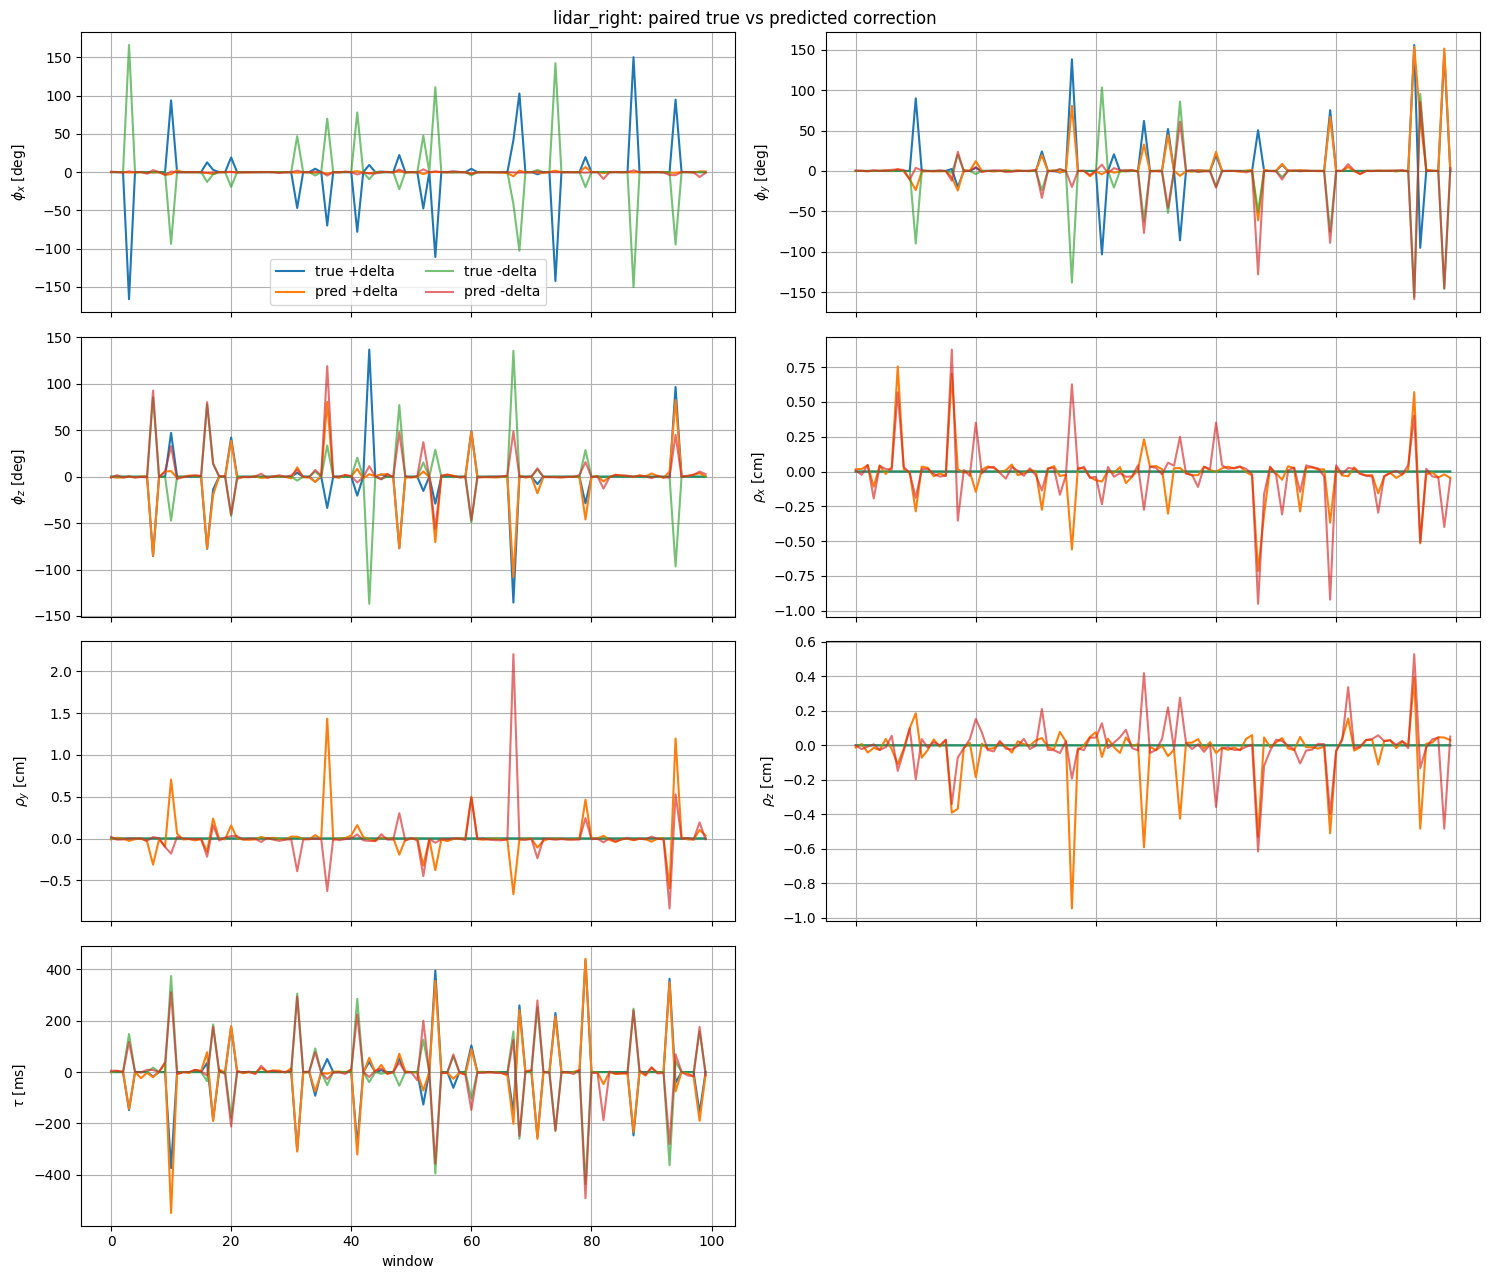

In [30]:
def physical_correction_values(xi, tau):
    return np.column_stack([np.rad2deg(xi[:, :3]), 100.0 * xi[:, 3:], 1000.0 * tau.reshape(-1)])


def plot_paired_true_vs_predicted(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    component_names = (r"$\phi_x$", r"$\phi_y$", r"$\phi_z$", r"$\rho_x$", r"$\rho_y$", r"$\rho_z$", r"$\tau$")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")
    x = np.arange(len(positive_true))

    fig, axes = plt.subplots(4, 2, figsize=(15, 13), sharex=True)
    axes = axes.ravel()

    for component_index in range(7):
        ax = axes[component_index]
        ax.plot(x, positive_true[:, component_index], label="true +delta")
        ax.plot(x, positive_predicted[:, component_index], label="pred +delta")
        ax.plot(x, negative_true[:, component_index], label="true -delta", alpha=0.65)
        ax.plot(x, negative_predicted[:, component_index], label="pred -delta", alpha=0.65)
        ax.set_ylabel(f"{component_names[component_index]} [{units[component_index]}]")
        ax.grid(True)

        if component_index == 0:
            ax.legend(ncol=2)

    axes[6].set_xlabel("window")
    axes[7].axis("off")
    fig.suptitle(f"{calibration_key}: paired true vs predicted correction")
    fig.tight_layout()
    plt.show()


for calibration_key in CALIBRATION_KEYS:
    plot_paired_true_vs_predicted(visualization_results, calibration_key)


## 23. Combined true-vs-predicted scatter


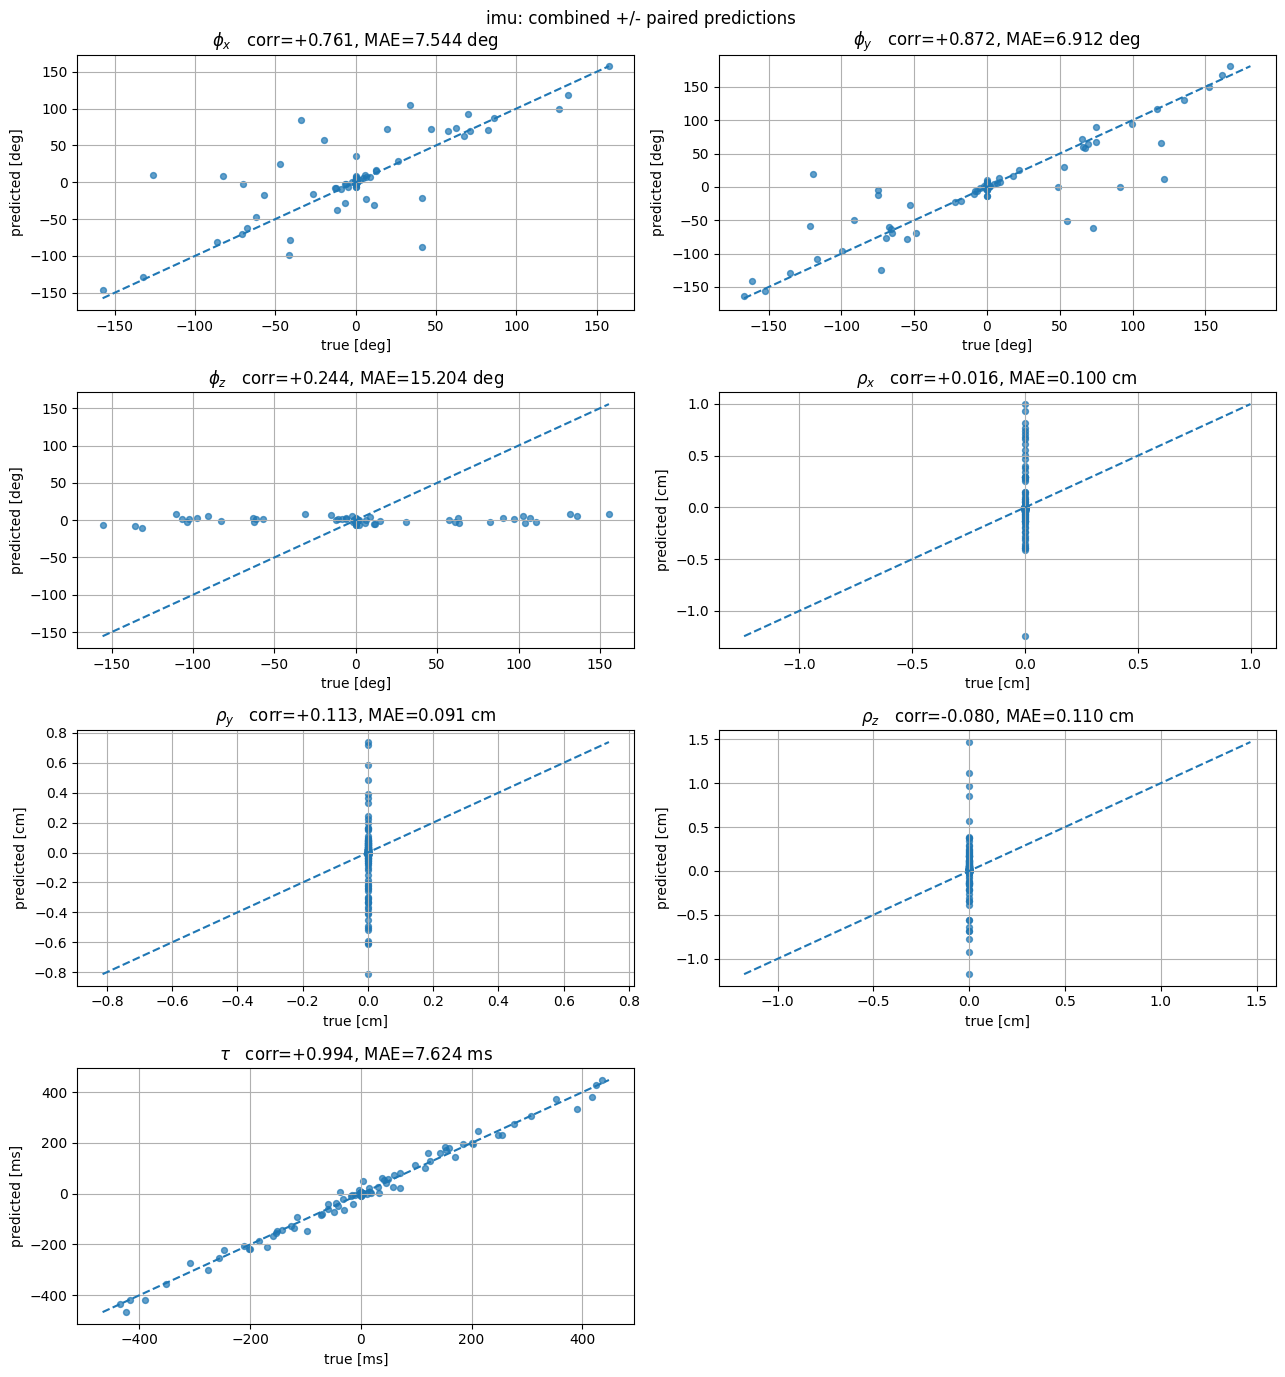

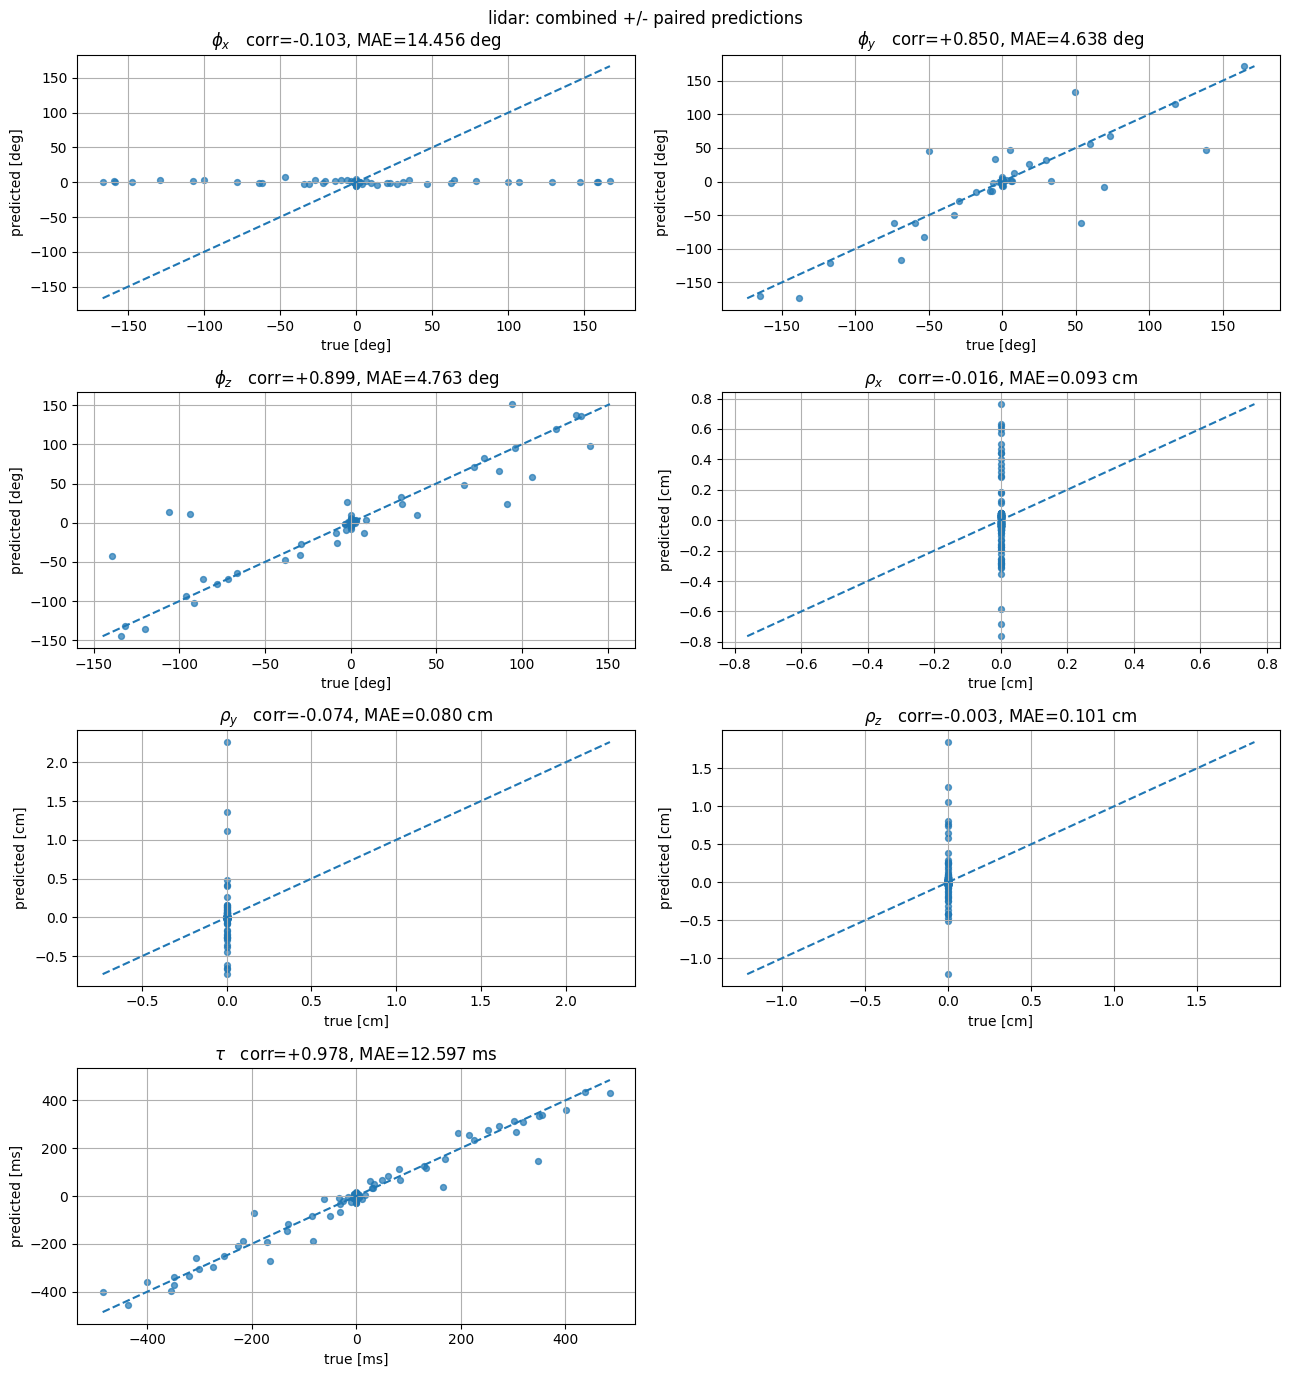

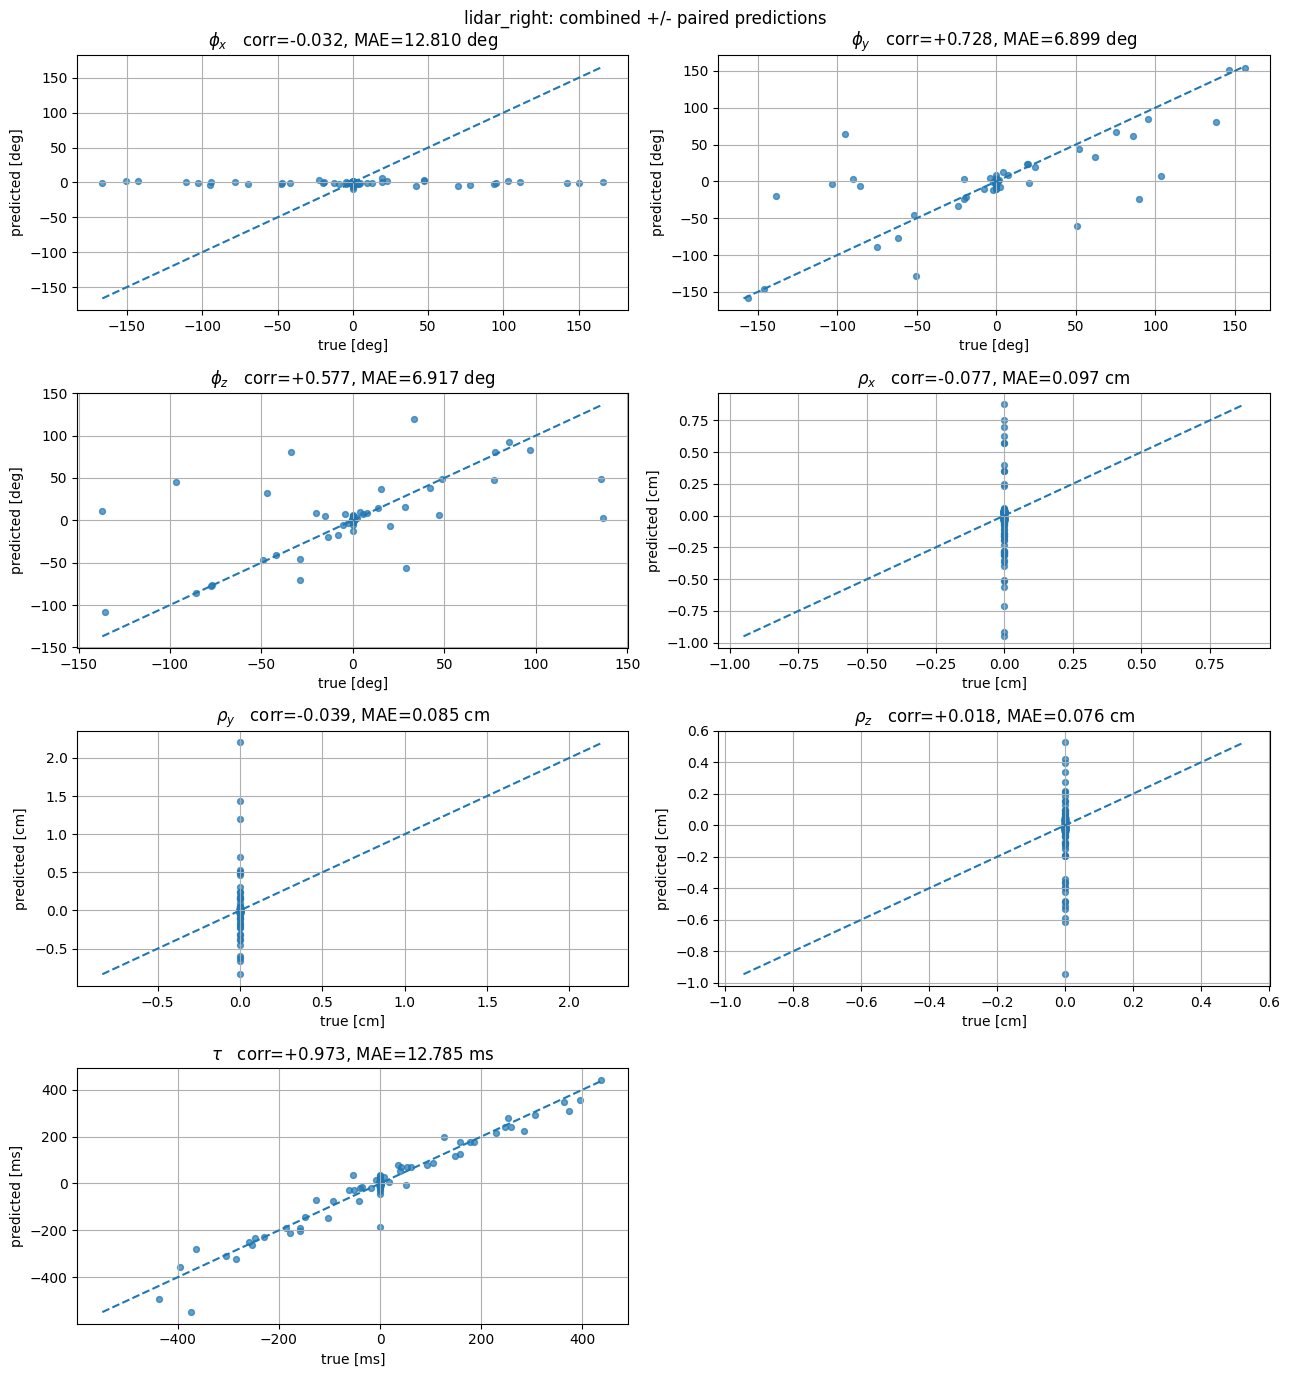

In [31]:
def plot_combined_true_vs_predicted_scatter(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    truth = np.concatenate([positive_true, negative_true], axis=0)
    prediction = np.concatenate([positive_predicted, negative_predicted], axis=0)

    component_names = (r"$\phi_x$", r"$\phi_y$", r"$\phi_z$", r"$\rho_x$", r"$\rho_y$", r"$\rho_z$", r"$\tau$")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")

    fig, axes = plt.subplots(4, 2, figsize=(13, 14))
    axes = axes.ravel()

    for component_index in range(7):
        ax = axes[component_index]
        component_truth = truth[:, component_index]
        component_prediction = prediction[:, component_index]

        minimum = min(component_truth.min(), component_prediction.min())
        maximum = max(component_truth.max(), component_prediction.max())
        correlation = np.corrcoef(component_truth, component_prediction)[0, 1] if np.std(component_truth) > 0.0 and np.std(component_prediction) > 0.0 else np.nan
        mae = np.mean(np.abs(component_prediction - component_truth))

        ax.scatter(component_truth, component_prediction, s=18, alpha=0.7)
        ax.plot([minimum, maximum], [minimum, maximum], linestyle="--")
        ax.set_xlabel(f"true [{units[component_index]}]")
        ax.set_ylabel(f"predicted [{units[component_index]}]")
        ax.set_title(f"{component_names[component_index]}   corr={correlation:+.3f}, MAE={mae:.3f} {units[component_index]}")
        ax.grid(True)

    axes[7].axis("off")
    fig.suptitle(f"{calibration_key}: combined +/- paired predictions")
    fig.tight_layout()
    plt.show()


for calibration_key in CALIBRATION_KEYS:
    plot_combined_true_vs_predicted_scatter(visualization_results, calibration_key)


## 24. Pair-difference scatter

This is the most important anti-collapse visualization. A constant predictor produces approximately zero pair difference and therefore a horizontal cloud. A useful paired model should approach the identity diagonal.


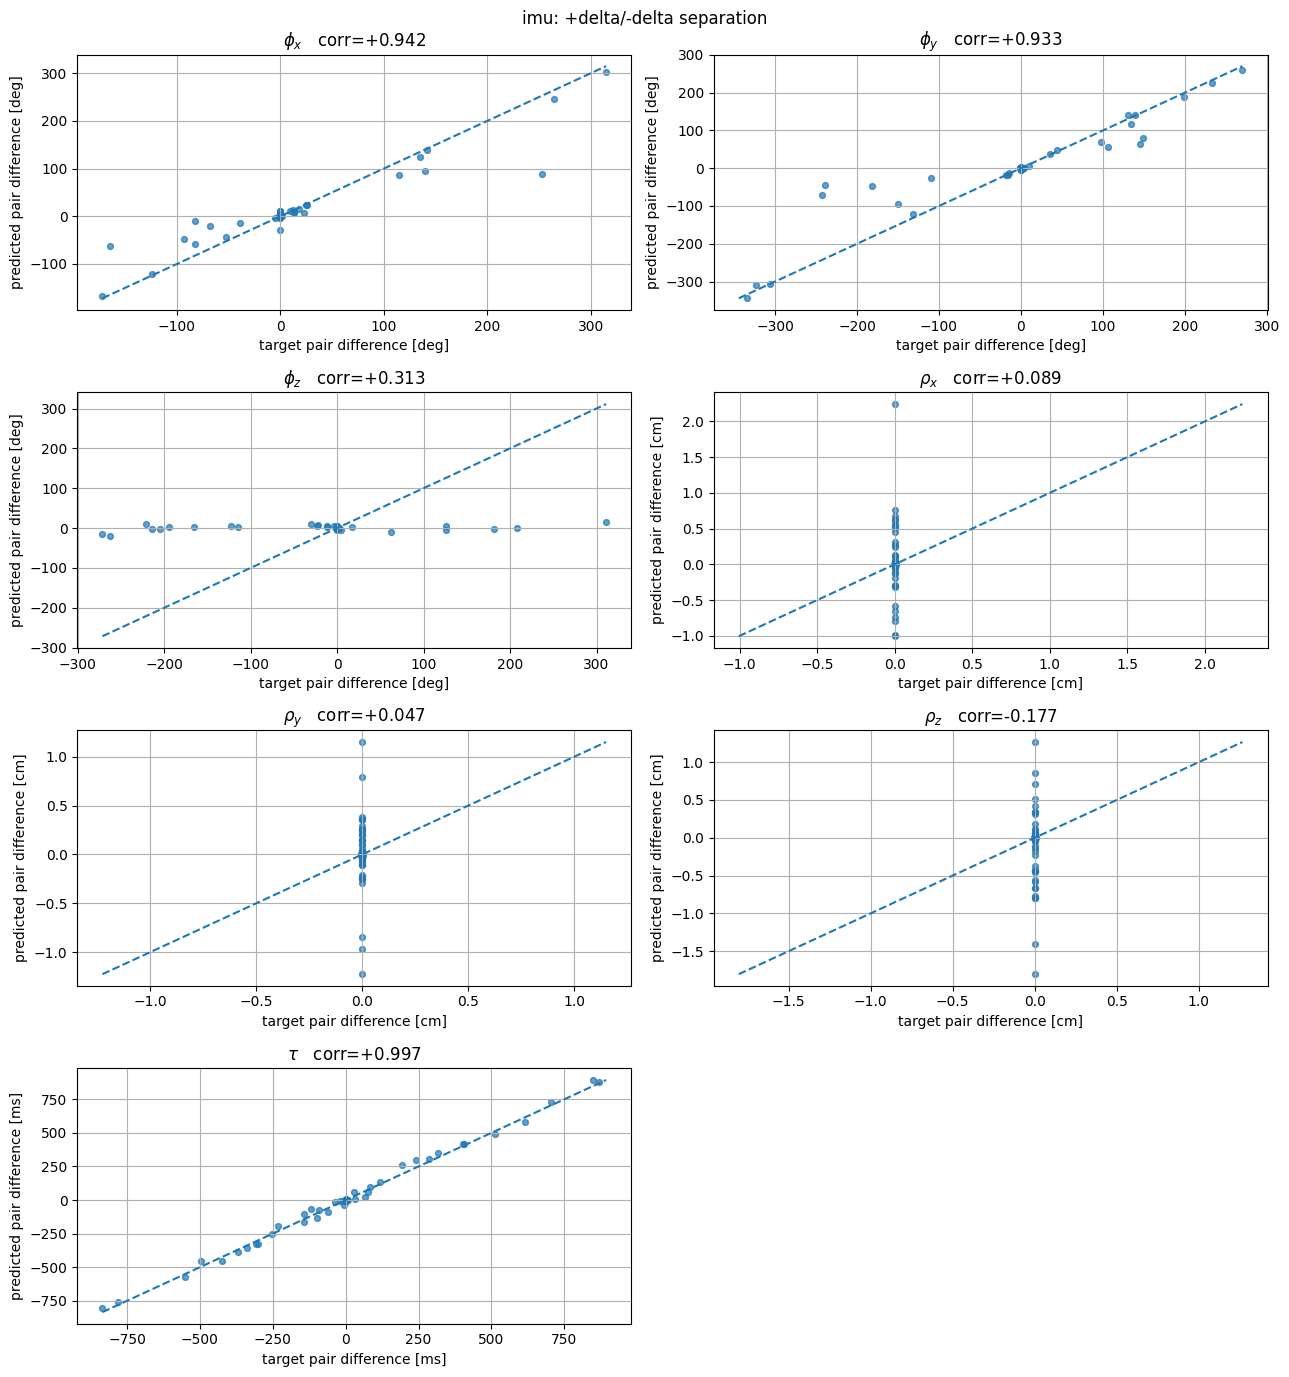

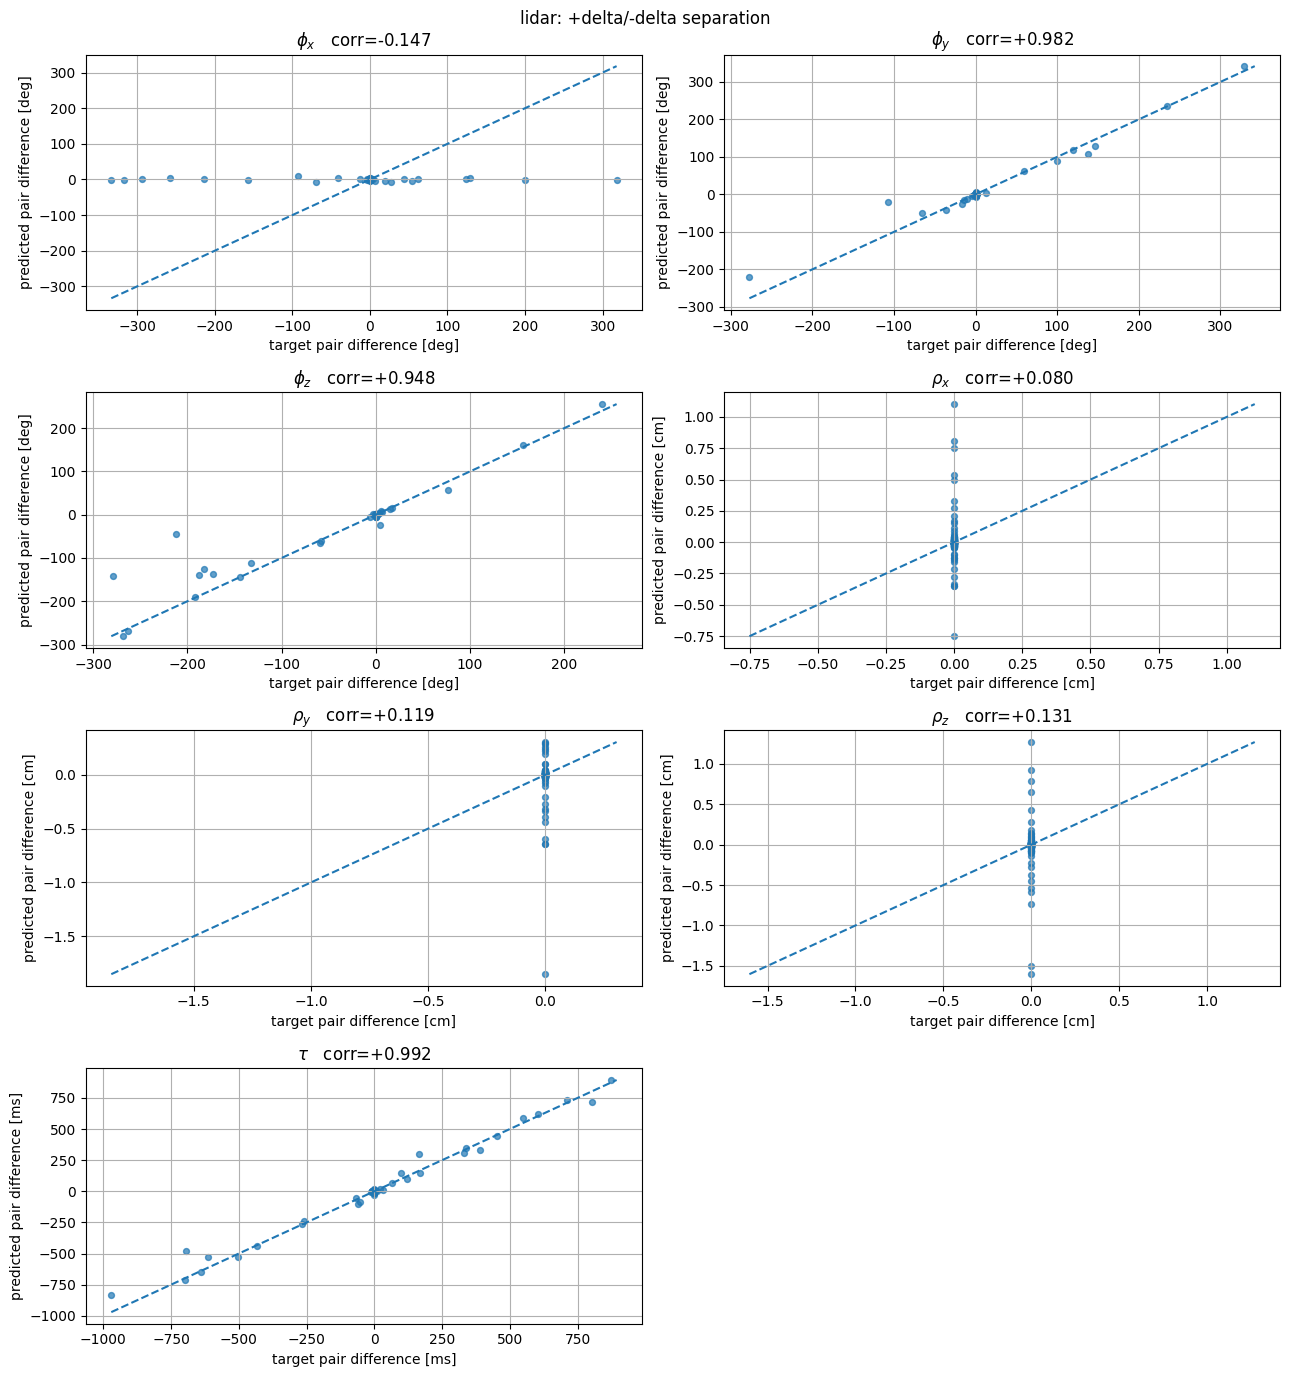

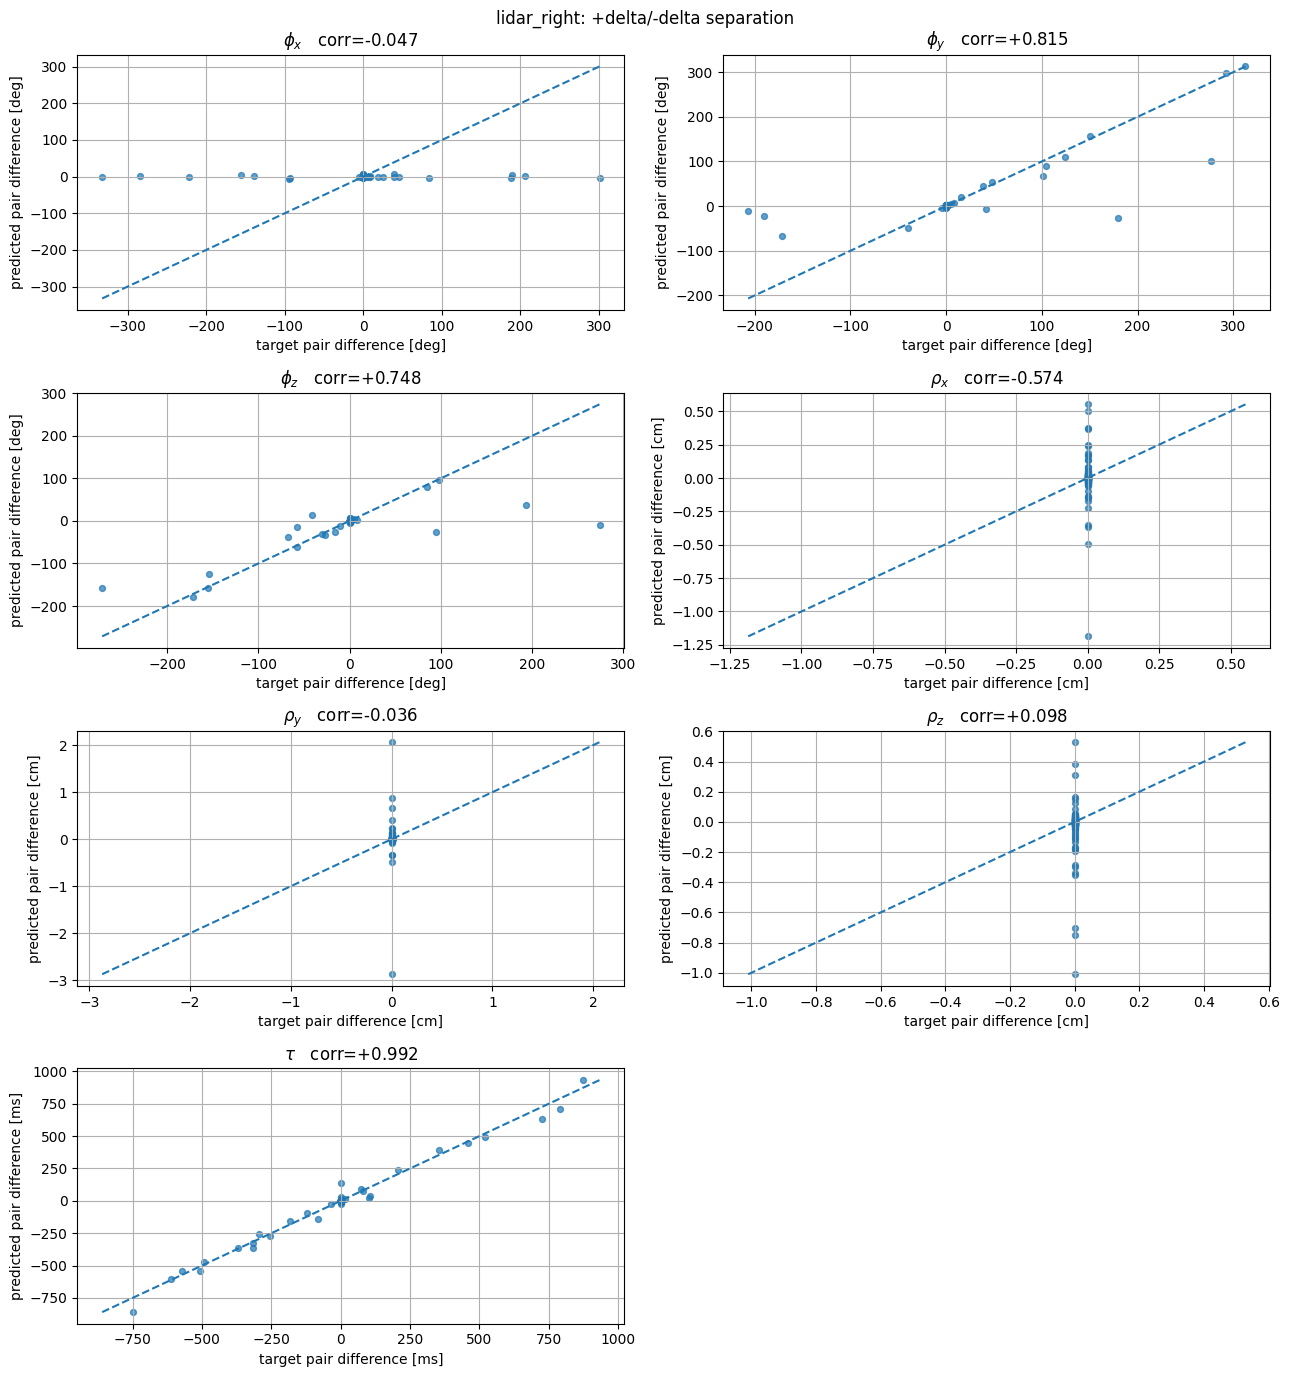

In [32]:
def plot_pair_difference_scatter(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    target_difference = positive_true - negative_true
    predicted_difference = positive_predicted - negative_predicted

    component_names = (r"$\phi_x$", r"$\phi_y$", r"$\phi_z$", r"$\rho_x$", r"$\rho_y$", r"$\rho_z$", r"$\tau$")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")

    fig, axes = plt.subplots(4, 2, figsize=(13, 14))
    axes = axes.ravel()

    for component_index in range(7):
        ax = axes[component_index]
        truth = target_difference[:, component_index]
        prediction = predicted_difference[:, component_index]

        minimum = min(truth.min(), prediction.min())
        maximum = max(truth.max(), prediction.max())
        correlation = np.corrcoef(truth, prediction)[0, 1] if np.std(truth) > 0.0 and np.std(prediction) > 0.0 else np.nan

        ax.scatter(truth, prediction, s=18, alpha=0.7)
        ax.plot([minimum, maximum], [minimum, maximum], linestyle="--")
        ax.set_xlabel(f"target pair difference [{units[component_index]}]")
        ax.set_ylabel(f"predicted pair difference [{units[component_index]}]")
        ax.set_title(f"{component_names[component_index]}   corr={correlation:+.3f}")
        ax.grid(True)

    axes[7].axis("off")
    fig.suptitle(f"{calibration_key}: +delta/-delta separation")
    fig.tight_layout()
    plt.show()


for calibration_key in CALIBRATION_KEYS:
    plot_pair_difference_scatter(visualization_results, calibration_key)


## 25. Numerical paired-prediction summary


In [33]:
def print_paired_prediction_summary(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    truth = np.concatenate([positive_true, negative_true], axis=0)
    prediction = np.concatenate([positive_predicted, negative_predicted], axis=0)
    target_difference = positive_true - negative_true
    predicted_difference = positive_predicted - negative_predicted

    component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")

    print(calibration_key)
    print(f"{'component':8s} {'MAE':>12s} {'corr':>10s} {'pred std':>12s} {'pair corr':>12s} {'pair MAE':>12s}")

    for component_index, component_name in enumerate(component_names):
        component_truth = truth[:, component_index]
        component_prediction = prediction[:, component_index]
        difference_truth = target_difference[:, component_index]
        difference_prediction = predicted_difference[:, component_index]

        mae = np.mean(np.abs(component_prediction - component_truth))
        correlation = np.corrcoef(component_truth, component_prediction)[0, 1] if np.std(component_truth) > 0.0 and np.std(component_prediction) > 0.0 else np.nan
        pair_correlation = np.corrcoef(difference_truth, difference_prediction)[0, 1] if np.std(difference_truth) > 0.0 and np.std(difference_prediction) > 0.0 else np.nan
        pair_mae = np.mean(np.abs(difference_prediction - difference_truth))

        print(
            f"{component_name:8s} "
            f"{mae:9.4f} {units[component_index]:3s} "
            f"{correlation:+10.4f} "
            f"{np.std(component_prediction):12.4f} "
            f"{pair_correlation:+12.4f} "
            f"{pair_mae:9.4f} {units[component_index]:3s}"
        )

    print()


for calibration_key in CALIBRATION_KEYS:
    print_paired_prediction_summary(visualization_results, calibration_key)


imu
component          MAE       corr     pred std    pair corr     pair MAE
phi_x       7.5439 deg    +0.7606      32.1906      +0.9418    7.3748 deg
phi_y       6.9119 deg    +0.8725      40.3791      +0.9327   10.2495 deg
phi_z      15.2044 deg    +0.2436       2.4045      +0.3126   29.9946 deg
rho_x       0.1003 cm     +0.0160       0.2240      +0.0891    0.1499 cm 
rho_y       0.0908 cm     +0.1127       0.1829      +0.0471    0.1101 cm 
rho_z       0.1103 cm     -0.0795       0.2486      -0.1774    0.1683 cm 
tau         7.6236 ms     +0.9940     123.4035      +0.9973   10.9462 ms 

lidar
component          MAE       corr     pred std    pair corr     pair MAE
phi_x      14.4564 deg    -0.1027       1.3116      -0.1468   28.5671 deg
phi_y       4.6379 deg    +0.8502      30.6228      +0.9818    3.5453 deg
phi_z       4.7634 deg    +0.8991      33.4018      +0.9479    6.3448 deg
rho_x       0.0927 cm     -0.0164       0.1784      +0.0801    0.0937 cm 
rho_y       0.0798 cm     -0.

## 25a. Compare time-offset corrections across all sensors

Plot all three clocks side by side. The second figure evaluates **relative correction differences** for each sensor pair; these are useful diagnostics because a common time shift is not identifiable from relative motion alone. The plots show predictive behavior, not production fault classification.


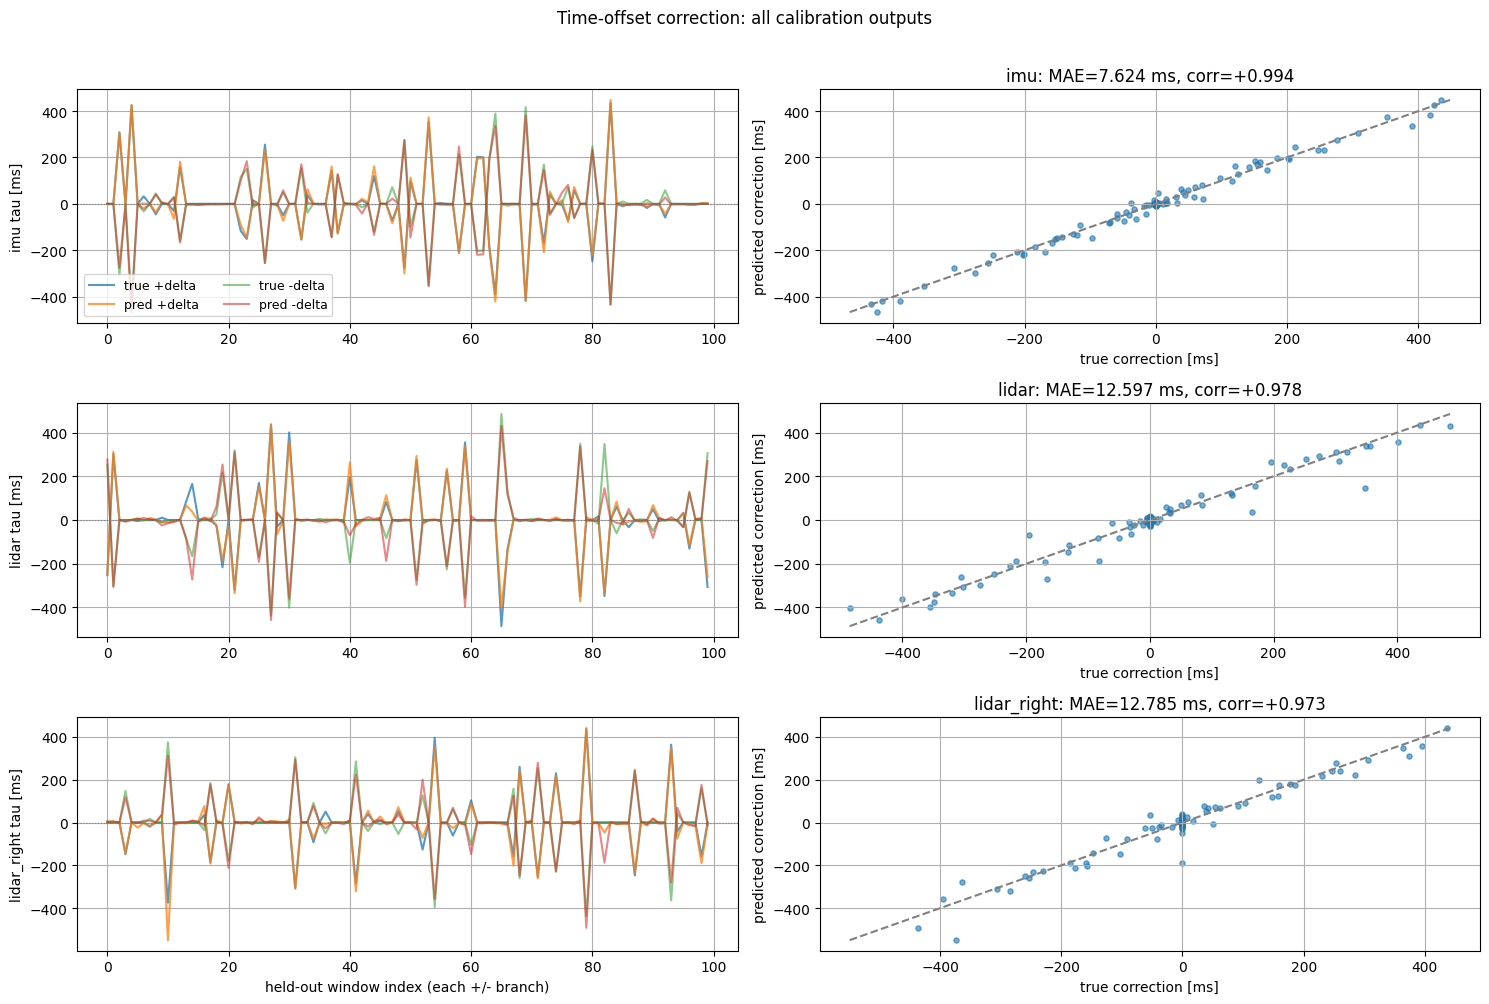

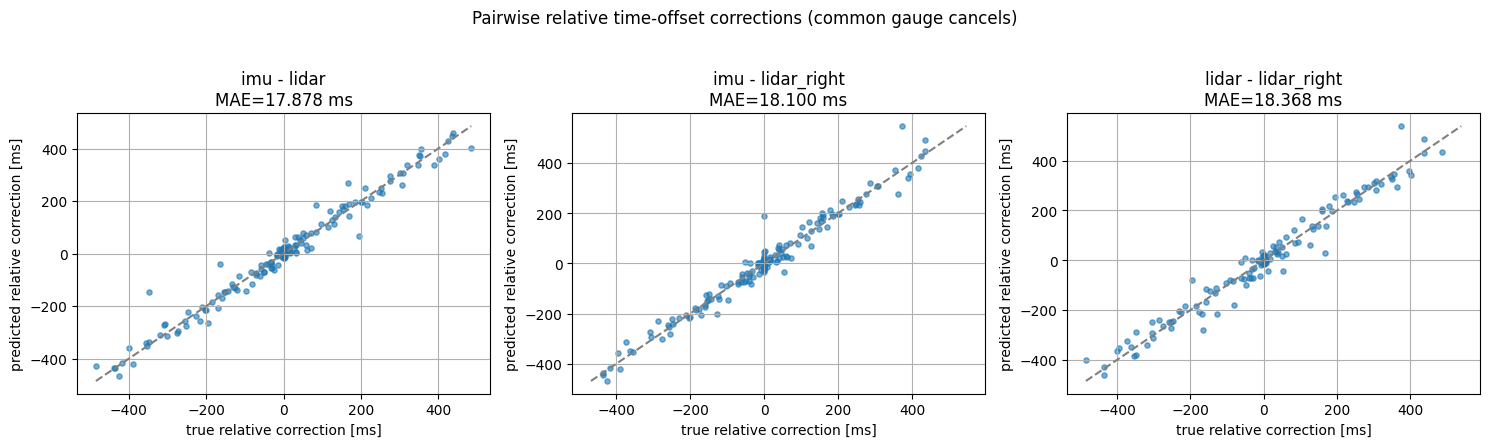

In [34]:
# Three-sensor timing comparison using the exact paired predictions collected above.
from itertools import combinations


def _paired_tau_arrays(results, calibration_key):
    result = results[calibration_key]
    return (
        1000.0 * np.concatenate((result["positive_true_tau"].reshape(-1), result["negative_true_tau"].reshape(-1))),
        1000.0 * np.concatenate((result["positive_predicted_tau"].reshape(-1), result["negative_predicted_tau"].reshape(-1))),
    )


def plot_three_sensor_tau_comparison(results):
    fig, axes = plt.subplots(len(CALIBRATION_KEYS), 2, figsize=(15, 3.3 * len(CALIBRATION_KEYS)), squeeze=False)

    for row, calibration_key in enumerate(CALIBRATION_KEYS):
        true_tau, predicted_tau = _paired_tau_arrays(results, calibration_key)
        true_positive = 1000.0 * results[calibration_key]["positive_true_tau"].reshape(-1)
        predicted_positive = 1000.0 * results[calibration_key]["positive_predicted_tau"].reshape(-1)
        true_negative = 1000.0 * results[calibration_key]["negative_true_tau"].reshape(-1)
        predicted_negative = 1000.0 * results[calibration_key]["negative_predicted_tau"].reshape(-1)
        x = np.arange(len(true_positive))

        axes[row, 0].plot(x, true_positive, label="true +delta", alpha=0.75)
        axes[row, 0].plot(x, predicted_positive, label="pred +delta", alpha=0.75)
        axes[row, 0].plot(x, true_negative, label="true -delta", alpha=0.55)
        axes[row, 0].plot(x, predicted_negative, label="pred -delta", alpha=0.55)
        axes[row, 0].axhline(0.0, color="gray", linestyle=":", linewidth=0.8)
        axes[row, 0].set_ylabel(f"{calibration_key} tau [ms]")
        axes[row, 0].grid(True)
        if row == 0:
            axes[row, 0].legend(ncol=2, fontsize=9)

        minimum = min(true_tau.min(), predicted_tau.min())
        maximum = max(true_tau.max(), predicted_tau.max())
        axes[row, 1].scatter(true_tau, predicted_tau, s=14, alpha=0.6)
        axes[row, 1].plot([minimum, maximum], [minimum, maximum], linestyle="--", color="gray")
        axes[row, 1].set_xlabel("true correction [ms]")
        axes[row, 1].set_ylabel("predicted correction [ms]")
        corr = np.corrcoef(true_tau, predicted_tau)[0, 1] if np.std(true_tau) > 0 and np.std(predicted_tau) > 0 else np.nan
        axes[row, 1].set_title(f"{calibration_key}: MAE={np.mean(np.abs(predicted_tau - true_tau)):.3f} ms, corr={corr:+.3f}")
        axes[row, 1].grid(True)

    axes[-1, 0].set_xlabel("held-out window index (each +/- branch)")
    fig.suptitle("Time-offset correction: all calibration outputs", y=1.01)
    fig.tight_layout()
    plt.show()


def plot_relative_tau_corrections(results):
    sensor_pairs = list(combinations(CALIBRATION_KEYS, 2))
    fig, axes = plt.subplots(1, len(sensor_pairs), figsize=(5.0 * len(sensor_pairs), 4.3), squeeze=False)

    for ax, (first_key, second_key) in zip(axes.ravel(), sensor_pairs):
        first_true, first_predicted = _paired_tau_arrays(results, first_key)
        second_true, second_predicted = _paired_tau_arrays(results, second_key)
        relative_true = first_true - second_true
        relative_predicted = first_predicted - second_predicted
        minimum = min(relative_true.min(), relative_predicted.min())
        maximum = max(relative_true.max(), relative_predicted.max())
        ax.scatter(relative_true, relative_predicted, s=14, alpha=0.6)
        ax.plot([minimum, maximum], [minimum, maximum], linestyle="--", color="gray")
        ax.set_xlabel("true relative correction [ms]")
        ax.set_ylabel("predicted relative correction [ms]")
        ax.set_title(f"{first_key} - {second_key}\nMAE={np.mean(np.abs(relative_predicted - relative_true)):.3f} ms")
        ax.grid(True)

    fig.suptitle("Pairwise relative time-offset corrections (common gauge cancels)", y=1.03)
    fig.tight_layout()
    plt.show()


plot_three_sensor_tau_comparison(visualization_results)
plot_relative_tau_corrections(visualization_results)


## 26. Exact-truth fixed-point diagnostic


In [35]:
FIXED_POINT_NUM_WINDOWS = min(100, len(sequence_indices))
fixed_point_positions = np.unique(np.linspace(0, len(sequence_indices) - 1, FIXED_POINT_NUM_WINDOWS).round().astype(int))
fixed_point_indices = np.asarray(sequence_indices)[fixed_point_positions]

fixed_point_results = {calibration_key: {"delta_xi": [], "delta_tau": []} for calibration_key in CALIBRATION_KEYS}

model.eval()

with torch.no_grad():
    for dataset_index in fixed_point_indices:
        window = window_batch_to(collate_windows([test_dataset[int(dataset_index)]]), DEVICE, dtype=MODEL_DTYPE)
        exact_true_calibration = {calibration_key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for calibration_key, state in window.current_calibration.items()}
        result = window_step(window, calibration=exact_true_calibration)

        for calibration_key, prediction in result.model_output.predictions.items():
            fixed_point_results[calibration_key]["delta_xi"].append(prediction.delta_xi[0].detach().cpu())
            fixed_point_results[calibration_key]["delta_tau"].append(prediction.delta_tau[0, 0].detach().cpu())

for calibration_key in CALIBRATION_KEYS:
    fixed_point_results[calibration_key]["delta_xi"] = torch.stack(fixed_point_results[calibration_key]["delta_xi"]).numpy()
    fixed_point_results[calibration_key]["delta_tau"] = torch.stack(fixed_point_results[calibration_key]["delta_tau"]).numpy()

component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")

print("=" * 120)
print("EXACT-TRUTH FIXED-POINT DIAGNOSTIC")
print("=" * 120)

for calibration_key in CALIBRATION_KEYS:
    result = fixed_point_results[calibration_key]
    prediction = np.concatenate([result["delta_xi"], result["delta_tau"][:, None]], axis=1)

    print(calibration_key)
    print(f"{'component':8s} {'mean':>16s} {'mean |x|':>16s} {'RMSE':>16s} {'std':>16s} {'range':>16s}")

    for component_index, component_name in enumerate(component_names):
        values = prediction[:, component_index]

        if component_index < 3:
            values, unit = np.rad2deg(values), "deg"
        elif component_index < 6:
            values, unit = 100.0 * values, "cm"
        else:
            values, unit = 1000.0 * values, "ms"

        mean = np.mean(values)
        mean_abs = np.mean(np.abs(values))
        rmse = np.sqrt(np.mean(values ** 2))
        std = np.std(values)
        value_range = np.max(values) - np.min(values)

        print(f"{component_name:8s} {mean:+12.6f} {unit:3s} {mean_abs:12.6f} {unit:3s} {rmse:12.6f} {unit:3s} {std:12.6f} {unit:3s} {value_range:12.6f} {unit:3s}")

    print()


/home/camel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/transformer.py:505: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


EXACT-TRUTH FIXED-POINT DIAGNOSTIC
imu
component             mean         mean |x|             RMSE              std            range
phi_x       +0.763530 deg     0.789015 deg     1.031464 deg     0.693499 deg     3.777626 deg
phi_y       +0.231836 deg     0.473616 deg     0.643515 deg     0.600302 deg     3.221191 deg
phi_z       -0.151008 deg     0.651624 deg     0.909226 deg     0.896598 deg     5.236129 deg
rho_x       -0.017224 cm      0.017340 cm      0.018817 cm      0.007579 cm      0.044038 cm 
rho_y       +0.025006 cm      0.025537 cm      0.033747 cm      0.022662 cm      0.115146 cm 
rho_z       +0.020180 cm      0.022880 cm      0.027885 cm      0.019244 cm      0.101322 cm 
tau         -1.788156 ms      3.052544 ms      3.480097 ms      2.985560 ms     13.580035 ms 

lidar
component             mean         mean |x|             RMSE              std            range
phi_x       +0.008358 deg     0.291497 deg     0.493016 deg     0.492946 deg     4.438436 deg
phi_y       

## 27. Interpretation and next steps

**Pass condition:** the new checkpoint should improve the **held-out** 120–170° recovery, especially isolated LiDAR X errors, without destabilizing 0–60° cases or timing updates. The stochastic gate is only a feasibility test on familiar motions. If the residual landscape has equal 0° and 180° minima, no network can infer which member is correct from that residual alone; use additional measurements or a prior. A 360° rotational sweep repeats physical states because rotations are periodic. See the new comparative rollout section below.

# Shuffle diagnostics of prior-only training

In [36]:
# Measurement-shuffle diagnostic.
# Keep every calibration prior and supervision target attached to its original batch item,
# but replace the complete measurement window by another item's measurement window.
# If performance barely changes, the model can solve the task mostly from calibration context alone.
# If performance degrades substantially, the model is genuinely using the sensor measurements.

from obscalib.data.structures import SensorStreamBatch, WindowBatch

MEASUREMENT_SHUFFLE_NUM_WINDOWS = min(BATCH_SIZE, 16)
MEASUREMENT_SHUFFLE_PAIR_SEED = TEST_PAIR_SEED + 700000
MEASUREMENT_SHUFFLE_PERMUTATION_SEED = TEST_PAIR_SEED + 800000

measurement_shuffle_indices = np.linspace(0, len(test_dataset) - 1, MEASUREMENT_SHUFFLE_NUM_WINDOWS, dtype=int)
measurement_shuffle_base_window = collate_windows([test_dataset[int(index)] for index in measurement_shuffle_indices])
measurement_shuffle_base_window = window_batch_to(measurement_shuffle_base_window, DEVICE, dtype=MODEL_DTYPE)

measurement_shuffle_pair_generator = make_augmentation_generator(MEASUREMENT_SHUFFLE_PAIR_SEED)

measurement_shuffle_positive_window, measurement_shuffle_negative_window, _, _ = make_paired_windows(
    measurement_shuffle_base_window,
    generator=measurement_shuffle_pair_generator,
)

batch_size = next(iter(measurement_shuffle_positive_window.streams.values())).values.shape[0]

if batch_size < 2:
    raise ValueError("Measurement-shuffle diagnostic requires at least two batch items.")

# Build a deterministic random derangement so no batch item keeps its own measurements.
permutation_rng = np.random.default_rng(MEASUREMENT_SHUFFLE_PERMUTATION_SEED)
identity_permutation = np.arange(batch_size)

while True:
    measurement_permutation_numpy = permutation_rng.permutation(batch_size)

    if np.all(measurement_permutation_numpy != identity_permutation):
        break

measurement_permutation = torch.as_tensor(measurement_permutation_numpy, dtype=torch.long)


def shuffle_window_measurements(window: WindowBatch, permutation: torch.Tensor) -> WindowBatch:
    shuffled_streams = {}

    for stream_key, stream in window.streams.items():
        stream_permutation = permutation.to(stream.values.device)

        shuffled_streams[stream_key] = SensorStreamBatch(
            values=stream.values[stream_permutation],
            timestamps=stream.timestamps[stream_permutation],
            sample_mask=stream.sample_mask[stream_permutation],
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps[stream_permutation],
        )

    return WindowBatch(
        streams=shuffled_streams,
        current_calibration=dict(window.current_calibration),
        metadata=dict(window.metadata),
        targets=None if window.targets is None else dict(window.targets),
        dataset_indices=window.dataset_indices,
    )


measurement_shuffle_positive_shuffled_window = shuffle_window_measurements(measurement_shuffle_positive_window, measurement_permutation)
measurement_shuffle_negative_shuffled_window = shuffle_window_measurements(measurement_shuffle_negative_window, measurement_permutation)


def evaluate_measurement_shuffle_pair(positive_window: WindowBatch, negative_window: WindowBatch):
    with torch.inference_mode():
        positive_result = window_step(positive_window)
        positive_output = positive_result.model_output
        del positive_result

        negative_result = window_step(negative_window)
        negative_output = negative_result.model_output
        del negative_result

        loss, metrics = compute_paired_objective(
            positive_window,
            positive_output,
            negative_window,
            negative_output,
        )

        prediction_summary = {}

        for calibration_key in CALIBRATION_KEYS:
            prediction_summary[calibration_key] = {
                "positive_xi": positive_output.predictions[calibration_key].delta_xi.detach().cpu(),
                "negative_xi": negative_output.predictions[calibration_key].delta_xi.detach().cpu(),
                "positive_tau": positive_output.predictions[calibration_key].delta_tau.detach().cpu(),
                "negative_tau": negative_output.predictions[calibration_key].delta_tau.detach().cpu(),
            }

        loss_value = float(loss.detach().cpu())
        metric_values = {key: float(value.detach().cpu()) if torch.is_tensor(value) else float(value) for key, value in metrics.items()}

        del positive_output
        del negative_output
        del loss

    return loss_value, metric_values, prediction_summary


previous_training_mode = model.training
model.eval()

try:
    normal_total, normal_metrics, normal_predictions = evaluate_measurement_shuffle_pair(
        measurement_shuffle_positive_window,
        measurement_shuffle_negative_window,
    )

    shuffled_total, shuffled_metrics, shuffled_predictions = evaluate_measurement_shuffle_pair(
        measurement_shuffle_positive_shuffled_window,
        measurement_shuffle_negative_shuffled_window,
    )

finally:
    model.train(previous_training_mode)


print("=" * 110)
print("MEASUREMENT-SHUFFLE DEPENDENCE DIAGNOSTIC")
print("=" * 110)
print("windows:", batch_size)
print("measurement permutation:", measurement_permutation_numpy.tolist())
print()
print("Calibration priors: unchanged")
print("Supervision targets: unchanged")
print("Measurements: complete physical windows reassigned between batch items")
print()
print(f"{'condition':14s} {'total':>12s} {'regular':>12s} {'pair':>12s}")
print(f"{'normal':14s} {normal_total:12.6f} {normal_metrics['loss_regular']:12.6f} {normal_metrics['loss_pair']:12.6f}")
print(f"{'shuffled':14s} {shuffled_total:12.6f} {shuffled_metrics['loss_regular']:12.6f} {shuffled_metrics['loss_pair']:12.6f}")
print()

total_ratio = shuffled_total / max(normal_total, 1e-12)
regular_ratio = shuffled_metrics["loss_regular"] / max(normal_metrics["loss_regular"], 1e-12)
pair_ratio = shuffled_metrics["loss_pair"] / max(normal_metrics["loss_pair"], 1e-12)

print(f"shuffled / normal total loss:   {total_ratio:.3f}x")
print(f"shuffled / normal regular loss: {regular_ratio:.3f}x")
print(f"shuffled / normal pair loss:    {pair_ratio:.3f}x")
print()

for calibration_key in CALIBRATION_KEYS:
    normal = normal_predictions[calibration_key]
    shuffled = shuffled_predictions[calibration_key]

    positive_xi_change = torch.linalg.vector_norm(shuffled["positive_xi"] - normal["positive_xi"], dim=-1).mean().item()
    negative_xi_change = torch.linalg.vector_norm(shuffled["negative_xi"] - normal["negative_xi"], dim=-1).mean().item()
    positive_tau_change = torch.abs(shuffled["positive_tau"] - normal["positive_tau"]).mean().item()
    negative_tau_change = torch.abs(shuffled["negative_tau"] - normal["negative_tau"]).mean().item()

    print(calibration_key)
    print(f"  mean prediction change after measurement shuffle, + branch: xi={positive_xi_change:.6e}, tau={positive_tau_change:.6e}")
    print(f"  mean prediction change after measurement shuffle, - branch: xi={negative_xi_change:.6e}, tau={negative_tau_change:.6e}")
    print()

print("Interpretation:")
print("  Large loss increase and/or large prediction changes -> the model uses measurement content.")
print("  Nearly unchanged losses and predictions             -> the model is relying mostly on calibration context.")

del measurement_shuffle_base_window
del measurement_shuffle_positive_window
del measurement_shuffle_negative_window
del measurement_shuffle_positive_shuffled_window
del measurement_shuffle_negative_shuffled_window
del normal_predictions
del shuffled_predictions

torch.cuda.empty_cache()

MEASUREMENT-SHUFFLE DEPENDENCE DIAGNOSTIC
windows: 16
measurement permutation: [4, 0, 10, 12, 9, 13, 5, 3, 6, 15, 14, 7, 11, 1, 8, 2]

Calibration priors: unchanged
Supervision targets: unchanged
Measurements: complete physical windows reassigned between batch items

condition             total      regular         pair
normal             1.797722     1.034106     7.636153
shuffled           2.303263     1.379685     9.235779

shuffled / normal total loss:   1.281x
shuffled / normal regular loss: 1.334x
shuffled / normal pair loss:    1.209x

imu
  mean prediction change after measurement shuffle, + branch: xi=1.097737e-01, tau=8.514610e-03
  mean prediction change after measurement shuffle, - branch: xi=1.394363e-01, tau=1.058722e-02

lidar
  mean prediction change after measurement shuffle, + branch: xi=2.087480e-01, tau=1.718308e-02
  mean prediction change after measurement shuffle, - branch: xi=2.179062e-01, tau=1.593712e-02

lidar_right
  mean prediction change after measurement 

In [37]:
# ============================================================
# Diagnostic: correction MAE grouped by target magnitude
# Uses visualization_results from the existing evaluation cells.
# ============================================================

ZERO_TARGET_TOL = 1e-4
ROTATION_MAGNITUDE_BINS_DEG = (0.0, 0.5, 1.0, 2.5, 5.0, 10.0, 20.0, 40.0, 60.0)
TAU_MAGNITUDE_BINS_MS = (0.0, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0, 100.0, 250.0, 500.0)


def _as_numpy(values):
    """Convert stored prediction/target tensors to NumPy."""
    if isinstance(values, torch.Tensor):
        return values.detach().cpu().numpy()
    return np.asarray(values)


def _print_magnitude_bin_report(title, target_magnitude, errors, bin_edges, *, unit, extra_errors=None):
    """Report MAE against the zero-prediction baseline in each target-magnitude bin."""
    target_magnitude = np.asarray(target_magnitude).reshape(-1)
    errors = np.asarray(errors).reshape(-1)
    extra_errors = {} if extra_errors is None else extra_errors

    if target_magnitude.shape != errors.shape:
        raise ValueError("target_magnitude and errors must have matching shapes.")

    groups = [("inactive (zero)", target_magnitude <= ZERO_TARGET_TOL)]

    for lower, upper in zip(bin_edges[:-1], bin_edges[1:]):
        mask = (target_magnitude > ZERO_TARGET_TOL) & (target_magnitude >= lower) & (target_magnitude < upper)
        groups.append((f"{lower:g}-{upper:g}", mask))

    groups.append((f">={bin_edges[-1]:g}", target_magnitude >= bin_edges[-1]))

    total_samples = len(target_magnitude)
    active_samples = np.count_nonzero(target_magnitude > ZERO_TARGET_TOL)

    print("=" * 135)
    print(title)
    print(f"Samples: {total_samples} | active: {active_samples} ({100.0 * active_samples / total_samples:.1f}%)")
    print(f"All errors and magnitudes in {unit}. Gain compares against always predicting zero.")
    print()

    extra_names = list(extra_errors)

    header = (
        f"{'Target magnitude':>19s} "
        f"{'N':>6s} "
        f"{'Share':>8s} "
        f"{'Mean |target|':>15s} "
        f"{'Model MAE':>13s} "
        f"{'Zero MAE':>13s} "
        f"{'Gain':>9s}"
    )

    for name in extra_names:
        header += f" {name:>12s}"

    print(header)
    print("-" * len(header))

    for label, mask in groups:
        count = int(np.count_nonzero(mask))

        if count == 0:
            print(f"{label:>19s} {count:6d}")
            continue

        mean_magnitude = np.mean(target_magnitude[mask])
        model_mae = np.mean(errors[mask])
        zero_mae = mean_magnitude
        gain = 100.0 * (1.0 - model_mae / zero_mae) if zero_mae > ZERO_TARGET_TOL else float("nan")
        gain_text = f"{gain:+8.1f}%" if np.isfinite(gain) else "       -"

        line = (
            f"{label:>19s} "
            f"{count:6d} "
            f"{100.0 * count / total_samples:7.1f}% "
            f"{mean_magnitude:15.4f} "
            f"{model_mae:13.4f} "
            f"{zero_mae:13.4f} "
            f"{gain_text:>9s}"
        )

        for name in extra_names:
            line += f" {np.mean(extra_errors[name][mask]):12.4f}"

        print(line)

    print()


def report_calibration_magnitude_bins(results, calibration_key):
    """Report rotation and tau error versus the magnitude of the true correction."""
    result = results[calibration_key]

    true_xi = np.concatenate((
        _as_numpy(result["positive_true_xi"]),
        _as_numpy(result["negative_true_xi"]),
    ), axis=0)

    predicted_xi = np.concatenate((
        _as_numpy(result["positive_predicted_xi"]),
        _as_numpy(result["negative_predicted_xi"]),
    ), axis=0)

    true_tau = np.concatenate((
        _as_numpy(result["positive_true_tau"]).reshape(-1),
        _as_numpy(result["negative_true_tau"]).reshape(-1),
    ))

    predicted_tau = np.concatenate((
        _as_numpy(result["positive_predicted_tau"]).reshape(-1),
        _as_numpy(result["negative_predicted_tau"]).reshape(-1),
    ))

    # Rotation: bin by magnitude of the complete SO(3) correction vector.
    true_phi_deg = np.rad2deg(true_xi[:, :3])
    predicted_phi_deg = np.rad2deg(predicted_xi[:, :3])

    rotation_target_magnitude = np.linalg.norm(true_phi_deg, axis=1)
    rotation_component_errors = np.abs(predicted_phi_deg - true_phi_deg)
    rotation_vector_error = np.linalg.norm(predicted_phi_deg - true_phi_deg, axis=1)

    _print_magnitude_bin_report(
        f"{calibration_key.upper()} | ROTATION",
        rotation_target_magnitude,
        rotation_vector_error,
        ROTATION_MAGNITUDE_BINS_DEG,
        unit="deg",
        extra_errors={
            "MAE phi_x": rotation_component_errors[:, 0],
            "MAE phi_y": rotation_component_errors[:, 1],
            "MAE phi_z": rotation_component_errors[:, 2],
        },
    )

    # Time offset: bin by absolute true correction in milliseconds.
    true_tau_ms = 1000.0 * true_tau
    predicted_tau_ms = 1000.0 * predicted_tau

    tau_target_magnitude = np.abs(true_tau_ms)
    tau_error = np.abs(predicted_tau_ms - true_tau_ms)

    _print_magnitude_bin_report(
        f"{calibration_key.upper()} | TIME OFFSET",
        tau_target_magnitude,
        tau_error,
        TAU_MAGNITUDE_BINS_MS,
        unit="ms",
        extra_errors={
            "Mean bias": predicted_tau_ms - true_tau_ms,
        },
    )


for calibration_key in CALIBRATION_KEYS:
    report_calibration_magnitude_bins(visualization_results, calibration_key)

IMU | ROTATION
Samples: 200 | active: 78 (39.0%)
All errors and magnitudes in deg. Gain compares against always predicting zero.

   Target magnitude      N    Share   Mean |target|     Model MAE      Zero MAE      Gain    MAE phi_x    MAE phi_y    MAE phi_z
--------------------------------------------------------------------------------------------------------------------------------
    inactive (zero)    122    61.0%          0.0000        0.8892        0.0000         -       0.4269       0.3737       0.5088
              0-0.5      2     1.0%          0.2180        1.0552        0.2180   -384.1%       0.1810       0.1991       1.0110
              0.5-1      2     1.0%          0.9578        0.7992        0.9578    +16.6%       0.5428       0.4285       0.3011
              1-2.5      4     2.0%          1.5555        1.6840        1.5555     -8.3%       0.5274       0.9289       1.0803
              2.5-5      2     1.0%          3.3314        2.9311        3.3314    +12.0%       

## 28. Held-out **isolated** large-angle tests: source vs fine-tuned
The earlier LiDAR X counterfactual was almost unresponsive even to ±20°. This benchmark isolates *one* extrinsic rotation at 60°, 90°, 120°, 150° and 170° (no tau error) and compares the **SO(3) geodesic after one correction** against the no-update baseline. This is more revealing than aggregate mixed-rotation scatter.

lidar        phi_x    60° | source after=  58.90° | trained after=  59.98° | improvement fraction source=0.72, trained=0.64
lidar        phi_x    90° | source after=  89.93° | trained after=  90.00° | improvement fraction source=0.40, trained=0.60
lidar        phi_x   120° | source after= 121.00° | trained after= 120.04° | improvement fraction source=0.28, trained=0.60
lidar        phi_x   150° | source after= 151.02° | trained after= 150.06° | improvement fraction source=0.28, trained=0.60
lidar        phi_x   170° | source after= 170.39° | trained after= 170.04° | improvement fraction source=0.36, trained=0.60
lidar_right  phi_x    60° | source after=  59.28° | trained after=  60.03° | improvement fraction source=0.68, trained=0.72
lidar_right  phi_x    90° | source after=  90.28° | trained after=  90.23° | improvement fraction source=0.40, trained=0.56
lidar_right  phi_x   120° | source after= 121.05° | trained after= 120.33° | improvement fraction source=0.32, trained=0.60
lidar_ri

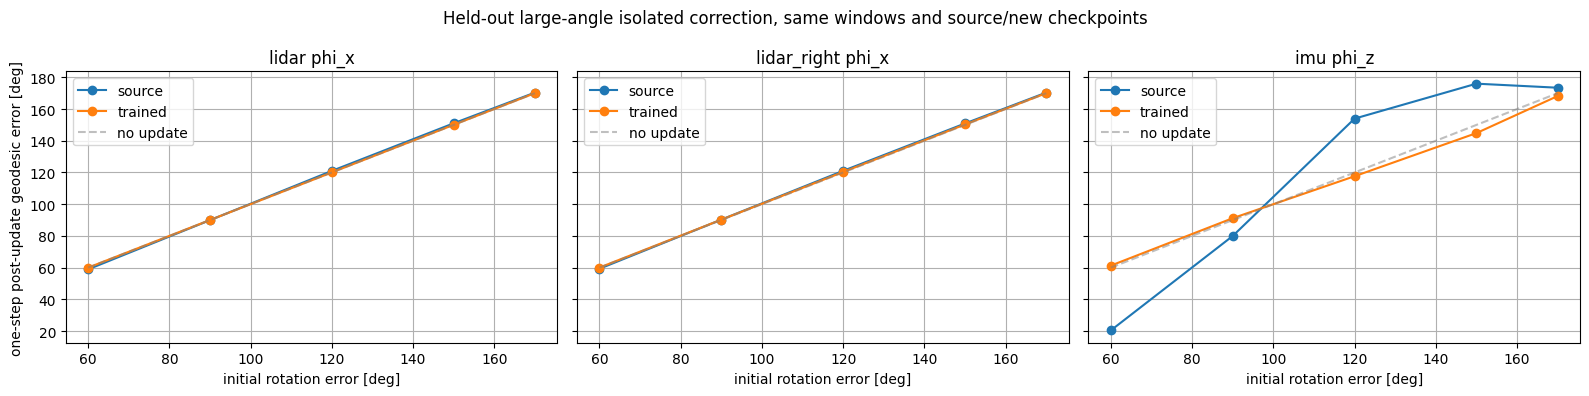

In [38]:
from obscalib.geometry.lie import so3_exp


def so3_geodesic_deg(R_est, R_true):
    """Principal SO(3) geodesic angle in degrees, avoiding rotvec-component branch plots."""
    R_diff = R_true @ R_est.transpose(-1, -2)
    trace = R_diff.diagonal(dim1=-2, dim2=-1).sum(-1)
    return torch.rad2deg(torch.acos(((trace - 1.0) / 2.0).clamp(-1.0, 1.0)))

# Isolated X-rotation correction test with same held-out windows and exact target labels.
# 0/180 ambiguity check is NEVER based on raw rotvec sign alone.
ISOLATED_TEST_ANGLES_DEG = (60.0, 90.0, 120.0, 150.0, 170.0)
ISOLATED_TEST_WINDOWS = 25
ISOLATED_TEST_SEQUENCE = "Urban38"


def isolated_large_angle_metrics(checkpoint_path, sensor_key, axis_index, angle_deg):
    load_training_checkpoint(checkpoint_path, model=model, map_location=DEVICE, restore_rng_state=False)
    model.eval()
    dataset = ROT_SWEEP_DATASETS[ISOLATED_TEST_SEQUENCE]
    indices = list(dataset.window_indices_for_sequence(ISOLATED_TEST_SEQUENCE))[:ISOLATED_TEST_WINDOWS]
    errors_before, errors_after, angular_prediction = [], [], []
    with torch.inference_mode():
        for idx in indices:
            base = window_batch_to(collate_windows([dataset[idx]]), DEVICE, dtype=MODEL_DTYPE)
            gt = base.current_calibration
            perturb = {key: torch.zeros(1, 6, dtype=MODEL_DTYPE, device=DEVICE) for key in CALIBRATION_KEYS}
            tau = {key: torch.zeros(1, 1, dtype=MODEL_DTYPE, device=DEVICE) for key in CALIBRATION_KEYS}
            perturb[sensor_key][0, axis_index] = np.deg2rad(angle_deg)
            wrong = apply_prior_perturbation(gt, perturb, tau)
            case = clone_window_with_calibration(base, wrong)
            pred = window_step(case, calibration=wrong).model_output.predictions[sensor_key]
            R_current = wrong[sensor_key].transform[:, :3, :3]
            R_true = gt[sensor_key].transform[:, :3, :3]
            R_after = so3_exp(pred.delta_xi[:, :3]) @ R_current
            errors_before.append(float(so3_geodesic_deg(R_current, R_true).item()))
            errors_after.append(float(so3_geodesic_deg(R_after, R_true).item()))
            angular_prediction.append(float(torch.rad2deg(torch.linalg.vector_norm(pred.delta_xi[:, :3], dim=-1)).item()))
    return dict(before=np.mean(errors_before), after=np.mean(errors_after), prediction=np.mean(angular_prediction), improvement_fraction=np.mean(np.asarray(errors_after) < np.asarray(errors_before)))


if BEST_CHECKPOINT_PATH.is_file():
    isolated_results = []
    for sensor_key in ("lidar", "lidar_right", "imu"):
        axis_index = 0 if sensor_key != "imu" else 2
        for angle_deg in ISOLATED_TEST_ANGLES_DEG:
            a = isolated_large_angle_metrics(RESUME_CHECKPOINT, sensor_key, axis_index, angle_deg)
            b = isolated_large_angle_metrics(BEST_CHECKPOINT_PATH, sensor_key, axis_index, angle_deg)
            isolated_results.append(dict(sensor=sensor_key, angle=angle_deg, source=a, trained=b))
            print(f"{sensor_key:12s} phi_{'x' if axis_index==0 else 'z'} {angle_deg:5.0f}° | source after={a['after']:7.2f}° | trained after={b['after']:7.2f}° | improvement fraction source={a['improvement_fraction']:.2f}, trained={b['improvement_fraction']:.2f}")
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
    for ax, sensor_key in zip(axes, ("lidar", "lidar_right", "imu")):
        subset = [x for x in isolated_results if x['sensor']==sensor_key]
        for label in ('source','trained'):
            ax.plot([x['angle'] for x in subset], [x[label]['after'] for x in subset], '-o', label=label)
        ax.plot([x['angle'] for x in subset], [x['angle'] for x in subset], '--', color='grey', alpha=.5, label='no update')
        ax.set_title(sensor_key + (' phi_z' if sensor_key=='imu' else ' phi_x'))
        ax.set_xlabel('initial rotation error [deg]'); ax.grid(True); ax.legend()
    axes[0].set_ylabel('one-step post-update geodesic error [deg]')
    fig.suptitle('Held-out large-angle isolated correction, same windows and source/new checkpoints')
    fig.tight_layout(); plt.show()
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)

## 29. Identical sequential rollouts from the source and fine-tuned checkpoints
Run both networks on the **same Urban38 windows and same initial priors**, especially LiDAR X rotations at 150° and 170°. We plot true geodesic rotation error in [0°, 180°] instead of the potentially discontinuous individual components of `Log(R)`. **Do not apply `rho`: the translation head was not trained.** This rollout holds the stored translation column fixed, though a future translation-aware model should use an SE(3)-consistent update.

Rollout scenario: lidar_x_150
  source_002.10  : lidar        angle(first/final)=149.82°/172.40°, fraction >150°=0.95, tau final=15.22 ms
  trained_002.11 : lidar        angle(first/final)=150.14°/164.66°, fraction >150°=0.93, tau final=2.53 ms


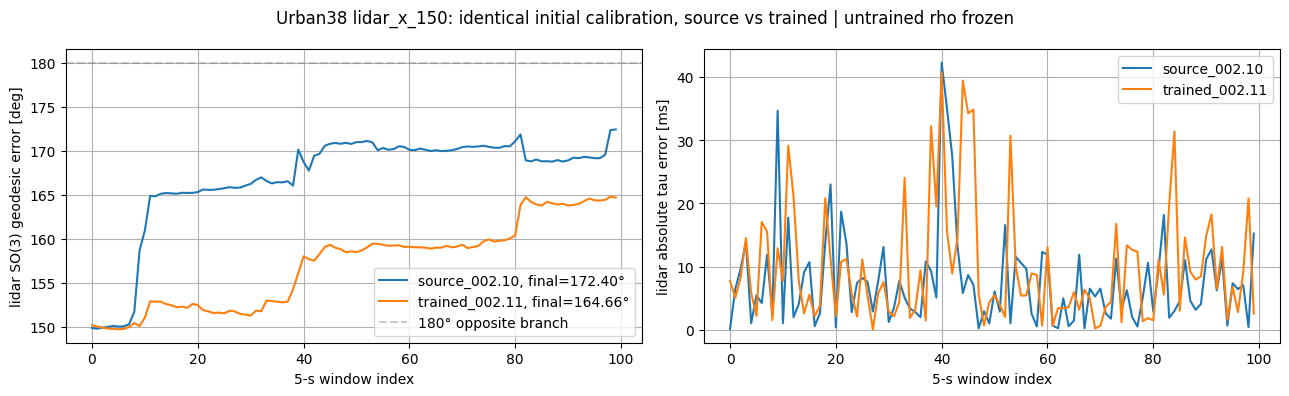

Rollout scenario: lidar_x_170
  source_002.10  : lidar        angle(first/final)=169.80°/173.38°, fraction >150°=1.00, tau final=15.04 ms
  trained_002.11 : lidar        angle(first/final)=170.13°/177.89°, fraction >150°=1.00, tau final=1.65 ms


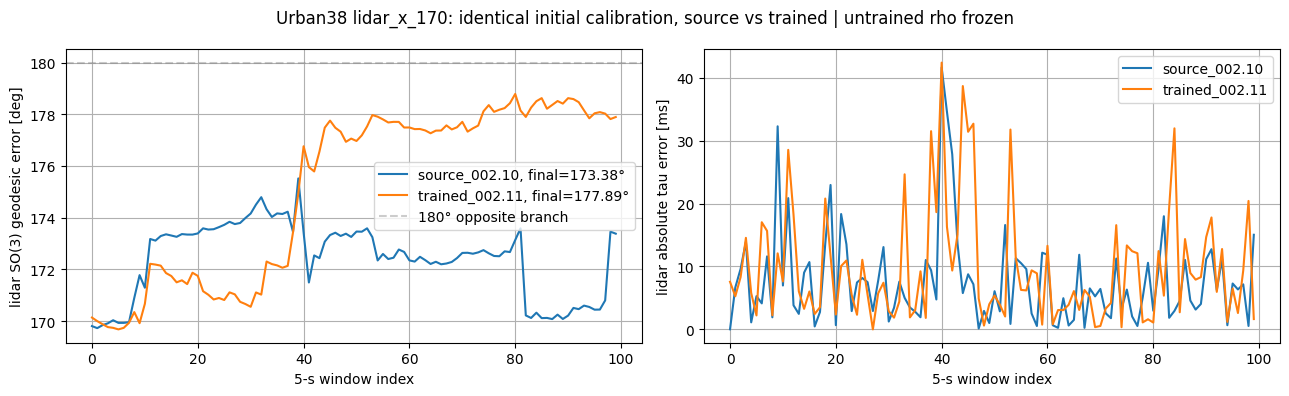

Rollout scenario: lidar_right_x_150
  source_002.10  : lidar_right  angle(first/final)=149.80°/176.37°, fraction >150°=0.97, tau final=3.79 ms
  trained_002.11 : lidar_right  angle(first/final)=149.99°/163.85°, fraction >150°=0.92, tau final=7.38 ms


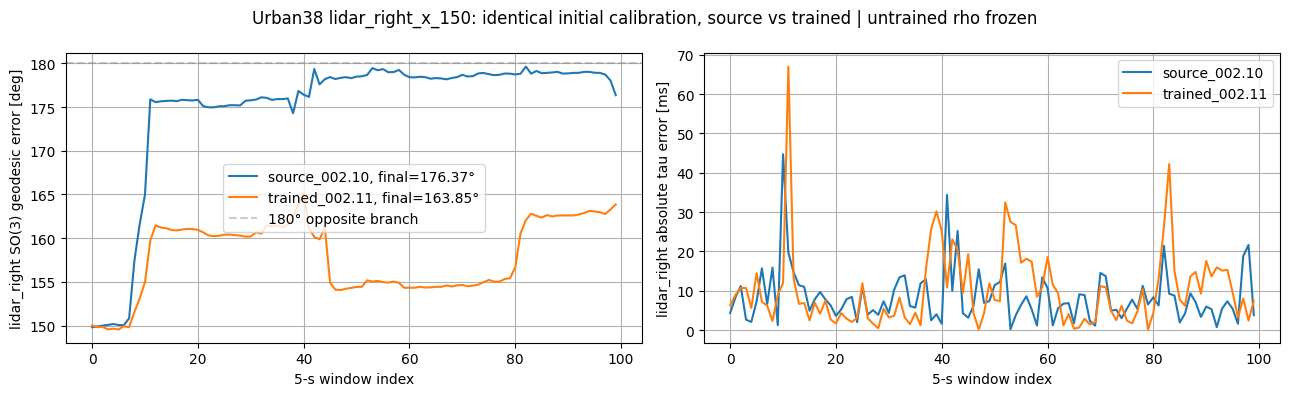

Rollout scenario: imu_z_150
  source_002.10  : imu          angle(first/final)=173.59°/179.67°, fraction >150°=1.00, tau final=2.89 ms
  trained_002.11 : imu          angle(first/final)=143.99°/108.21°, fraction >150°=0.00, tau final=2.18 ms


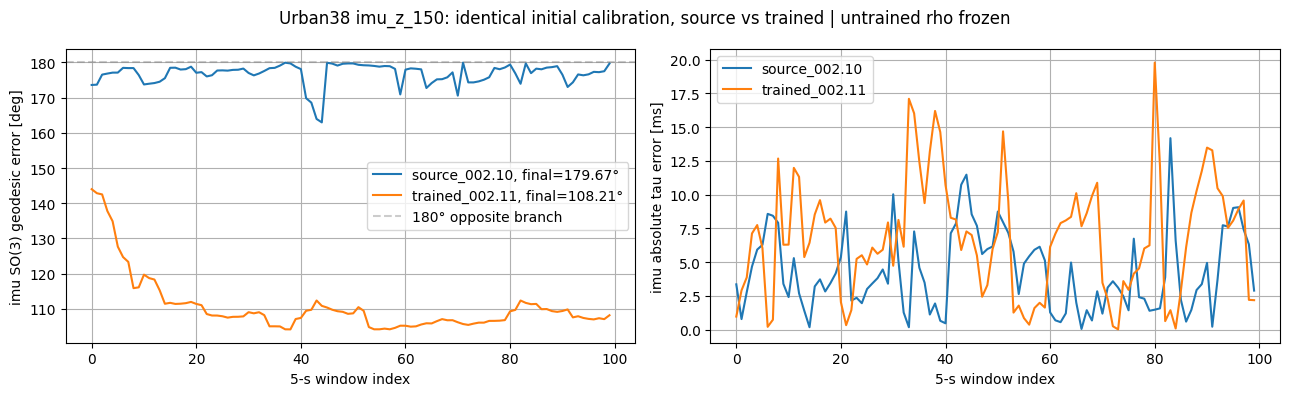

In [39]:
# Matched sequential rollouts of the ORIGINAL model and the NEW model.
# The translation rho head was not supervised; ignore it and hold the transform translation column fixed.
from obscalib.geometry.lie import so3_exp

ROLLOUT_SEQUENCE = "Urban38"
ROLLOUT_NUM_WINDOWS = 100      # Increase to None for all windows after initial verification.
ROLLOUT_START_WINDOW = 0
ROLLOUT_PLOT_SCENARIOS = ("lidar_x_150", "lidar_x_170", "lidar_right_x_150", "imu_z_150")
ROLLOUT_SCENARIOS = {
    "lidar_x_150": ("lidar", (1.0, 0.0, 0.0), 150.0),
    "lidar_x_170": ("lidar", (1.0, 0.0, 0.0), 170.0),
    "lidar_right_x_150": ("lidar_right", (1.0, 0.0, 0.0), 150.0),
    "imu_z_150": ("imu", (0.0, 0.0, 1.0), 150.0),
    # The two LiDARs can also start wrong simultaneously. This is an optional OOD rollout below.
}


def so3_geodesic_deg(R_est, R_true):
    R_diff = R_true @ R_est.transpose(-1, -2)
    trace = R_diff.diagonal(dim1=-2, dim2=-1).sum(-1)
    return torch.rad2deg(torch.acos(((trace - 1.0) / 2.0).clamp(-1.0, 1.0)))


def make_initial_rollout_calibration(reference, scenario):
    wrong_key, axis, degrees = ROLLOUT_SCENARIOS[scenario]
    carry = {key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for key, state in reference.items()}
    state = carry[wrong_key]
    delta = torch.tensor(axis, dtype=state.transform.dtype, device=state.transform.device).reshape(1, 3) * np.deg2rad(degrees)
    R_wrong = so3_exp(delta) @ state.transform[:, :3, :3]
    T_wrong = state.transform.clone()
    T_wrong[:, :3, :3] = R_wrong
    carry[wrong_key] = CalibrationState(transform=T_wrong, time_offset=state.time_offset.clone())
    return carry


def apply_rollout_rotation_tau_only(carry, model_output):
    """Apply predicted SO(3) + tau; freeze untrained translational extrinsics at their previous value."""
    updated = {}
    for key, state in carry.items():
        p = model_output.predictions[key]
        new_T = state.transform.clone()
        new_T[:, :3, :3] = so3_exp(p.delta_xi[:, :3]) @ state.transform[:, :3, :3]
        updated[key] = CalibrationState(transform=new_T, time_offset=state.time_offset + p.delta_tau)
    return updated


def run_calibration_rollout(checkpoint_path, scenario):
    load_training_checkpoint(checkpoint_path, model=model, map_location=DEVICE, restore_rng_state=False)
    model.eval()
    dataset = ROT_SWEEP_DATASETS[ROLLOUT_SEQUENCE]
    indices = list(dataset.window_indices_for_sequence(ROLLOUT_SEQUENCE))[ROLLOUT_START_WINDOW:]
    if ROLLOUT_NUM_WINDOWS is not None: indices = indices[:ROLLOUT_NUM_WINDOWS]
    if not indices: raise ValueError("No selected rollout windows")
    first = window_batch_to(collate_windows([dataset[indices[0]]]), DEVICE, dtype=MODEL_DTYPE)
    carry = make_initial_rollout_calibration(first.current_calibration, scenario)
    results = {key: {"rotation_deg": [], "tau_ms": [], "predicted_deg": []} for key in CALIBRATION_KEYS}
    with torch.inference_mode():
        for i in indices:
            window = window_batch_to(collate_windows([dataset[i]]), DEVICE, dtype=MODEL_DTYPE)
            prediction = window_step(window, calibration=carry).model_output
            carry = apply_rollout_rotation_tau_only(carry, prediction)
            for key in CALIBRATION_KEYS:
                reference = window.current_calibration[key]
                results[key]["rotation_deg"].append(float(so3_geodesic_deg(carry[key].transform[:, :3, :3], reference.transform[:, :3, :3]).item()))
                results[key]["tau_ms"].append(float((1000*(carry[key].time_offset-reference.time_offset)).abs().item()))
                results[key]["predicted_deg"].append(float(torch.rad2deg(torch.linalg.vector_norm(prediction.predictions[key].delta_xi[:, :3], dim=-1)).item()))
    return {key: {field: np.asarray(values) for field, values in fields.items()} for key, fields in results.items()}


if BEST_CHECKPOINT_PATH.is_file():
    rollout_comparisons = {}
    for scenario in ROLLOUT_PLOT_SCENARIOS:
        print("Rollout scenario:", scenario)
        rollout_comparisons[scenario] = {}
        for label, checkpoint in (("source_002.10", RESUME_CHECKPOINT), ("trained_002.11", BEST_CHECKPOINT_PATH)):
            rollout_comparisons[scenario][label] = run_calibration_rollout(checkpoint, scenario)
        faulty_sensor = ROLLOUT_SCENARIOS[scenario][0]
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))
        for label, data in rollout_comparisons[scenario].items():
            e = data[faulty_sensor]
            axes[0].plot(e["rotation_deg"], label=f"{label}, final={e['rotation_deg'][-1]:.2f}°")
            axes[1].plot(e["tau_ms"], label=label)
            initial = e["rotation_deg"][0]
            last = e["rotation_deg"][-1]
            near_wrong_basin = float(np.mean(e["rotation_deg"] > 150.0))
            print(f"  {label:15s}: {faulty_sensor:12s} angle(first/final)={initial:.2f}°/{last:.2f}°, fraction >150°={near_wrong_basin:.2f}, tau final={e['tau_ms'][-1]:.2f} ms")
        axes[0].axhline(180, linestyle="--", color="grey", alpha=.4, label="180° opposite branch")
        axes[0].set_ylabel(f"{faulty_sensor} SO(3) geodesic error [deg]")
        axes[1].set_ylabel(f"{faulty_sensor} absolute tau error [ms]")
        for ax in axes: ax.set_xlabel("5-s window index"); ax.grid(True); ax.legend()
        fig.suptitle(f"{ROLLOUT_SEQUENCE} {scenario}: identical initial calibration, source vs trained | untrained rho frozen")
        fig.tight_layout(); plt.show()
    # Restore new best weights for any subsequent notebook cells.
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
    model.eval()
else:
    print("Train or load a best checkpoint before paired rollouts.")

Running stochastic held-out inference: source_002.10 | /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.10_fine_coarse/best.pt
Running stochastic held-out inference: trained_002.11 | /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.11_large_rotation/best.pt

HIGH-ANGLE INFERENCE: each line contains independent held-out physical windows
model           sensor       mode       band          N   before    after     pred     gain   improve  reduce25
source_002.10   imu          isotropic  100-120     24   108.75    80.84    51.25    0.319    100.0%     45.8%
source_002.10   imu          isotropic  120-140     24   128.28   116.96    46.36    0.117     79.2%     16.7%
source_002.10   imu          isotropic  140-160     24   150.17   141.92    45.52    0.067     62.5%      8.3%
source_002.10   imu          isotropic  160-170     24   165.02   152.73    41.29    0.082     70.8%      0.0%
source_002.10 

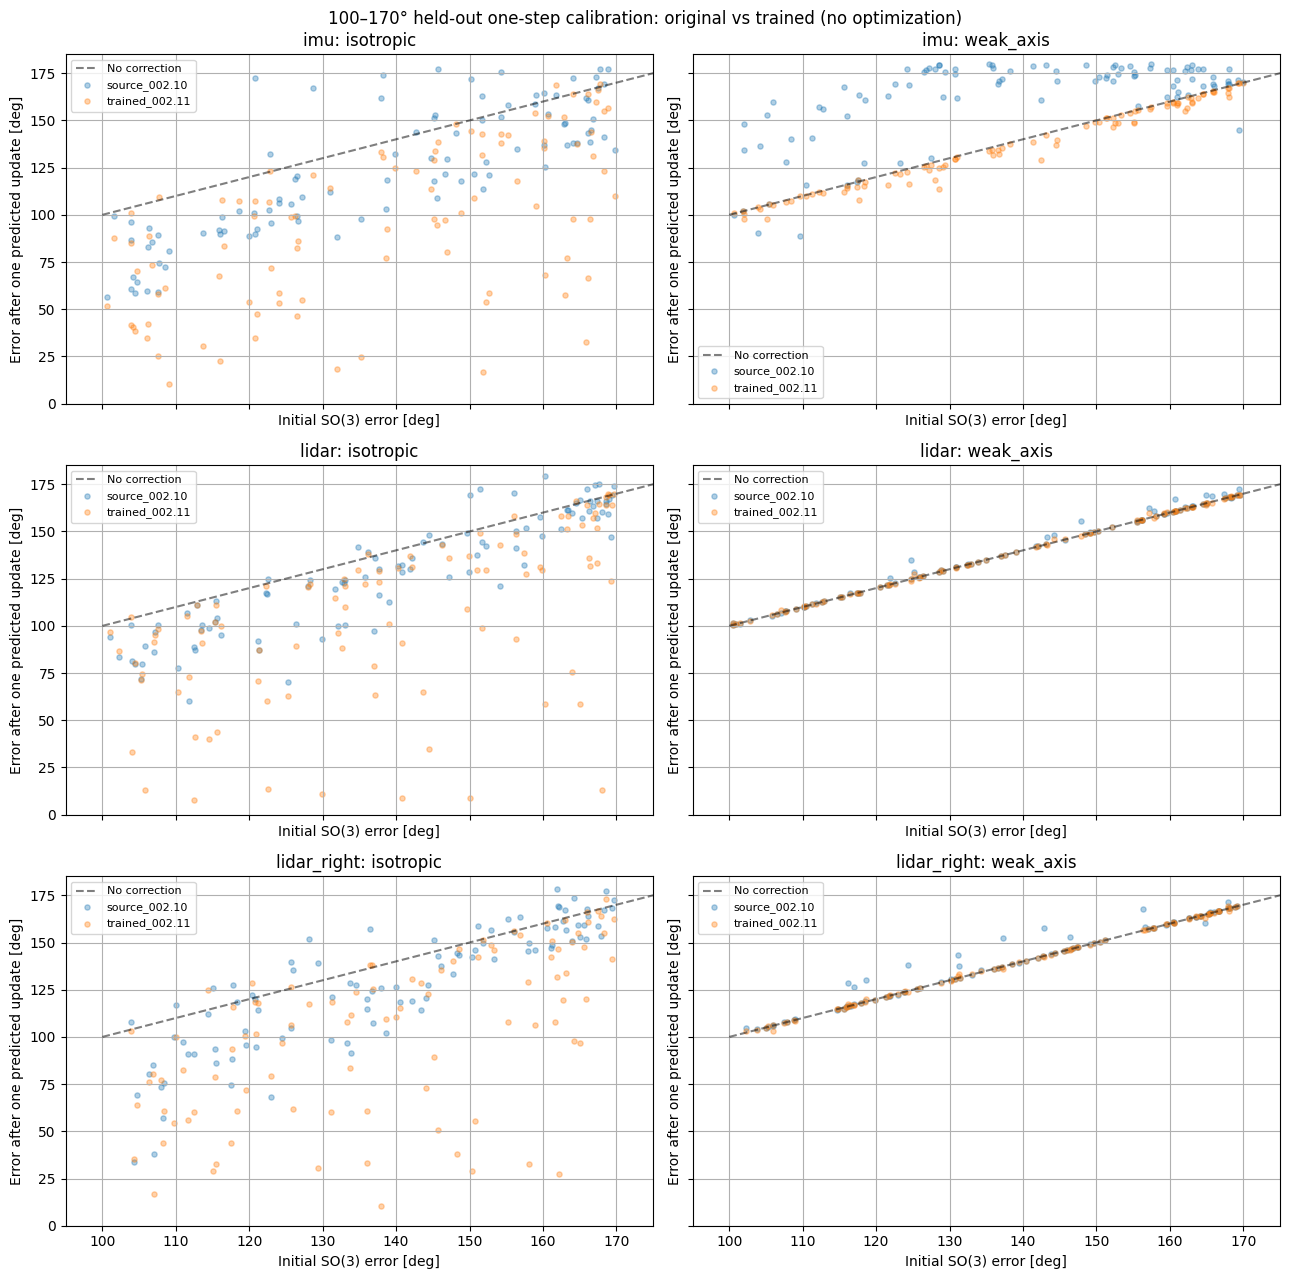

In [ ]:
# Inference-only stochastic high-angle diagnostic for notebook 25.
# Insert after Section 29 (rollouts). No gradients, training, or checkpoint writes.
from obscalib.geometry.lie import so3_exp

HIGH_ANGLE_BANDS_DEG = ((100.0, 120.0), (120.0, 140.0), (140.0, 160.0), (160.0, 170.0))
HIGH_ANGLE_SAMPLES_PER_BAND = 24
HIGH_ANGLE_BATCH_SIZE = 32
HIGH_ANGLE_SEED = TEST_PAIR_SEED + 800_001
HIGH_ANGLE_MODES = ("isotropic", "weak_axis")
HIGH_ANGLE_CHECKPOINTS = {"source_002.10": RESUME_CHECKPOINT, "trained_002.11": BEST_CHECKPOINT_PATH}

# Fix all physical windows and perturbations BEFORE evaluating either checkpoint.
rng = np.random.default_rng(HIGH_ANGLE_SEED)
high_angle_cases = {}
for sensor_key in CALIBRATION_KEYS:
    for axis_mode in HIGH_ANGLE_MODES:
        for lower, upper in HIGH_ANGLE_BANDS_DEG:
            indices = rng.choice(len(test_dataset), size=HIGH_ANGLE_SAMPLES_PER_BAND, replace=False)
            magnitudes = rng.uniform(lower, upper, size=HIGH_ANGLE_SAMPLES_PER_BAND)
            axes = rng.normal(size=(HIGH_ANGLE_SAMPLES_PER_BAND, 3))
            axes /= np.linalg.norm(axes, axis=-1, keepdims=True)
            if axis_mode == "weak_axis":
                axes[:] = (0.0, 0.0, 1.0) if sensor_key == "imu" else (1.0, 0.0, 0.0)
            axes *= rng.choice((-1.0, 1.0), size=(HIGH_ANGLE_SAMPLES_PER_BAND, 1))
            high_angle_cases[(sensor_key, axis_mode, lower, upper)] = (indices, np.deg2rad(magnitudes)[:, None] * axes)


def high_angle_geodesic_deg(R_a, R_b):
    '''SO(3) geodesic distance in degrees, computed from rotation matrices.'''
    R_error = R_a @ R_b.transpose(-1, -2)
    cos_angle = ((R_error.diagonal(dim1=-2, dim2=-1).sum(-1) - 1.0) / 2.0).clamp(-1.0, 1.0)
    return torch.rad2deg(torch.acos(cos_angle))


def evaluate_high_angle_checkpoint(checkpoint_path):
    '''Evaluate many held-out, single-sensor large-angle errors without optimization.'''
    load_training_checkpoint(checkpoint_path, model=model, map_location=DEVICE, restore_rng_state=False)
    model.eval()
    records = []

    with torch.inference_mode():
        for (sensor_key, axis_mode, lower, upper), (indices, delta_rotation) in high_angle_cases.items():
            for start in range(0, len(indices), HIGH_ANGLE_BATCH_SIZE):
                batch_indices = indices[start:start + HIGH_ANGLE_BATCH_SIZE]
                batch_delta = delta_rotation[start:start + HIGH_ANGLE_BATCH_SIZE]
                base = window_batch_to(collate_windows([test_dataset[int(i)] for i in batch_indices]), DEVICE, dtype=MODEL_DTYPE)
                truth = base.current_calibration
                batch_size = len(batch_indices)

                delta_xi = {key: torch.zeros(batch_size, 6, dtype=MODEL_DTYPE, device=DEVICE) for key in CALIBRATION_KEYS}
                delta_tau = {key: torch.zeros(batch_size, 1, dtype=MODEL_DTYPE, device=DEVICE) for key in CALIBRATION_KEYS}
                delta_xi[sensor_key][:, :3] = torch.as_tensor(batch_delta, device=DEVICE, dtype=MODEL_DTYPE)
                wrong = apply_prior_perturbation(truth, delta_xi, delta_tau)
                wrong_window = clone_window_with_calibration(base, wrong)

                output = window_step(wrong_window, calibration=wrong).model_output
                predicted_rotation = output.predictions[sensor_key].delta_xi[:, :3]
                R_before = wrong[sensor_key].transform[:, :3, :3]
                R_true = truth[sensor_key].transform[:, :3, :3]
                R_after = so3_exp(predicted_rotation) @ R_before

                before = high_angle_geodesic_deg(R_before, R_true).cpu().numpy()
                after = high_angle_geodesic_deg(R_after, R_true).cpu().numpy()
                prediction_norm = torch.rad2deg(torch.linalg.vector_norm(predicted_rotation, dim=-1)).cpu().numpy()
                # A gain of 1 means the prediction points exactly toward truth with full magnitude.
                projected_gain = (-(predicted_rotation * delta_xi[sensor_key][:, :3]).sum(-1) / delta_xi[sensor_key][:, :3].square().sum(-1)).cpu().numpy()

                for i in range(batch_size):
                    records.append(dict(sensor=sensor_key, mode=axis_mode, lower=lower, upper=upper, before=float(before[i]), after=float(after[i]), pred_norm=float(prediction_norm[i]), gain=float(projected_gain[i])))
    return records


high_angle_results = {}
try:
    for model_name, checkpoint_path in HIGH_ANGLE_CHECKPOINTS.items():
        print(f"Running stochastic held-out inference: {model_name} | {checkpoint_path}")
        high_angle_results[model_name] = evaluate_high_angle_checkpoint(checkpoint_path)
finally:
    # Keep later notebook cells on the newly trained best weights.
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
    model.eval()

print("\nHIGH-ANGLE INFERENCE: each line contains independent held-out physical windows")
print(f"{'model':15s} {'sensor':12s} {'mode':10s} {'band':10s} {'N':>4s} {'before':>8s} {'after':>8s} {'pred':>8s} {'gain':>8s} {'improve':>9s} {'reduce25':>9s}")
for model_name, rows in high_angle_results.items():
    for sensor_key in CALIBRATION_KEYS:
        for axis_mode in HIGH_ANGLE_MODES:
            for lower, upper in HIGH_ANGLE_BANDS_DEG:
                sub = [r for r in rows if (r['sensor'], r['mode'], r['lower'], r['upper']) == (sensor_key, axis_mode, lower, upper)]
                before = np.array([r['before'] for r in sub]); after = np.array([r['after'] for r in sub])
                print(f"{model_name:15s} {sensor_key:12s} {axis_mode:10s} {lower:3.0f}-{upper:<5.0f} {len(sub):4d} {before.mean():8.2f} {after.mean():8.2f} {np.mean([r['pred_norm'] for r in sub]):8.2f} {np.mean([r['gain'] for r in sub]):8.3f} {100*np.mean(after < before):8.1f}% {100*np.mean(after <= .75*before):8.1f}%")

fig, axes = plt.subplots(len(CALIBRATION_KEYS), len(HIGH_ANGLE_MODES), figsize=(13, 13), sharex=True, sharey=True)
for i, sensor_key in enumerate(CALIBRATION_KEYS):
    for j, axis_mode in enumerate(HIGH_ANGLE_MODES):
        ax = axes[i, j]
        ax.plot((100, 180), (100, 180), 'k--', alpha=0.5, label='No correction')
        for model_name, rows in high_angle_results.items():
            sub = [r for r in rows if r['sensor'] == sensor_key and r['mode'] == axis_mode]
            ax.scatter([r['before'] for r in sub], [r['after'] for r in sub], s=14, alpha=0.35, label=model_name)
        ax.set_title(f"{sensor_key}: {axis_mode}")
        ax.set_xlabel('Initial SO(3) error [deg]')
        ax.set_ylabel('Error after one predicted update [deg]')
        ax.set_xlim(95, 175); ax.set_ylim(0, 185)
        ax.grid(True); ax.legend(fontsize=8)
fig.suptitle('100–170° held-out one-step calibration: original vs trained (no optimization)')
fig.tight_layout(); plt.show()


## 30. Interpretation

- A repeated minimum at **0° and 180°** in the rotational residual suggests a non-unique extrinsic solution *for this motion and residual*. It is a global identifiability warning, not proof that the full three-sensor data has exactly the same ambiguity.
- A small Hessian eigenvalue near an optimum represents **local** poor observability. A distinct 180° optimum may be far away and is generally **not visible in a local Hessian**. Both diagnostics are needed.
- Rotations at ±360° are exactly the same point on SO(3). Near ±180° the logarithm's principal branch flips. Test actual rotation matrices and geodesic errors, never a raw `phi_x=+180` label by itself.
- To declare success, look for held-out isolated LiDAR X correction **and** rollout convergence to near 0°, not simply lower train or stochastic loss. Compare the familiar-regime holdout to guard against forgetting the useful `002.10` checkpoint.